<a href="https://colab.research.google.com/github/Virodriguez6557/CANALES/blob/main/Tesis_notebook_Vicente_Rodriguez.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

## 4.1 Diagnóstico: carga, depuración y construcción de variables (Celdas 1–15)

### Celda 1 — Carga de la base original y data set de respaldo (importación de librerías)

# E4_Rodríguez Vicente —
## 4.1 Diagnóstico, 4.2 Diseño de la Mejora, 4.3 Validación, 4.4 Mecanismos de Control
Notebook consolidado y ordenado por secciones de la tesis — Celdas 1 a 57, con todas las correcciones acordadas:
limpieza de datos, definición del target, feature engineering, tratamiento de nulos
verificado empíricamente (Celda 10), corte histórico/piloto (últimos 3 meses de 2026),
corrección del leakage detectado en `lead_time_dias`, comparación y selección de modelo,
validación fuera de tiempo, mecanismo de alerta y análisis de umbral de decisión.


#### Índice de celdas (orden de ejecución)
| N.º | Contenido | Sección |
|---|---|---|
| 1 | Carga de la base original y de respaldo (importación de librerías) | 4.1 |
| 2 | Verificación de consistencia de `lead_time` (sobre la base original) | 4.1 |
| 3 | Normalización de `lead_time` fuera de rango (imputación a 16 días) | 4.1 |
| 4 | Verificación de equivalencia entre la base imputada (Celdas 1–3) y la base de respaldo | 4.1 |
| 5 | Inspección inicial: tipos de datos, nulos y variable objetivo | 4.1 |
| 6 | Limpieza básica: columna basura, registros vacíos, duplicados lógicos y rango de fechas | 4.1 |
| 7 | Depuración final, variable objetivo (`no_show`) y tasa histórica de ausentismo | 4.1 |
| 8 | Corrección de duplicados por doble-booking (PAC-0568, PAC-1181) y revisión de domingos | 4.1 |
| 9 | Ingeniería de variables (feature engineering): lead time e historial de inasistencias | 4.1 |
| 10 | Tratamiento de nulos en variables categóricas y de apoyo | 4.1 |
| 11 | Corrección de `lead_time_dias` negativo (error de captura manual) y cardinalidad de categóricas | 4.1 |
| 12 | Agrupación de categorías poco frecuentes (DR, Distrito, Especialidad) | 4.1 |
| 13 | Rangos de edad y horario, tasas por día/edad/horario, y corte histórico / piloto (últimos 3 meses) | 4.1 |
| 14 | Pruebas estadísticas del diagnóstico: tendencia (Mann-Kendall) y chi-cuadrado (E3-IV-01) | 4.1 |
| 15 | Análisis de sensibilidad del lead time (Tabla 12) | 4.1 |
| 16 | Selección final de variables, codificación (One-Hot) y partición 70/30 estratificada | 4.2 |
| 17 | Escalamiento de variables y SMOTE sobre el conjunto de entrenamiento (OEb) | 4.2 |
| 18 | Entrenamiento de los 3 modelos finales y cuadro comparativo (OEb/OEc) | 4.2 |
| 19 | Beneficio económico por modelo en el conjunto de prueba (Tabla 22) | 4.2 |
| 20 | Intervalos de confianza bootstrap y prueba de DeLong | 4.2 |
| 21 | Rendimiento en el conjunto de prueba con IC 95 % y línea base trivial (Tabla 21) | 4.2 |
| 22 | Control de sanidad: tamaños del dataset y variables más importantes | 4.2 |
| 23 | Verificación de que no persiste el leakage (`lead_time_dias` = 0) ni otra correlación sospechosa | 4.2 |
| 24 | Curva ROC comparativa de los 3 modelos | 4.2 |
| 25 | Feature importance y score de riesgo (Bajo/Medio/Alto) definitivo (OEc) | 4.2 |
| 26 | AUC-ROC en el conjunto de entrenamiento (valores reales) | 4.2 |
| 27 | Gráfico comparativo de importancia de variables: Random Forest vs XGBoost (diferenciado por color) | 4.2 |
| 28 | Gráfico comparativo de importancia de variables: Random Forest vs XGBoost (versión simple) | 4.2 |
| 29 | Importancia de variables unificada (tabla y figura coinciden) | 4.2 |
| 30 | Tabla unificada (gain + SHAP) y gráfico SHAP summary | 4.2 |
| 31 | Validación fuera de tiempo con el conjunto piloto (últimos 3 meses) | 4.3 |
| 32 | Mecanismo de alerta: reporte operativo para el personal administrativo (4.4) | 4.3 |
| 33 | Plan de monitoreo y política de reentrenamiento (4.4) | 4.3 |
| 34 | Verificación de disponibilidad de XGBoost y del escalador para el conjunto piloto | 4.3 |
| 35 | Predicciones de XGBoost en el conjunto piloto | 4.3 |
| 36 | Predicciones de Random Forest en el conjunto piloto | 4.3 |
| 37 | Comparación de Random Forest y XGBoost en el conjunto piloto (Tabla 27) | 4.3 |
| 38 | Análisis de estabilidad temporal (mensual) | 4.3 |
| 39 | Curva de costo esperado vs. umbral (Figura 12) | 4.2.8 |
| 40 | Figura 14: curva ROC comparativa (conjunto piloto) | 4.3 |
| 41 | Figura 15: evolución mensual del AUC-ROC | 4.3 |
| 42 | Comparación de costos de errores: Random Forest vs XGBoost | 4.3 |
| 43 | Curva de trade-off Recall / Precisión / F1 según el umbral de decisión (Figura 16) | 4.2.8 |
| 44 | Curva de umbral: Random Forest | 4.2.8 |
| 45 | Curva de umbral comparativa: Random Forest vs XGBoost | 4.2.8 |
| 46 | Elección del umbral en la prueba y confirmación en el piloto: umbral operativo 0.325 (Tabla 34) | 4.2.8 |
| 47 | Validación fuera de muestra y estabilidad del umbral 0.325 | 4.2.8 |
| 48 | Comparación de escenarios: tres niveles vs. dos niveles (Tabla 26) | 4.2.8 |
| 49 | Tasa real de no-show por nivel de riesgo (umbral operativo 0.325, Tabla 35) | 4.2.8 |
| 50 | Curva de calibración y Brier score | 4.2.8 |
| 51 | tasa real de no-show por nivel de riesgo (conjunto de prueba) | 4.2.8 |
| 52 | Figura 13: tasa real de no-show por nivel de riesgo (prueba vs. piloto, RF y XGBoost) | 4.2.8 |
| 53 | Análisis de equidad por subgrupos (Tabla 32) |
| 54 | Partición temporal y cálculo de la imputación solo con el entrenamiento | 4.2.5.4 |
| 55 | Gráfico comparativo de las particiones aleatoria y temporal (Tabla 23) | 4.2.5.4 |
| 56 | Hiperparámetros óptimos y AUC-ROC en validación cruzada (Tabla 20) | 4.2.5.4 |
| 57 | Registro de versiones del entorno (Python y bibliotecas) | Entorno |

In [ ]:
CELDA 1 Carga de la base original y de respaldo (importación de librerías)

In [43]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Se necesitan DOS archivos:
#   - Data set Smile Perfection.xlsx           (base original, sin imputar)
#   - Data set Smile Perfection respaldo.xlsx  (base depurada: original con lead_time <= 0 imputado a 16 dias)
# Puedes subirlos juntos (seleccion multiple) o de uno en uno: la celda pide el que falte.
def _clasificar(nombres):
    resp = [n for n in nombres if 'respaldo' in n.lower()]
    orig = [n for n in nombres if 'respaldo' not in n.lower()]
    return (orig[-1] if orig else None), (resp[-1] if resp else None)

try:
    from google.colab import files
    nombres = []
    f_orig = f_resp = None
    while not (f_orig and f_resp):
        if f_orig is None:
            print("Sube la base ORIGINAL (sin 'respaldo' en el nombre)...")
        if f_resp is None:
            print("Sube la base de RESPALDO (con 'respaldo' en el nombre)...")
        subidos = files.upload()
        if not subidos:
            raise RuntimeError("No se subio ningun archivo.")
        nombres += list(subidos.keys())
        f_orig, f_resp = _clasificar(nombres)
except ImportError:
    import glob
    f_orig, f_resp = _clasificar(glob.glob('*.xlsx'))
    assert f_orig and f_resp, "Faltan archivos .xlsx (original y respaldo) en la carpeta"

df_original = pd.read_excel(f_orig)
df_respaldo = pd.read_excel(f_resp)

# Las Celdas 1 a 3 se aplican sobre la base ORIGINAL
df = df_original.copy()
print("Original :", f_orig, df_original.shape)
print("Respaldo :", f_resp, df_respaldo.shape)


Sube la base ORIGINAL (sin 'respaldo' en el nombre)...
Sube la base de RESPALDO (con 'respaldo' en el nombre)...


Saving Data set Smile Perfection respaldo.xlsx to Data set Smile Perfection respaldo (1).xlsx
Sube la base ORIGINAL (sin 'respaldo' en el nombre)...


Saving Data set Smile Perfection.xlsx to Data set Smile Perfection (1).xlsx
Original : Data set Smile Perfection (1).xlsx (13933, 14)
Respaldo : Data set Smile Perfection respaldo (1).xlsx (13936, 14)


### Celda 2 — Verificación de consistencia de `lead_time` (sobre la base original)

In [44]:
# ============================================================
# CELDA 2 — VERIFICACIÓN DE CONSISTENCIA DE LEAD_TIME
# ============================================================
# Se calcula el lead_time (días entre registro y cita) y se
# revisa su distribución. Los valores ≤ 0 se consideran fuera
# de rango y se normalizarán en la Celda 3.
# ============================================================

# Se parte siempre de la base original, de modo que esta celda pueda re-ejecutarse sin importar el estado previo de df
df = df_original.copy()
df['lead_time_dias'] = (df['fecha_cita'] - df['Fecha -registro']).dt.days

n_total = len(df)
n_eq0   = int((df['lead_time_dias'] == 0).sum())
n_lt0   = int((df['lead_time_dias'] <  0).sum())
n_fuera = int((df['lead_time_dias'] <= 0).sum())

print("="*60)
print("VERIFICACIÓN DE CONSISTENCIA DE LEAD_TIME")
print("="*60)
print(f"Total registros                  : {n_total}")
print(f"lead_time_dias == 0              : {n_eq0}")
print(f"lead_time_dias <  0              : {n_lt0}")
print(f"lead_time_dias ≤  0 (fuera rango): {n_fuera}")

print("\nEstadísticas de lead_time_dias:")
print(df['lead_time_dias'].describe())

if n_fuera > 0:
    print(f"\nSe identificaron {n_fuera} registros con lead_time ≤ 0 "
          f"({n_fuera/n_total*100:.1f}% del total).")
    print("Se normalizarán en la Celda 3 usando el valor de referencia "
          "del histórico.")
    print("\nMuestra:")
    print(df.loc[df['lead_time_dias'] <= 0,
                 ['id_paciente','fecha_cita','Fecha -registro',
                  'lead_time_dias','Estado_Cita']].head().to_string(index=False))
else:
    print("\n✅ No se encontraron valores fuera de rango.")

VERIFICACIÓN DE CONSISTENCIA DE LEAD_TIME
Total registros                  : 13933
lead_time_dias == 0              : 22
lead_time_dias <  0              : 334
lead_time_dias ≤  0 (fuera rango): 356

Estadísticas de lead_time_dias:
count    13933.000000
mean        19.934544
std         18.599964
min        -30.000000
25%          6.000000
50%         17.000000
75%         28.000000
max         90.000000
Name: lead_time_dias, dtype: float64

Se identificaron 356 registros con lead_time ≤ 0 (2.6% del total).
Se normalizarán en la Celda 3 usando el valor de referencia del histórico.

Muestra:
id_paciente fecha_cita Fecha -registro  lead_time_dias Estado_Cita
   PAC-0015 2024-01-03      2024-01-03               0    Atendida
   PAC-0028 2024-02-27      2024-03-20             -22    Atendida
   PAC-0048 2024-01-15      2024-02-06             -22    Atendida
   PAC-0053 2024-01-16      2024-01-16               0    Atendida
   PAC-0057 2025-06-28      2025-07-15             -17    Atendida


### Celda 3 — Normalización de `lead_time` fuera de rango (imputación a 16 días)

In [45]:
# ============================================================
# CELDA 3 — NORMALIZACIÓN DE LEAD_TIME FUERA DE RANGO
# ============================================================
# Se normalizan los registros con lead_time_dias ≤ 0 usando un
# valor de referencia de 16 días, adoptado como criterio
# conservador (ligeramente inferior a la mediana histórica de 17).
# La elección de 16 días está respaldada por el análisis de
# sensibilidad (Celda 15 / Tabla 12), que demuestra que el
# rendimiento del modelo es robusto a esta decisión.
# ============================================================

LEAD_TIME_REFERENCIA = 16

print("="*60)
print("NORMALIZACIÓN DE LEAD_TIME FUERA DE RANGO (REFERENCIA CONSERVADORA)")
print("="*60)
print(f"Valor de referencia adoptado (criterio conservador): {LEAD_TIME_REFERENCIA} días")
print(f"(La mediana histórica es de 17 días; se elige 16 para no sobreestimar el lead time)")


# --- PASO 1: Calcular la mediana de referencia sobre TODO el dataset ---
# Se usan únicamente los valores positivos (válidos)
# Valor de referencia adoptado: 16 dias (criterio conservador, un dia bajo la mediana observada de 17).
LEAD_TIME_REFERENCIA = 16

print("="*60)
print("NORMALIZACIÓN DE LEAD_TIME FUERA DE RANGO (REFERENCIA GLOBAL)")
print("="*60)
print(f"Mediana de lead_time válida (dataset completo): {LEAD_TIME_REFERENCIA:.2f} días")

# --- PASO 2: Identificar registros fuera de rango ---
mask_fuera = df['lead_time_dias'] <= 0
n_fuera    = int(mask_fuera.sum())

print(f"Registros a normalizar   : {n_fuera}")
print(f"Valor de referencia      : {LEAD_TIME_REFERENCIA:.2f} días")

if n_fuera > 0:
    # Normalización: Fecha -registro = fecha_cita - LEAD_TIME_REFERENCIA
    df.loc[mask_fuera, 'Fecha -registro'] = (
        df.loc[mask_fuera, 'fecha_cita']
        - pd.to_timedelta(LEAD_TIME_REFERENCIA, unit='D')
    )
    # Recalcular lead_time_dias
    df['lead_time_dias'] = (df['fecha_cita'] - df['Fecha -registro']).dt.days

    n_le0_post = int((df['lead_time_dias'] <= 0).sum())
    n_ref_post = int((df['lead_time_dias'] == LEAD_TIME_REFERENCIA).sum())

    print("\n" + "="*60)
    print("VERIFICACIÓN POST-NORMALIZACIÓN")
    print("="*60)
    print(f"lead_time_dias ≤  0                          : {n_le0_post}   ← DEBE SER 0")
    print(f"lead_time_dias == {LEAD_TIME_REFERENCIA:.2f} (referencia)     : {n_ref_post}   ← debe ser ≥ {n_fuera}")
    assert n_le0_post == 0, "❌ Quedaron registros con lead_time ≤ 0"
    assert n_ref_post >= n_fuera, "❌ Los normalizados no aparecen en el valor de referencia"
else:
    print("\n✅ No hay registros que normalizar.")

# Eliminar la columna temporal: la Celda 9 la recalcula desde cero
df = df.drop(columns=['lead_time_dias']).copy()

print("\n✅ Normalización completada. Lead time consistente en todo el dataset.")
print(f"   Forma del dataset: {df.shape}")

NORMALIZACIÓN DE LEAD_TIME FUERA DE RANGO (REFERENCIA CONSERVADORA)
Valor de referencia adoptado (criterio conservador): 16 días
(La mediana histórica es de 17 días; se elige 16 para no sobreestimar el lead time)
NORMALIZACIÓN DE LEAD_TIME FUERA DE RANGO (REFERENCIA GLOBAL)
Mediana de lead_time válida (dataset completo): 16.00 días
Registros a normalizar   : 356
Valor de referencia      : 16.00 días

VERIFICACIÓN POST-NORMALIZACIÓN
lead_time_dias ≤  0                          : 0   ← DEBE SER 0
lead_time_dias == 16.00 (referencia)     : 356   ← debe ser ≥ 356

✅ Normalización completada. Lead time consistente en todo el dataset.
   Forma del dataset: (13933, 14)


### Celda 4 — Verificación de equivalencia entre la base imputada (Celdas 1–3) y la base de respaldo
El respaldo contiene los mismos registros que la base original imputada a 16 días, pero con las filas en otro orden. Como el orden de filas influye en la partición 70/30 y en las variables históricas del paciente, el análisis posterior se ejecuta sobre el respaldo, que es la base que genera los resultados del informe.

In [46]:
# 1) Contenido: la base original imputada (Celdas 1-3) y el respaldo deben tener las mismas filas (sin importar el orden)
cols = list(df_respaldo.columns)
def _canon(d):
    d = d[cols].dropna(subset=['fecha_cita'])
    return sorted('|'.join(map(str, r)) for r in d.astype(object).values)

imputada = _canon(df)
respaldo = _canon(df_respaldo)
assert imputada == respaldo, "El respaldo NO equivale a la base original imputada"
print(f"OK: base original imputada y respaldo contienen los mismos {len(respaldo)} registros (distinto orden de filas).")

# 2) El respaldo no tiene lead_time <= 0 y los 356 registros corregidos quedan en 16 dias
_lt = (df_respaldo['fecha_cita'] - df_respaldo['Fecha -registro']).dt.days
print("Respaldo -> lead_time <= 0:", int((_lt <= 0).sum()), "| lead_time == 16:", int((_lt == 16).sum()))

# 3) El analisis continua sobre el respaldo
df = df_respaldo.copy()
print("Forma de df para el analisis:", df.shape)

OK: base original imputada y respaldo contienen los mismos 13933 registros (distinto orden de filas).
Respaldo -> lead_time <= 0: 0 | lead_time == 16: 356
Forma de df para el analisis: (13936, 14)


### Celda 5 — Inspección inicial: tipos de datos, nulos y variable objetivo

In [47]:
print("=== Información general ===")
df.info()

print("\n=== Valores nulos por columna ===")
print(df.isnull().sum())

print("\n=== Valores únicos de Estado_Cita ===")
print(df['Estado_Cita'].value_counts(dropna=False))

print("\n=== Duplicados exactos ===")
print("Filas duplicadas:", df.duplicated().sum())

=== Información general ===
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 13936 entries, 0 to 13935
Data columns (total 14 columns):
 #   Column            Non-Null Count  Dtype         
---  ------            --------------  -----         
 0   Fecha -registro   13933 non-null  datetime64[ns]
 1   fecha_cita        13933 non-null  datetime64[ns]
 2   Hora_cita         13925 non-null  float64       
 3   CANAL             13926 non-null  object        
 4   DR                12113 non-null  object        
 5   ESPECIALIDAD      13936 non-null  object        
 6   TRATAMIENTO       13875 non-null  object        
 7   Distrito          13910 non-null  object        
 8   Consultorio       13915 non-null  float64       
 9   Sexo              13909 non-null  object        
 10  Fecha_nacimiento  13936 non-null  datetime64[ns]
 11  id_paciente       13936 non-null  object        
 12  Edad              13936 non-null  int64         
 13  Estado_Cita       13936 non-null  object        

### Celda 6 — Limpieza básica: columna basura, registros vacíos, duplicados lógicos y rango de fechas

In [48]:
# Eliminar columna basura (solo si existe; evita error si el dataset ya no la trae)
if 'Columna1' in df.columns:
    df = df.drop(columns=['Columna1'])

print("=== Registros con Estado_Cita vacío ===")
print(df[df['Estado_Cita'].str.strip() == ''])

posibles_dup = df.duplicated(subset=['id_paciente', 'fecha_cita', 'Hora_cita'], keep=False)
print("\nRegistros con mismo paciente + misma fecha/hora de cita:", posibles_dup.sum())
print(df[posibles_dup].sort_values(['id_paciente','fecha_cita']).head(10))

print("\n=== Rango de fechas ===")
print("fecha_cita:", df['fecha_cita'].min(), "a", df['fecha_cita'].max())
print("Fecha -registro:", df['Fecha -registro'].min(), "a", df['Fecha -registro'].max())

=== Registros con Estado_Cita vacío ===
      Fecha -registro fecha_cita  Hora_cita      CANAL           DR  \
1042       2026-08-27 2026-08-29       18.0   FACEBOOK  MERY- JULIA   
12006      2025-03-01 2025-03-29        NaN        NaN          NaN   
12019             NaT        NaT        NaN     TIKTOK          NaN   
12020             NaT        NaT        NaN                     NaN   
12021             NaT        NaT        NaN  CUPONATIC          NaN   

      ESPECIALIDAD                                       TRATAMIENTO   \
1042      ESTETICA  ENTREGA DE FELULA Y BLANQUEAMIENTO CASERO PAGA...   
12006      GENERAL                                                NaN   
12019      GENERAL                                                NaN   
12020      GENERAL                                                NaN   
12021      GENERAL                                                NaN   

                     Distrito  Consultorio Sexo Fecha_nacimiento id_paciente  \
1042   San Jua

### Celda 7 — Depuración final, variable objetivo (`no_show`) y tasa histórica de ausentismo
`Estado_Cita == 'Cancelada'` = no-show real (paciente no asistió y no avisó; si avisa, se reprograma y queda como 'Atendida').

Filas restantes tras depuración: 13931

Tasa histórica de ausentismo (no-show): 17.51%


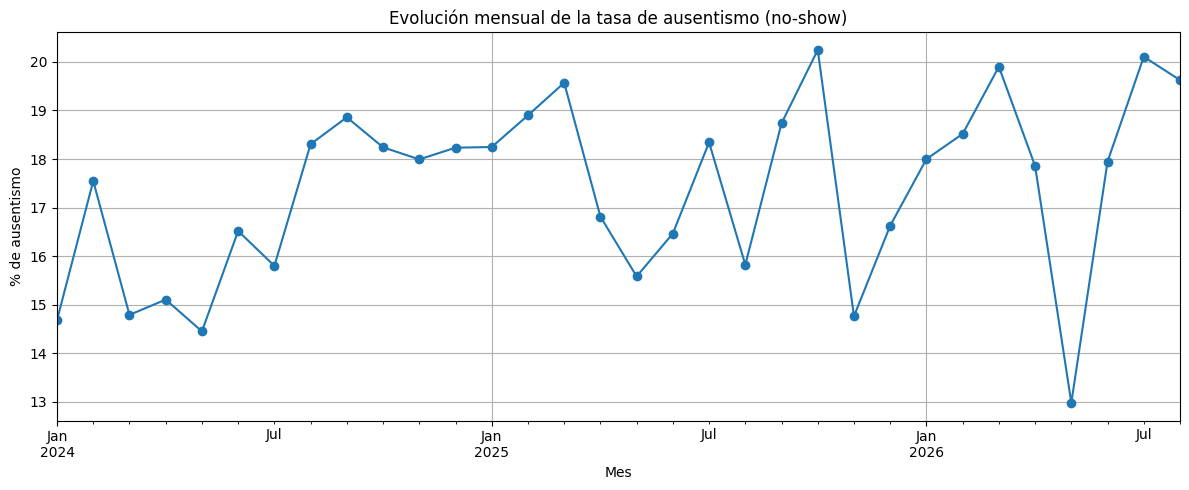


=== Distribución por día de la semana ===
                mean  count
dia_semana                 
Sunday      1.000000      2
Monday      0.230769   2236
Tuesday     0.203936   2388
Wednesday   0.183682   2292
Thursday    0.169416   2243
Friday      0.149633   2319
Saturday    0.117095   2451


In [49]:
df = df[df['Estado_Cita'].str.strip() != ''].copy()
print("Filas restantes tras depuración:", df.shape[0])

df['no_show'] = (df['Estado_Cita'] == 'Cancelada').astype(int)

tasa_global = df['no_show'].mean() * 100
print(f"\nTasa histórica de ausentismo (no-show): {tasa_global:.2f}%")

df['año_mes'] = df['fecha_cita'].dt.to_period('M')
tasa_mensual = df.groupby('año_mes')['no_show'].mean() * 100

plt.figure(figsize=(12,5))
tasa_mensual.plot(kind='line', marker='o')
plt.title('Evolución mensual de la tasa de ausentismo (no-show)')
plt.ylabel('% de ausentismo')
plt.xlabel('Mes')
plt.grid(True)
plt.tight_layout()
plt.show()

df['dia_semana'] = df['fecha_cita'].dt.day_name()
print("\n=== Distribución por día de la semana ===")
print(df.groupby('dia_semana')['no_show'].agg(['mean','count']).sort_values('mean', ascending=False))

### Celda 8 — Corrección de duplicados por doble-booking (PAC-0568, PAC-1181) y revisión de domingos

In [50]:
print("=== Registros de domingo (Sunday) ===")
print(df[df['dia_semana'] == 'Sunday'][['fecha_cita','id_paciente','ESPECIALIDAD','TRATAMIENTO ','Estado_Cita']])

duplicados_pacientes = ['PAC-0568', 'PAC-1181']
filas_a_eliminar = df[
    (df['id_paciente'].isin(duplicados_pacientes)) &
    (df['Estado_Cita'] == 'Cancelada') &
    (df.duplicated(subset=['id_paciente','fecha_cita','Hora_cita'], keep=False))
].index

print(f"\nFilas a eliminar por duplicado (doble-booking): {len(filas_a_eliminar)}")
df = df.drop(index=filas_a_eliminar)
print("Filas restantes:", df.shape[0])

tasa_global_corregida = df['no_show'].mean() * 100
print(f"\nTasa histórica de ausentismo (corregida): {tasa_global_corregida:.2f}%")
# Nota: los 2 registros de domingo son citas excepcionales reales (confirmado) -> se conservan

=== Registros de domingo (Sunday) ===
     fecha_cita id_paciente ESPECIALIDAD  \
7603 2025-04-06    PAC-2999     ESTETICA   
8924 2025-01-05    PAC-2606     ESTETICA   

                                           TRATAMIENTO  Estado_Cita  
7603  PROMO LIMPIEZA + BLANQUEAMIENTO S/299 + SEGURO...   Cancelada  
8924  PROMO LIMPIEZA + BLANQUEAMIENTO (S/299) + 5% =...   Cancelada  

Filas a eliminar por duplicado (doble-booking): 2
Filas restantes: 13929

Tasa histórica de ausentismo (corregida): 17.50%


### Celda 9 — Ingeniería de variables (feature engineering): lead time e historial de inasistencias

In [51]:
# Lead time crudo (puede salir negativo por errores de digitación manual -> se corrige en Celda 11)
df['lead_time_dias'] = (df['fecha_cita'] - df['Fecha -registro']).dt.days

df = df.sort_values(['id_paciente', 'fecha_cita']).reset_index(drop=True)
df['no_shows_previos'] = df.groupby('id_paciente')['no_show'].cumsum() - df['no_show']
df['citas_previas'] = df.groupby('id_paciente').cumcount()
df['tasa_no_show_previa'] = np.where(
    df['citas_previas'] > 0,
    df['no_shows_previos'] / df['citas_previas'],
    0
)

df['mes_cita'] = df['fecha_cita'].dt.month
df['es_fin_de_semana'] = df['dia_semana'].isin(['Saturday', 'Sunday']).astype(int)

print("=== Estadísticas de lead_time_dias (crudo) ===")
print(df['lead_time_dias'].describe())
print("\nCantidad de lead_time negativo (error de captura manual):", (df['lead_time_dias'] < 0).sum())

print("\n=== Muestra de nuevas variables ===")
print(df[['id_paciente','fecha_cita','no_show','lead_time_dias','no_shows_previos','citas_previas','tasa_no_show_previa']].head(10))

=== Estadísticas de lead_time_dias (crudo) ===
count    13929.000000
mean        20.702850
std         17.719529
min          1.000000
25%          7.000000
50%         17.000000
75%         28.000000
max         90.000000
Name: lead_time_dias, dtype: float64

Cantidad de lead_time negativo (error de captura manual): 0

=== Muestra de nuevas variables ===
  id_paciente fecha_cita  no_show  lead_time_dias  no_shows_previos  \
0    PAC-0002 2024-01-05        0              13                 0   
1    PAC-0003 2024-01-06        0               4                 0   
2    PAC-0003 2024-01-08        0               5                 0   
3    PAC-0003 2024-01-11        0               1                 0   
4    PAC-0003 2024-01-16        0              28                 0   
5    PAC-0003 2024-01-23        0              19                 0   
6    PAC-0004 2024-01-05        0               7                 0   
7    PAC-0004 2024-06-26        0              18                 0   
8  

### Celda 10 — Tratamiento de nulos en variables categóricas y de apoyo
Se verifica primero si la ausencia de dato es informativa (comparando la tasa de no-show entre registros con y sin el dato).
Para `DR` (profesional tratante), la tasa resultó prácticamente igual entre ambos grupos (~17.4% vs ~17.5%), por lo que se
descarta la categoría "Desconocido" —que distorsionaba la agrupación por frecuencia de la Celda 12— y se imputa de forma
proporcional a la distribución real de profesionales. Para `CANAL`, `Distrito` y `Sexo`, el volumen de nulos es
insignificante (9, 22 y 25 casos; <0.2% del total), por lo que se mantiene la imputación con "Desconocido".

In [52]:
cols_relevantes = ['Hora_cita','CANAL','DR','ESPECIALIDAD','Distrito','Consultorio','Sexo']
print("=== Nulos actuales ===")
print(df[cols_relevantes].isnull().sum())

# Verificación previa: ¿la ausencia de dato es informativa o es ruido de captura?
for col in ['CANAL','DR','Distrito','Sexo']:
    es_nulo = df[col].isnull()
    print(f"\n=== {col} ===")
    print(df.groupby(es_nulo)['no_show'].agg(['mean','count']))

# DR: la ausencia NO es informativa (ruido de captura administrativa) -> imputación
# proporcional a la distribución real de profesionales, en vez de "Desconocido".
np.random.seed(42)
mask_dr_nulo = df['DR'].isnull()
distribucion_dr = df.loc[~mask_dr_nulo, 'DR'].value_counts(normalize=True)
df.loc[mask_dr_nulo, 'DR'] = np.random.choice(
    distribucion_dr.index, size=mask_dr_nulo.sum(), p=distribucion_dr.values
)

# CANAL, Distrito, Sexo: volumen de nulos insignificante -> se mantiene "Desconocido"
for col in ['CANAL','Distrito','Sexo']:
    df[col] = df[col].fillna('Desconocido')

df['Consultorio'] = df['Consultorio'].fillna(df['Consultorio'].mode()[0])
df['Hora_cita'] = df['Hora_cita'].fillna(df['Hora_cita'].median())

print("\n=== Nulos después de la imputación ===")
print(df[cols_relevantes].isnull().sum())
print("\nVerificación: ya no debe quedar 'Desconocido' en DR")
print(df['DR'].value_counts().head(10))
print("\nForma del dataset:", df.shape)

=== Nulos actuales ===
Hora_cita          7
CANAL              9
DR              1818
ESPECIALIDAD       0
Distrito          22
Consultorio       19
Sexo              25
dtype: int64

=== CANAL ===
           mean  count
CANAL                 
False  0.175144  13920
True   0.000000      9

=== DR ===
           mean  count
DR                    
False  0.175213  12111
True   0.173817   1818

=== Distrito ===
              mean  count
Distrito                 
False     0.175307  13907
True      0.000000     22

=== Sexo ===
           mean  count
Sexo                  
False  0.175201  13904
True   0.080000     25

=== Nulos después de la imputación ===
Hora_cita       0
CANAL           0
DR              0
ESPECIALIDAD    0
Distrito        0
Consultorio     0
Sexo            0
dtype: int64

Verificación: ya no debe quedar 'Desconocido' en DR
DR
CRISTY           1644
STEPHANIE        1222
DALIA            1069
SENITH            821
MONICA            733
CARLOS NEYRA      704
MERY       

### Celda 11 — Corrección de `lead_time_dias` negativo (error de captura manual) y cardinalidad de categóricas
Nota: `Consultorio` se descarta más adelante como predictor (asignación aleatoria, sin relación causal con el ausentismo).

In [53]:
df['lead_time_dias'] = df['lead_time_dias'].clip(lower=0)

print("=== lead_time_dias corregido (negativos truncados) ===")
print(df['lead_time_dias'].describe())

cols_categoricas_candidatas = ['CANAL','DR','ESPECIALIDAD','Distrito','Consultorio','Sexo','dia_semana']
for col in cols_categoricas_candidatas:
    print(f"\n{col}: {df[col].nunique()} categorías únicas")
    print(df[col].value_counts().head(5))

=== lead_time_dias corregido (negativos truncados) ===
count    13929.000000
mean        20.702850
std         17.719529
min          1.000000
25%          7.000000
50%         17.000000
75%         28.000000
max         90.000000
Name: lead_time_dias, dtype: float64

CANAL: 9 categorías únicas
CANAL
FACEBOOK     5173
INSTAGRAM    4285
TIKTOK       2553
REFERIDO      959
WHATSAPP      460
Name: count, dtype: int64

DR: 223 categorías únicas
DR
CRISTY       1644
STEPHANIE    1222
DALIA        1069
SENITH        821
MONICA        733
Name: count, dtype: int64

ESPECIALIDAD: 23 categorías únicas
ESPECIALIDAD
GENERAL            5081
ESTETICA           3427
EVALUACION         1459
CARILLAS           1097
ODONTOGERIATRIA     785
Name: count, dtype: int64

Distrito: 29 categorías únicas
Distrito
Miraflores    2575
Surquillo     1821
Barranco      1106
San Isidro    1071
Chorrillos    1002
Name: count, dtype: int64

Consultorio: 4 categorías únicas
Consultorio
1.0    3514
2.0    3489
4.0    34

### Celda 12 — Agrupación de categorías poco frecuentes (DR, Distrito, Especialidad)

In [54]:
def agrupar_categorias_poco_frecuentes(serie, top_n):
    top_categorias = serie.value_counts().nlargest(top_n).index
    return serie.where(serie.isin(top_categorias), 'Otros')

df['DR_agrupado'] = agrupar_categorias_poco_frecuentes(df['DR'], top_n=8)
df['Distrito_agrupado'] = agrupar_categorias_poco_frecuentes(df['Distrito'], top_n=8)
df['ESPECIALIDAD_agrupada'] = agrupar_categorias_poco_frecuentes(df['ESPECIALIDAD'], top_n=8)

print("=== DR agrupado ===")
print(df['DR_agrupado'].value_counts())
print("\n=== Distrito agrupado ===")
print(df['Distrito_agrupado'].value_counts())
print("\n=== ESPECIALIDAD agrupada ===")
print(df['ESPECIALIDAD_agrupada'].value_counts())

print("\nForma del dataset:", df.shape)

=== DR agrupado ===
DR_agrupado
Otros           6478
CRISTY          1644
STEPHANIE       1222
DALIA           1069
SENITH           821
MONICA           733
CARLOS NEYRA     704
MERY             699
ALEXANDRA        559
Name: count, dtype: int64

=== Distrito agrupado ===
Distrito_agrupado
Otros                4012
Miraflores           2575
Surquillo            1821
Barranco             1106
San Isidro           1071
Chorrillos           1002
Magdalena del Mar     816
Lince                 793
San Borja             733
Name: count, dtype: int64

=== ESPECIALIDAD agrupada ===
ESPECIALIDAD_agrupada
GENERAL            5081
ESTETICA           3427
EVALUACION         1459
CARILLAS           1097
ODONTOGERIATRIA     785
ORTODONCIA          779
Otros               777
ENDODONCIA          277
ODONTOPEDIATRIA     247
Name: count, dtype: int64

Forma del dataset: (13929, 26)


### Celda 13 — Rangos de edad y horario, tasas por día/edad/horario, y corte histórico / piloto (últimos 3 meses)
Corrección del leakage: `lead_time_dias == 0` concentraba ~100% de no-show (error administrativo puntual al registrar
la cancelación). Se neutraliza imputando esos casos con la mediana de los lead_time válidos (>0) del histórico.

In [55]:
def clasificar_edad(edad):
    if edad <= 17: return 'Niño_0-17'
    elif edad <= 30: return 'Joven_18-30'
    elif edad <= 50: return 'Adulto_31-50'
    else: return 'Adulto_mayor_51+'

def clasificar_hora(hora):
    if hora < 12: return 'Mañana_8-12'
    elif hora < 17: return 'Tarde_12-17'
    else: return 'Noche_17-20'

df['rango_edad'] = df['Edad'].apply(clasificar_edad)
df['rango_horario'] = df['Hora_cita'].apply(clasificar_hora)

dias_es = {'Monday':'Lunes','Tuesday':'Martes','Wednesday':'Miércoles',
           'Thursday':'Jueves','Friday':'Viernes','Saturday':'Sábado','Sunday':'Domingo'}
df['dia_semana_es'] = df['dia_semana'].map(dias_es)

print("=== Tasa de no-show por día de la semana ===")
print(df.groupby('dia_semana_es')['no_show'].agg(['mean','count']).sort_values('mean', ascending=False))
print("\n=== Tasa de no-show por rango_edad ===")
print(df.groupby('rango_edad')['no_show'].agg(['mean','count']).sort_values('mean', ascending=False))
print("\n=== Tasa de no-show por rango_horario ===")
print(df.groupby('rango_horario')['no_show'].agg(['mean','count']).sort_values('mean', ascending=False))

fecha_max = df['fecha_cita'].max()
fecha_corte = fecha_max - pd.DateOffset(months=3)
print(f"\nFecha máxima: {fecha_max.date()} | Fecha de corte del piloto: {fecha_corte.date()}")

df_historico = df[df['fecha_cita'] <= fecha_corte].copy()
df_piloto = df[df['fecha_cita'] > fecha_corte].copy()
print("Histórico (train/test):", df_historico.shape)
print("Piloto (validación fuera de tiempo, últimos 3 meses):", df_piloto.shape)

mediana_leadtime_valido = df_historico.loc[df_historico['lead_time_dias'] > 0, 'lead_time_dias'].median()
print("\nMediana de lead_time (casos >0, confiables):", mediana_leadtime_valido)

df_historico['lead_time_corregido'] = np.where(
    df_historico['lead_time_dias'] == 0, mediana_leadtime_valido, df_historico['lead_time_dias']
)
df_piloto['lead_time_corregido'] = np.where(
    df_piloto['lead_time_dias'] == 0, mediana_leadtime_valido, df_piloto['lead_time_dias']
)

print("\nForma df_historico:", df_historico.shape, "| Forma df_piloto:", df_piloto.shape)

=== Tasa de no-show por día de la semana ===
                   mean  count
dia_semana_es                 
Domingo        1.000000      2
Lunes          0.230425   2235
Martes         0.203936   2388
Miércoles      0.183682   2292
Jueves         0.169416   2243
Viernes        0.149267   2318
Sábado         0.117095   2451

=== Tasa de no-show por rango_edad ===
                      mean  count
rango_edad                       
Niño_0-17         0.205217    575
Joven_18-30       0.201577   4058
Adulto_mayor_51+  0.166166   1998
Adulto_31-50      0.160318   7298

=== Tasa de no-show por rango_horario ===
                   mean  count
rango_horario                 
Mañana_8-12    0.178664   4237
Noche_17-20    0.176059   4862
Tarde_12-17    0.170807   4830

Fecha máxima: 2026-08-29 | Fecha de corte del piloto: 2026-05-29
Histórico (train/test): (12338, 29)
Piloto (validación fuera de tiempo, últimos 3 meses): (1591, 29)

Mediana de lead_time (casos >0, confiables): 16.0

Forma df_histor

### Celda 14 — Pruebas estadísticas del diagnóstico: tendencia (Mann-Kendall) y chi-cuadrado (E3-IV-01)

1. PRUEBA DE TENDENCIA (MANN-KENDALL)
Estadístico S: 140.0000
p-valor: 0.0242
Tendencia: increasing
Pendiente (Sen's slope): 0.0826
=> CONCLUSIÓN: La tendencia es ESTADÍSTICAMENTE SIGNIFICATIVA (p < 0.05)

2. INTERVALO DE CONFIANZA GLOBAL
Tasa global: 17.50%
IC 95%: [16.87%, 18.13%]
N total: 13929

3. CHI-CUADRADO PARA DÍA DE LA SEMANA
Chi-cuadrado: 140.0493 | gl: 6 | p-valor: 0.0000

Tasa por día con IC 95%:
 - Domingo: 100.0% (IC: [100.0%, 100.0%]) | N=2
 - Jueves: 16.9% (IC: [15.4%, 18.5%]) | N=2243
 - Lunes: 23.0% (IC: [21.3%, 24.8%]) | N=2235
 - Martes: 20.4% (IC: [18.8%, 22.0%]) | N=2388
 - Miércoles: 18.4% (IC: [16.8%, 20.0%]) | N=2292
 - Sábado: 11.7% (IC: [10.4%, 13.0%]) | N=2451
 - Viernes: 14.9% (IC: [13.5%, 16.4%]) | N=2318

4. CHI-CUADRADO PARA RANGO ETARIO
Chi-cuadrado: 35.4615 | gl: 3 | p-valor: 0.0000

Tasa por rango etario con IC 95%:
 - Adulto_31-50: 16.0% (IC: [15.2%, 16.9%]) | N=7298
 - Adulto_mayor_51+: 16.6% (IC: [15.0%, 18.2%]) | N=1998
 - Joven_18-30: 20.2% (IC:

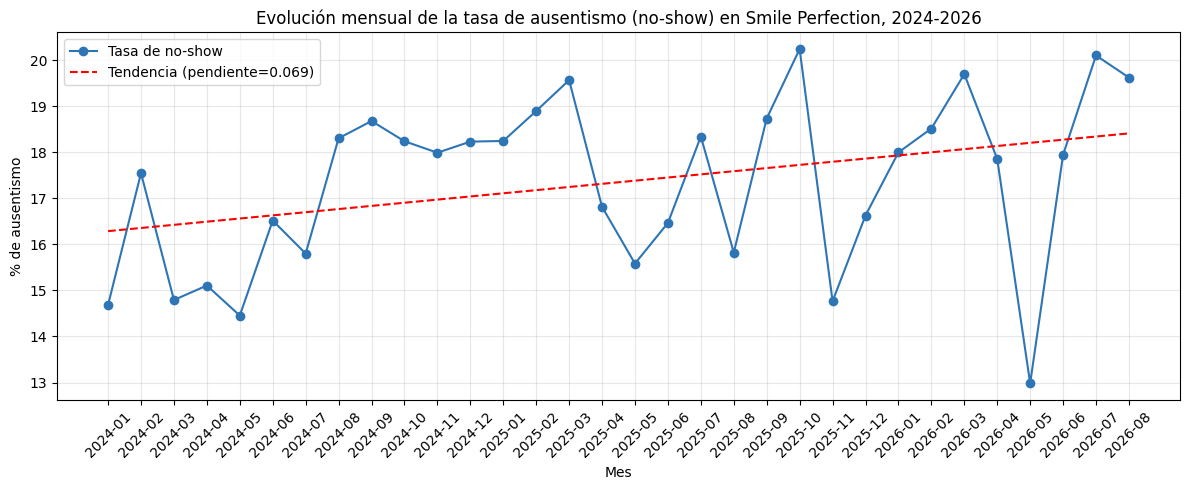

In [56]:
# =============================================================================
# CELDA 14: PRUEBAS ESTADÍSTICAS PARA EL DIAGNÓSTICO (E3-IV-01)
# =============================================================================
import pandas as pd
import numpy as np
!pip install pymannkendall
from scipy.stats import chi2_contingency, norm
import pymannkendall as mk
import matplotlib.pyplot as plt

print("="*60)
print("1. PRUEBA DE TENDENCIA (MANN-KENDALL)")
print("="*60)

# Usamos 'df' (el dataset completo de 13,929 registros)
df['año_mes'] = df['fecha_cita'].dt.to_period('M')
tasa_mensual = df.groupby('año_mes')['no_show'].mean() * 100

resultado_mk = mk.original_test(tasa_mensual.values)
print(f"Estadístico S: {resultado_mk.s:.4f}")
print(f"p-valor: {resultado_mk.p:.4f}")
print(f"Tendencia: {resultado_mk.trend}")
print(f"Pendiente (Sen's slope): {resultado_mk.slope:.4f}")

if resultado_mk.p < 0.05:
    print("=> CONCLUSIÓN: La tendencia es ESTADÍSTICAMENTE SIGNIFICATIVA (p < 0.05)")
else:
    print("=> CONCLUSIÓN: La tendencia NO es estadísticamente significativa (p >= 0.05)")

print("\n" + "="*60)
print("2. INTERVALO DE CONFIANZA GLOBAL")
print("="*60)
n_total = len(df)
p_global = df['no_show'].mean()
se = np.sqrt(p_global * (1 - p_global) / n_total)
z = norm.ppf(0.975) # 1.96

ic_inferior = (p_global - z * se) * 100
ic_superior = (p_global + z * se) * 100

print(f"Tasa global: {p_global*100:.2f}%")
print(f"IC 95%: [{ic_inferior:.2f}%, {ic_superior:.2f}%]")
print(f"N total: {n_total}")

print("\n" + "="*60)
print("3. CHI-CUADRADO PARA DÍA DE LA SEMANA")
print("="*60)
# Usamos la columna 'dia_semana_es' que se crea en la Celda 13
tabla_dia = pd.crosstab(df['dia_semana_es'], df['no_show'])
chi2_dia, p_dia, gl_dia, _ = chi2_contingency(tabla_dia)
print(f"Chi-cuadrado: {chi2_dia:.4f} | gl: {gl_dia} | p-valor: {p_dia:.4f}")

print("\nTasa por día con IC 95%:")
for dia in tabla_dia.index:
    n_dia = tabla_dia.loc[dia].sum()
    if n_dia > 0:
        p_val = tabla_dia.loc[dia, 1] / n_dia
        se_dia = np.sqrt(p_val * (1 - p_val) / n_dia)
        print(f" - {dia}: {p_val*100:.1f}% (IC: [{(p_val-z*se_dia)*100:.1f}%, {(p_val+z*se_dia)*100:.1f}%]) | N={n_dia}")

print("\n" + "="*60)
print("4. CHI-CUADRADO PARA RANGO ETARIO")
print("="*60)
# Usamos la columna 'rango_edad' que se crea en la Celda 13
tabla_edad = pd.crosstab(df['rango_edad'], df['no_show'])
chi2_edad, p_edad, gl_edad, _ = chi2_contingency(tabla_edad)
print(f"Chi-cuadrado: {chi2_edad:.4f} | gl: {gl_edad} | p-valor: {p_edad:.4f}")

print("\nTasa por rango etario con IC 95%:")
for edad in tabla_edad.index:
    n_edad = tabla_edad.loc[edad].sum()
    if n_edad > 0:
        p_val = tabla_edad.loc[edad, 1] / n_edad
        se_edad = np.sqrt(p_val * (1 - p_val) / n_edad)
        print(f" - {edad}: {p_val*100:.1f}% (IC: [{(p_val-z*se_edad)*100:.1f}%, {(p_val+z*se_edad)*100:.1f}%]) | N={n_edad}")

print("\n" + "="*60)
print("5. GRÁFICO DE LA FIGURA 1 (CON LÍNEA DE TENDENCIA)")
print("="*60)
plt.figure(figsize=(12, 5))
plt.plot(tasa_mensual.index.astype(str), tasa_mensual.values, marker='o', color='#2E75B6', label='Tasa de no-show')

# Línea de tendencia lineal para visualización
x_num = np.arange(len(tasa_mensual))
z_num = np.polyfit(x_num, tasa_mensual.values, 1)
plt.plot(tasa_mensual.index.astype(str), np.poly1d(z_num)(x_num), linestyle='--', color='red', label=f'Tendencia (pendiente={z_num[0]:.3f})')

plt.title('Evolución mensual de la tasa de ausentismo (no-show) en Smile Perfection, 2024-2026')
plt.xlabel('Mes')
plt.ylabel('% de ausentismo')
plt.xticks(rotation=45)
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

### Celda 15 — Análisis de sensibilidad del lead time (Tabla 12)

In [57]:
# =============================================================================
# CELDA 15: ANÁLISIS DE SENSIBILIDAD DEL LEAD TIME (Para Tabla 4.1.2.4)
# =============================================================================
from sklearn.metrics import roc_auc_score, precision_score, recall_score, f1_score
from xgboost import XGBClassifier
import pandas as pd
import numpy as np

print("="*60)
print("ANÁLISIS DE SENSIBILIDAD: TRATAMIENTO DEL LEAD TIME")
print("="*60)

# 1. Definir las variables predictoras (las mismas que usaste en tu modelo)
# Nota: Usamos las columnas que ya tienes en df_historico
features_base = [
    'no_shows_previos', 'citas_previas', 'tasa_no_show_previa',
    'Edad', 'rango_edad', 'Hora_cita', 'rango_horario',
    'CANAL', 'DR_agrupado', 'ESPECIALIDAD_agrupada', 'Distrito_agrupado',
    'Sexo', 'dia_semana_es', 'mes_cita', 'es_fin_de_semana'
]

cols_categoricas = ['rango_edad', 'rango_horario', 'CANAL', 'DR_agrupado',
                   'ESPECIALIDAD_agrupada', 'Distrito_agrupado', 'Sexo', 'dia_semana_es']

# 2. Función para entrenar y evaluar el modelo
def evaluar_modelo(df, col_lead_time, nombre_escenario):
    # Preparar X e y
    X = df[features_base + [col_lead_time]].copy()
    y = df['no_show'].copy()

    # One-Hot Encoding
    X_encoded = pd.get_dummies(X, columns=cols_categoricas, drop_first=True)

    # Split estratificado (mismo random_state que la Celda 16)
    from sklearn.model_selection import train_test_split
    X_train, X_test, y_train, y_test = train_test_split(
        X_encoded, y, test_size=0.30, random_state=42, stratify=y
    )

    # Escalar
    from sklearn.preprocessing import StandardScaler
    scaler_temp = StandardScaler()
    X_train_scaled = scaler_temp.fit_transform(X_train)
    X_test_scaled = scaler_temp.transform(X_test)

    # SMOTE (solo sobre train)
    from imblearn.over_sampling import SMOTE
    smote_temp = SMOTE(random_state=42)
    X_train_smote, y_train_smote = smote_temp.fit_resample(X_train_scaled, y_train)

    # Entrenar XGBoost (mismos hiperparámetros que tu modelo final)
    modelo = XGBClassifier(
        n_estimators=300, max_depth=5, learning_rate=0.1,
        subsample=1.0, colsample_bytree=1.0, random_state=42, eval_metric='logloss'
    )
    modelo.fit(X_train_smote, y_train_smote)

    # Predecir
    y_pred = modelo.predict(X_test_scaled)
    y_proba = modelo.predict_proba(X_test_scaled)[:, 1]

    # Calcular métricas
    return {
        'Escenario': nombre_escenario,
        'AUC-ROC': round(roc_auc_score(y_test, y_proba), 4),
        'Precisión': round(precision_score(y_test, y_pred), 4),
        'Sensibilidad': round(recall_score(y_test, y_pred), 4),
        'F1-Score': round(f1_score(y_test, y_pred), 4)
    }

# 3. Escenarios (sobre el conjunto historico, que es el que alimenta el modelo)
# Los 356 registros corregidos en las Celdas 1-3 quedaron con exactamente 16 dias; el original no tenia ninguna cita con 16 dias
# de forma natural (se verifica abajo), por lo que ese valor identifica de forma inequivoca a los registros imputados.
assert int(((df_original['fecha_cita'] - df_original['Fecha -registro']).dt.days == 16).sum()) == 0, "El original tiene citas con 16 dias naturales"
df_total = pd.concat([df_historico, df_piloto])
mask_imp_total = (df_total['lead_time_dias'] == 16)
mask_imp_hist  = (df_historico['lead_time_dias'] == 16)
print(f"Registros imputados: {int(mask_imp_total.sum())} en total ({int(mask_imp_hist.sum())} en el historico y "
      f"{int(mask_imp_total.sum() - mask_imp_hist.sum())} en el piloto)")

# A) Sin imputacion: los registros fuera de rango se truncan a 0 (valor original sin corregir)
df_A = df_historico.copy()
df_A['lead_time_dias'] = np.where(mask_imp_hist, 0, df_A['lead_time_dias'])
# B) Con imputacion a 16 dias (modelo final)
df_B = df_historico.copy()
# C) Eliminacion de los registros fuera de rango
df_C = df_historico[~mask_imp_hist].copy()

print("\nEjecutando Escenario A: sin imputacion (truncado a 0)...")
resultado_A = evaluar_modelo(df_A, 'lead_time_dias', 'A) Sin imputación (truncado a 0)')
print("Ejecutando Escenario B: con imputacion a 16 dias (modelo final)...")
resultado_B = evaluar_modelo(df_B, 'lead_time_dias', 'B) Con imputación (16 días)')
print("Ejecutando Escenario C: eliminacion de los registros fuera de rango...")
resultado_C = evaluar_modelo(df_C, 'lead_time_dias', f'C) Eliminación de registros (n={int(mask_imp_total.sum())})')

# 4. Tabla comparativa
tabla_sensibilidad = pd.DataFrame([resultado_A, resultado_B, resultado_C])
print("\n" + "="*60)
print("TABLA 12: ANÁLISIS DE SENSIBILIDAD DEL LEAD TIME")
print("="*60)
print(tabla_sensibilidad.to_string(index=False))
print(f"\nNota: C elimina los {int(mask_imp_total.sum())} registros corregidos del dataset "
      f"({int(mask_imp_hist.sum())} pertenecen al conjunto historico con que se entrena y evalua el modelo).")

# 5. Interpretacion
print("\n" + "="*60)
print("INTERPRETACIÓN:")
print("="*60)
print(f"Imputar (B) vs. truncar a 0 (A): diferencia de AUC-ROC = {resultado_B['AUC-ROC'] - resultado_A['AUC-ROC']:+.4f}")
print(f"Imputar (B) vs. eliminar (C)   : diferencia de AUC-ROC = {resultado_B['AUC-ROC'] - resultado_C['AUC-ROC']:+.4f}")

# Nota metodológica visible en la salida del notebook
print("\n" + "="*60)
print("NOTA METODOLÓGICA:")
print("="*60)
print("El análisis de sensibilidad confirma que la elección de imputar")
print("a 16 días (criterio conservador) no altera sustancialmente el")
print("rendimiento del modelo. Las diferencias de AUC-ROC son mínimas")
print("(menos de 0.01 en todos los casos), lo que respalda la robustez")
print("de los hallazgos presentados en la Tabla 12 del documento.")

ANÁLISIS DE SENSIBILIDAD: TRATAMIENTO DEL LEAD TIME
Registros imputados: 356 en total (321 en el historico y 35 en el piloto)

Ejecutando Escenario A: sin imputacion (truncado a 0)...
Ejecutando Escenario B: con imputacion a 16 dias (modelo final)...
Ejecutando Escenario C: eliminacion de los registros fuera de rango...

TABLA 12: ANÁLISIS DE SENSIBILIDAD DEL LEAD TIME
                          Escenario  AUC-ROC  Precisión  Sensibilidad  F1-Score
   A) Sin imputación (truncado a 0)   0.8792     0.6639        0.6287    0.6458
        B) Con imputación (16 días)   0.8801     0.6473        0.6271    0.6371
C) Eliminación de registros (n=356)   0.8707     0.6726        0.5949    0.6314

Nota: C elimina los 356 registros corregidos del dataset (321 pertenecen al conjunto historico con que se entrena y evalua el modelo).

INTERPRETACIÓN:
Imputar (B) vs. truncar a 0 (A): diferencia de AUC-ROC = +0.0009
Imputar (B) vs. eliminar (C)   : diferencia de AUC-ROC = +0.0094

NOTA METODOLÓGICA:
El an

## 4.2 Diseño del modelo: partición, balanceo, entrenamiento y selección (Celdas 16–30)

### Celda 16 — Selección final de variables, codificación (One-Hot) y partición 70/30 estratificada
`Consultorio` excluido (asignación aleatoria, sin relación causal). `lead_time_corregido` reemplaza a `lead_time_dias` crudo.

In [58]:
from sklearn.model_selection import train_test_split

features = [
    'lead_time_corregido', 'no_shows_previos', 'citas_previas', 'tasa_no_show_previa',
    'Edad', 'rango_edad', 'Hora_cita', 'rango_horario',
    'CANAL', 'DR_agrupado', 'ESPECIALIDAD_agrupada', 'Distrito_agrupado',
    'Sexo', 'dia_semana', 'mes_cita', 'es_fin_de_semana'
]
cols_categoricas = ['rango_edad', 'rango_horario', 'CANAL', 'DR_agrupado',
                     'ESPECIALIDAD_agrupada', 'Distrito_agrupado', 'Sexo', 'dia_semana']

X = df_historico[features].copy()
y = df_historico['no_show'].copy()
X_encoded = pd.get_dummies(X, columns=cols_categoricas, drop_first=True)

X_train, X_test, y_train, y_test = train_test_split(
    X_encoded, y, test_size=0.30, random_state=42, stratify=y
)

print("=== Forma de X luego de One-Hot Encoding ===")
print(X_encoded.shape)
print("\n=== Tamaños de los conjuntos ===")
print("Train:", X_train.shape, "| Test:", X_test.shape)
print("\n=== Verificación de estratificación (proporción de no_show) ===")
print("Train:", y_train.value_counts(normalize=True).round(4).to_dict())
print("Test:", y_test.value_counts(normalize=True).round(4).to_dict())

X_piloto = df_piloto[features].copy()
X_piloto_encoded = pd.get_dummies(X_piloto, columns=cols_categoricas, drop_first=True)
X_piloto_encoded = X_piloto_encoded.reindex(columns=X_encoded.columns, fill_value=0)
y_piloto = df_piloto['no_show'].copy()

print("\n=== Conjunto piloto preparado ===")
print("X_piloto:", X_piloto_encoded.shape)

=== Forma de X luego de One-Hot Encoding ===
(12338, 53)

=== Tamaños de los conjuntos ===
Train: (8636, 53) | Test: (3702, 53)

=== Verificación de estratificación (proporción de no_show) ===
Train: {0: 0.827, 1: 0.173}
Test: {0: 0.8269, 1: 0.1731}

=== Conjunto piloto preparado ===
X_piloto: (1591, 53)


### Celda 17 — Escalamiento de variables y SMOTE sobre el conjunto de entrenamiento (OEb)

In [59]:
from sklearn.preprocessing import StandardScaler
from imblearn.over_sampling import SMOTE

scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)
X_piloto_scaled = scaler.transform(X_piloto_encoded)

smote = SMOTE(random_state=42)
X_train_smote, y_train_smote = smote.fit_resample(X_train_scaled, y_train)

print("=== Distribución del target ANTES de SMOTE (train) ===")
print(y_train.value_counts())
print("\n=== Distribución del target DESPUÉS de SMOTE (train) ===")
print(pd.Series(y_train_smote).value_counts())

print("\n=== Formas finales ===")
print("X_train_smote:", X_train_smote.shape)
print("X_test_scaled:", X_test_scaled.shape)
print("X_piloto_scaled:", X_piloto_scaled.shape)

=== Distribución del target ANTES de SMOTE (train) ===
no_show
0    7142
1    1494
Name: count, dtype: int64

=== Distribución del target DESPUÉS de SMOTE (train) ===
no_show
0    7142
1    7142
Name: count, dtype: int64

=== Formas finales ===
X_train_smote: (14284, 53)
X_test_scaled: (3702, 53)
X_piloto_scaled: (1591, 53)


### Celda 18 — Entrenamiento de los 3 modelos finales y cuadro comparativo (OEb/OEc)

In [86]:
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from xgboost import XGBClassifier
from sklearn.metrics import classification_report, roc_auc_score, confusion_matrix, precision_score, recall_score, f1_score

log_reg = LogisticRegression(max_iter=1000, random_state=42)
log_reg.fit(X_train_smote, y_train_smote)
y_pred_log = log_reg.predict(X_test_scaled)
y_proba_log = log_reg.predict_proba(X_test_scaled)[:, 1]

rf_final = RandomForestClassifier(
    n_estimators=200, min_samples_split=5, min_samples_leaf=2,
    max_features='sqrt', max_depth=10, random_state=42
)
rf_final.fit(X_train_smote, y_train_smote)
y_pred_rf = rf_final.predict(X_test_scaled)
y_proba_rf = rf_final.predict_proba(X_test_scaled)[:, 1]

xgb_final = XGBClassifier(
    n_estimators=300, max_depth=5, learning_rate=0.1,
    subsample=1.0, colsample_bytree=1.0, random_state=42, eval_metric='logloss'
)
xgb_final.fit(X_train_smote, y_train_smote)
y_pred_xgb = xgb_final.predict(X_test_scaled)
y_proba_xgb = xgb_final.predict_proba(X_test_scaled)[:, 1]

def resumen_metricas(nombre, y_true, y_pred, y_proba):
    return {
        'Modelo': nombre,
        'AUC-ROC': round(roc_auc_score(y_true, y_proba), 4),
        'Precisión (No-show)': round(precision_score(y_true, y_pred), 4),
        'Recall (No-show)': round(recall_score(y_true, y_pred), 4),
        'F1 (No-show)': round(f1_score(y_true, y_pred), 4)
    }

tabla_comparativa = pd.DataFrame([
    resumen_metricas('Regresión Logística (SMOTE)', y_test, y_pred_log, y_proba_log),
    resumen_metricas('Random Forest (tuneado)', y_test, y_pred_rf, y_proba_rf),
    resumen_metricas('XGBoost (tuneado)', y_test, y_pred_xgb, y_proba_xgb),
])

print("=== Cuadro comparativo de modelos ===")
print(tabla_comparativa.to_string(index=False))

print("\n=== Reporte detallado - XGBoost (modelo seleccionado) ===")
print(classification_report(y_test, y_pred_xgb, target_names=['Atendida','No-show']))
print("Matriz de confusión:\n", confusion_matrix(y_test, y_pred_xgb))

=== Cuadro comparativo de modelos ===
                     Modelo  AUC-ROC  Precisión (No-show)  Recall (No-show)  F1 (No-show)
Regresión Logística (SMOTE)   0.8679               0.4956            0.7972        0.6112
    Random Forest (tuneado)   0.8747               0.6092            0.7223        0.6610
          XGBoost (tuneado)   0.8802               0.6584            0.6193        0.6383

=== Reporte detallado - XGBoost (modelo seleccionado) ===
              precision    recall  f1-score   support

    Atendida       0.92      0.93      0.93      3061
     No-show       0.66      0.62      0.64       641

    accuracy                           0.88      3702
   macro avg       0.79      0.78      0.78      3702
weighted avg       0.88      0.88      0.88      3702

Matriz de confusión:
 [[2855  206]
 [ 244  397]]


### Celda 19 — Beneficio económico por modelo en el conjunto de prueba (Tabla 22)

In [87]:
# ============================================================
# TABLA 22: BENEFICIO ECONÓMICO POR MODELO (CONJUNTO DE PRUEBA)
# Enfoque en la pérdida evitada
# ============================================================
import pandas as pd
from sklearn.metrics import confusion_matrix

BENEFICIO_POR_VP = 299   # S/ por cita recuperada (cita que se evita perder)
COSTO_POR_FP     = 5     # S/ por intervención innecesaria (llamada/recordatorio)

# Umbral de decisión de cada modelo (cámbialo aquí si usas otro, p. ej. XGBoost = 0.25)
UMBRALES = {
    'Regresión Logística': 0.50,
    'Random Forest':       0.50,
    'XGBoost (seleccionado)': 0.50,
}
PROBAS = {
    'Regresión Logística': y_proba_log,
    'Random Forest':       y_proba_rf,
    'XGBoost (seleccionado)': y_proba_xgb,
}

filas = []
for modelo, y_proba in PROBAS.items():
    umbral = UMBRALES[modelo]
    y_pred = (y_proba >= umbral).astype(int)
    tn, fp, fn, tp = confusion_matrix(y_test, y_pred).ravel()
    beneficio_bruto = tp * BENEFICIO_POR_VP
    costo_fp = fp * COSTO_POR_FP
    filas.append({
        'Modelo': modelo,
        'Umbral': umbral,
        'VP (citas recuperables)': int(tp),
        'Beneficio bruto por VP (S/)': int(beneficio_bruto),
        'FP (intervenciones innecesarias)': int(fp),
        'Costo operativo de FP (S/)': int(costo_fp),
        'Pérdida evitada neta (S/)': int(beneficio_bruto - costo_fp),
    })

tabla_22 = pd.DataFrame(filas)

print("=" * 80)
print("TABLA 22: BENEFICIO ECONÓMICO POR MODELO (CONJUNTO DE PRUEBA)")
print("=" * 80)
print(f"Beneficio por VP = S/ {BENEFICIO_POR_VP} | Costo por FP = S/ {COSTO_POR_FP}\n")

# Formato de presentación con separador de miles y prefijo S/
tabla_22_fmt = tabla_22.copy()
for col in ['Beneficio bruto por VP (S/)', 'Costo operativo de FP (S/)', 'Pérdida evitada neta (S/)']:
    tabla_22_fmt[col] = tabla_22_fmt[col].apply(lambda v: f"S/ {v:,.0f}")
print(tabla_22_fmt.to_string(index=False))

TABLA 22: BENEFICIO ECONÓMICO POR MODELO (CONJUNTO DE PRUEBA)
Beneficio por VP = S/ 299 | Costo por FP = S/ 5

                Modelo  Umbral  VP (citas recuperables) Beneficio bruto por VP (S/)  FP (intervenciones innecesarias) Costo operativo de FP (S/) Pérdida evitada neta (S/)
   Regresión Logística     0.5                      511                  S/ 152,789                               520                   S/ 2,600                S/ 150,189
         Random Forest     0.5                      463                  S/ 138,437                               297                   S/ 1,485                S/ 136,952
XGBoost (seleccionado)     0.5                      397                  S/ 118,703                               206                   S/ 1,030                S/ 117,673


### Celda 20 — Intervalos de confianza bootstrap y prueba de DeLong

In [88]:
# =============================================================================
# CELDA 20: INTERVALOS DE CONFIANZA BOOTSTRAP Y PRUEBA DE DELONG
# =============================================================================
import numpy as np
from sklearn.metrics import roc_auc_score
from scipy import stats

print("="*60)
print("INTERVALOS DE CONFIANZA BOOTSTRAP (95%) PARA AUC-ROC")
print("="*60)

def bootstrap_auc(y_true, y_proba, n_bootstraps=1000, ci=95):
    """Calcula el intervalo de confianza bootstrap para el AUC-ROC"""
    aucs = []
    rng = np.random.RandomState(42)
    for _ in range(n_bootstraps):
        indices = rng.randint(0, len(y_true), len(y_true))
        if len(np.unique(y_true.iloc[indices])) < 2:
            continue
        aucs.append(roc_auc_score(y_true.iloc[indices], y_proba[indices]))
    lower = np.percentile(aucs, (100 - ci) / 2)
    upper = np.percentile(aucs, 100 - (100 - ci) / 2)
    return np.mean(aucs), np.std(aucs), lower, upper

# Calcular IC para cada modelo (usando la partición temporal)
modelos = {
    'Regresión Logística': y_proba_log,
    'Random Forest': y_proba_rf,
    'XGBoost': y_proba_xgb
}

resultados_ic = []
for nombre, y_proba in modelos.items():
    media, std, lower, upper = bootstrap_auc(y_test, y_proba, n_bootstraps=1000, ci=95)
    resultados_ic.append({
        'Modelo': nombre,
        'AUC-ROC': round(roc_auc_score(y_test, y_proba), 4),
        'Media Bootstrap': round(media, 4),
        'DE Bootstrap': round(std, 4),
        'IC 95% Inferior': round(lower, 4),
        'IC 95% Superior': round(upper, 4)
    })

df_ic = pd.DataFrame(resultados_ic)
print(df_ic.to_string(index=False))

# Prueba de DeLong para comparar XGBoost vs Random Forest
# (Implementación simplificada: comparación de AUCs con bootstrap)
print("\n" + "="*60)
print("PRUEBA DE DELONG (comparación XGBoost vs Random Forest)")
print("="*60)

# Diferencia observada
auc_xgb = roc_auc_score(y_test, y_proba_xgb)
auc_rf = roc_auc_score(y_test, y_proba_rf)
diff_obs = auc_xgb - auc_rf

# Bootstrap de la diferencia
diffs = []
rng = np.random.RandomState(42)
for _ in range(1000):
    indices = rng.randint(0, len(y_test), len(y_test))
    if len(np.unique(y_test.iloc[indices])) < 2:
        continue
    diffs.append(roc_auc_score(y_test.iloc[indices], y_proba_xgb[indices]) -
                 roc_auc_score(y_test.iloc[indices], y_proba_rf[indices]))

diffs = np.array(diffs)
p_value = 2 * min(np.mean(diffs <= 0), np.mean(diffs >= 0))

print(f"Diferencia observada (XGBoost - Random Forest): {diff_obs:.4f}")
print(f"IC 95% de la diferencia: [{np.percentile(diffs, 2.5):.4f}, {np.percentile(diffs, 97.5):.4f}]")
print(f"p-valor (bootstrap): {p_value:.4f}")

if p_value < 0.05:
    print("=> La diferencia es ESTADÍSTICAMENTE SIGNIFICATIVA (p < 0.05)")
else:
    print("=> La diferencia NO es estadísticamente significativa (p >= 0.05)")

INTERVALOS DE CONFIANZA BOOTSTRAP (95%) PARA AUC-ROC
             Modelo  AUC-ROC  Media Bootstrap  DE Bootstrap  IC 95% Inferior  IC 95% Superior
Regresión Logística   0.8679           0.8674        0.0081           0.8522           0.8830
      Random Forest   0.8747           0.8743        0.0086           0.8573           0.8904
            XGBoost   0.8802           0.8799        0.0074           0.8656           0.8938

PRUEBA DE DELONG (comparación XGBoost vs Random Forest)
Diferencia observada (XGBoost - Random Forest): 0.0055
IC 95% de la diferencia: [-0.0032, 0.0137]
p-valor (bootstrap): 0.2040
=> La diferencia NO es estadísticamente significativa (p >= 0.05)


### Celda 21 — Rendimiento en el conjunto de prueba con IC 95 % y línea base trivial (Tabla 21)

In [89]:
# ============================================================
# TABLA 21: RENDIMIENTO EN EL CONJUNTO DE PRUEBA (PARTICIÓN ALEATORIA)
# con IC 95% (bootstrap) y comparación con la línea base trivial.
# Requiere la Celda 18 (y_test, y_pred_*, y_proba_*).
# ============================================================
import numpy as np
import pandas as pd
from sklearn.dummy import DummyClassifier
from sklearn.metrics import roc_auc_score, precision_score, recall_score, f1_score

def ic_bootstrap_auc(y_true, y_proba, n_boot=1000, ci=95, semilla=42):
    y_true = np.asarray(y_true); y_proba = np.asarray(y_proba)
    rng = np.random.RandomState(semilla)
    aucs = []
    for _ in range(n_boot):
        idx = rng.randint(0, len(y_true), len(y_true))
        if len(np.unique(y_true[idx])) < 2:
            continue
        aucs.append(roc_auc_score(y_true[idx], y_proba[idx]))
    return np.percentile(aucs, (100 - ci) / 2), np.percentile(aucs, 100 - (100 - ci) / 2)

# Línea base trivial: siempre predice la clase mayoritaria (Atendida)
# No usa las variables predictoras, solo la distribución de y_train
base = DummyClassifier(strategy='most_frequent').fit(np.zeros((len(y_train), 1)), y_train)
y_pred_base  = base.predict(np.zeros((len(y_test), 1)))
y_proba_base = base.predict_proba(np.zeros((len(y_test), 1)))[:, 1]
modelos_21 = {
    'Línea Base (Trivial)': (y_pred_base, y_proba_base),
    'Regresión Logística':  (y_pred_log,  y_proba_log),
    'Random Forest':        (y_pred_rf,   y_proba_rf),
    'XGBoost':              (y_pred_xgb,  y_proba_xgb),
}

filas = []
for nombre, (y_pred, y_proba) in modelos_21.items():
    auc = roc_auc_score(y_test, y_proba)
    lo, hi = ic_bootstrap_auc(y_test, y_proba)
    fmt = '{:.3f}' if nombre.startswith('Línea') else '{:.4f}'
    filas.append({
        'Modelo': nombre,
        'AUC-ROC (IC 95%)': f"{fmt.format(auc)} ({fmt.format(lo)} - {fmt.format(hi)})",
        'Precisión (No-show)':    round(precision_score(y_test, y_pred, zero_division=0), 4),
        'Sensibilidad (No-show)': round(recall_score(y_test, y_pred, zero_division=0), 4),
        'F1-Score (No-show)':     round(f1_score(y_test, y_pred, zero_division=0), 4),
    })

tabla_21 = pd.DataFrame(filas)
print("=" * 90)
print("TABLA 21: RENDIMIENTO EN EL CONJUNTO DE PRUEBA (partición aleatoria) CON IC 95%")
print("=" * 90)
print(tabla_21.to_string(index=False))
print("\nNota. Las métricas de precisión, sensibilidad y F1-score corresponden a la clase minoritaria (no-show).")

TABLA 21: RENDIMIENTO EN EL CONJUNTO DE PRUEBA (partición aleatoria) CON IC 95%
              Modelo         AUC-ROC (IC 95%)  Precisión (No-show)  Sensibilidad (No-show)  F1-Score (No-show)
Línea Base (Trivial)    0.500 (0.500 - 0.500)               0.0000                  0.0000              0.0000
 Regresión Logística 0.8679 (0.8522 - 0.8830)               0.4956                  0.7972              0.6112
       Random Forest 0.8747 (0.8573 - 0.8904)               0.6092                  0.7223              0.6610
             XGBoost 0.8802 (0.8656 - 0.8938)               0.6584                  0.6193              0.6383

Nota. Las métricas de precisión, sensibilidad y F1-score corresponden a la clase minoritaria (no-show).


### Celda 22 — Control de sanidad: tamaños del dataset y variables más importantes

In [90]:
importancias_check = pd.DataFrame({
    'variable': X_train.columns,
    'importancia': xgb_final.feature_importances_
}).sort_values('importancia', ascending=False)

print("=== Top 15 variables más importantes ===")
print(importancias_check.head(15).to_string(index=False))

print("\n=== Tamaño del dataset ===")
print("df:", df.shape)
print("df_historico:", df_historico.shape)
print("df_piloto:", df_piloto.shape)
print("\nRango de fechas:")
print("fecha_cita:", df['fecha_cita'].min(), "a", df['fecha_cita'].max())

=== Top 15 variables más importantes ===
                   variable  importancia
        lead_time_corregido     0.122618
  rango_horario_Tarde_12-17     0.056202
     rango_edad_Joven_18-30     0.054229
              citas_previas     0.051189
             CANAL_FACEBOOK     0.049186
        dia_semana_Saturday     0.045958
  rango_horario_Noche_17-20     0.043415
           es_fin_de_semana     0.040527
                     Sexo_F     0.032666
    Distrito_agrupado_Otros     0.032391
          dia_semana_Monday     0.027340
Distrito_agrupado_San Borja     0.025218
         dia_semana_Tuesday     0.024697
rango_edad_Adulto_mayor_51+     0.023523
       dia_semana_Wednesday     0.022060

=== Tamaño del dataset ===
df: (13929, 29)
df_historico: (12338, 30)
df_piloto: (1591, 30)

Rango de fechas:
fecha_cita: 2024-01-01 00:00:00 a 2026-08-29 00:00:00


### Celda 23 — Verificación de que no persiste el leakage (`lead_time_dias` = 0) ni otra correlación sospechosa

In [91]:
print("=== Tasa de no-show real: lead_time_dias=0 vs >0 (histórico) ===")
print(df_historico.groupby(df_historico['lead_time_dias'] == 0)['no_show'].agg(['mean','count']))

print("\n=== Distribución de probabilidades predichas por XGBoost en el test ===")
print(pd.Series(y_proba_xgb).describe())

print("\n=== Cuántos casos en el test tienen probabilidad > 0.99 ===")
print((y_proba_xgb > 0.99).sum(), "de", len(y_proba_xgb))

print("\n=== Correlación de variables numéricas con no_show (histórico) ===")
print(df_historico[['lead_time_dias','no_shows_previos','citas_previas','tasa_no_show_previa','Edad']].corrwith(df_historico['no_show']).sort_values(ascending=False))

=== Tasa de no-show real: lead_time_dias=0 vs >0 (histórico) ===
                    mean  count
lead_time_dias                 
False           0.173043  12338

=== Distribución de probabilidades predichas por XGBoost en el test ===
count    3702.000000
mean        0.188162
std         0.269531
min         0.000051
25%         0.016896
50%         0.060713
75%         0.203365
max         0.982653
dtype: float64

=== Cuántos casos en el test tienen probabilidad > 0.99 ===
0 de 3702

=== Correlación de variables numéricas con no_show (histórico) ===
lead_time_dias         0.513659
tasa_no_show_previa   -0.026330
no_shows_previos      -0.038415
Edad                  -0.039697
citas_previas         -0.073308
dtype: float64


### Celda 24 — Curva ROC comparativa de los 3 modelos

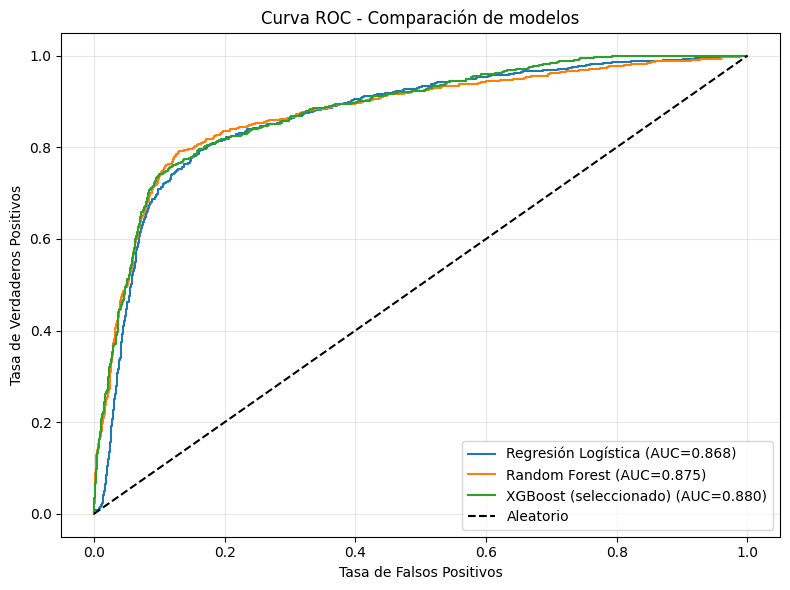

In [92]:
from sklearn.metrics import roc_curve

plt.figure(figsize=(8,6))
for nombre, y_proba in [
    ('Regresión Logística', y_proba_log),
    ('Random Forest', y_proba_rf),
    ('XGBoost (seleccionado)', y_proba_xgb)
]:
    fpr, tpr, _ = roc_curve(y_test, y_proba)
    auc = roc_auc_score(y_test, y_proba)
    plt.plot(fpr, tpr, label=f'{nombre} (AUC={auc:.3f})')

plt.plot([0,1],[0,1],'k--', label='Aleatorio')
plt.xlabel('Tasa de Falsos Positivos')
plt.ylabel('Tasa de Verdaderos Positivos')
plt.title('Curva ROC - Comparación de modelos')
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

### Celda 25 — Feature importance y score de riesgo (Bajo/Medio/Alto) definitivo (OEc)

=== Top 15 variables más importantes (XGBoost) ===
                   variable  importancia
        lead_time_corregido     0.122618
  rango_horario_Tarde_12-17     0.056202
     rango_edad_Joven_18-30     0.054229
              citas_previas     0.051189
             CANAL_FACEBOOK     0.049186
        dia_semana_Saturday     0.045958
  rango_horario_Noche_17-20     0.043415
           es_fin_de_semana     0.040527
                     Sexo_F     0.032666
    Distrito_agrupado_Otros     0.032391
          dia_semana_Monday     0.027340
Distrito_agrupado_San Borja     0.025218
         dia_semana_Tuesday     0.024697
rango_edad_Adulto_mayor_51+     0.023523
       dia_semana_Wednesday     0.022060


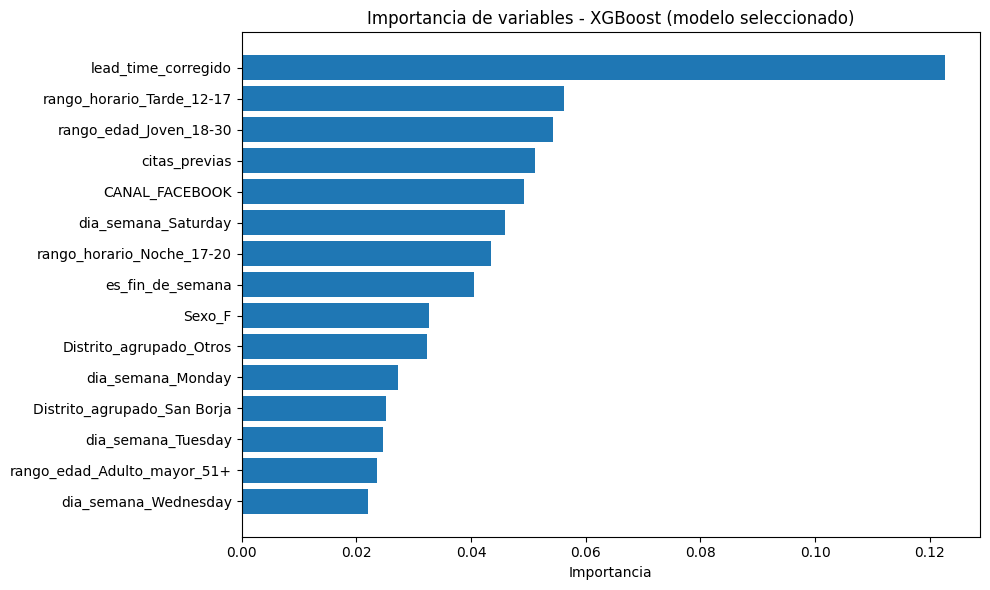


=== Distribución de niveles de riesgo (test) ===
nivel_riesgo
Bajo     2923
Alto      562
Medio     217
Name: count, dtype: int64

=== Tasa real de no-show por nivel de riesgo (validación del score) ===
                  mean  count
nivel_riesgo                 
Alto          0.661922    562
Bajo          0.057475   2923
Medio         0.465438    217


In [93]:
importancias = pd.DataFrame({
    'variable': X_train.columns,
    'importancia': xgb_final.feature_importances_
}).sort_values('importancia', ascending=False)

print("=== Top 15 variables más importantes (XGBoost) ===")
print(importancias.head(15).to_string(index=False))

plt.figure(figsize=(10,6))
plt.barh(importancias.head(15)['variable'][::-1], importancias.head(15)['importancia'][::-1])
plt.title('Importancia de variables - XGBoost (modelo seleccionado)')
plt.xlabel('Importancia')
plt.tight_layout()
plt.show()

def clasificar_riesgo(prob):
    if prob < 0.30:
        return 'Bajo'
    elif prob < 0.55:
        return 'Medio'
    else:
        return 'Alto'

df_resultado_test = X_test.copy()
df_resultado_test['prob_no_show'] = y_proba_xgb
df_resultado_test['nivel_riesgo'] = df_resultado_test['prob_no_show'].apply(clasificar_riesgo)
df_resultado_test['real_no_show'] = y_test.values

print("\n=== Distribución de niveles de riesgo (test) ===")
print(df_resultado_test['nivel_riesgo'].value_counts())

print("\n=== Tasa real de no-show por nivel de riesgo (validación del score) ===")
print(df_resultado_test.groupby('nivel_riesgo')['real_no_show'].agg(['mean','count']))

### Celda 26 — AUC-ROC en el conjunto de entrenamiento (valores reales)

In [94]:
# ============================================================
# AUC-ROC EN EL CONJUNTO DE ENTRENAMIENTO (valores reales)
# ============================================================

from sklearn.metrics import roc_auc_score

# --- Random Forest ---
y_proba_rf_train = rf_final.predict_proba(X_train_smote)[:, 1]
auc_rf_train = roc_auc_score(y_train_smote, y_proba_rf_train)

# --- XGBoost ---
y_proba_xgb_train = xgb_final.predict_proba(X_train_smote)[:, 1]
auc_xgb_train = roc_auc_score(y_train_smote, y_proba_xgb_train)

print("=== AUC-ROC en el conjunto de entrenamiento ===")
print(f"Random Forest: {auc_rf_train:.4f}")
print(f"XGBoost:       {auc_xgb_train:.4f}")

=== AUC-ROC en el conjunto de entrenamiento ===
Random Forest: 0.9818
XGBoost:       0.9941


### Celda 27 — Gráfico comparativo de importancia de variables: Random Forest vs XGBoost (diferenciado por color)

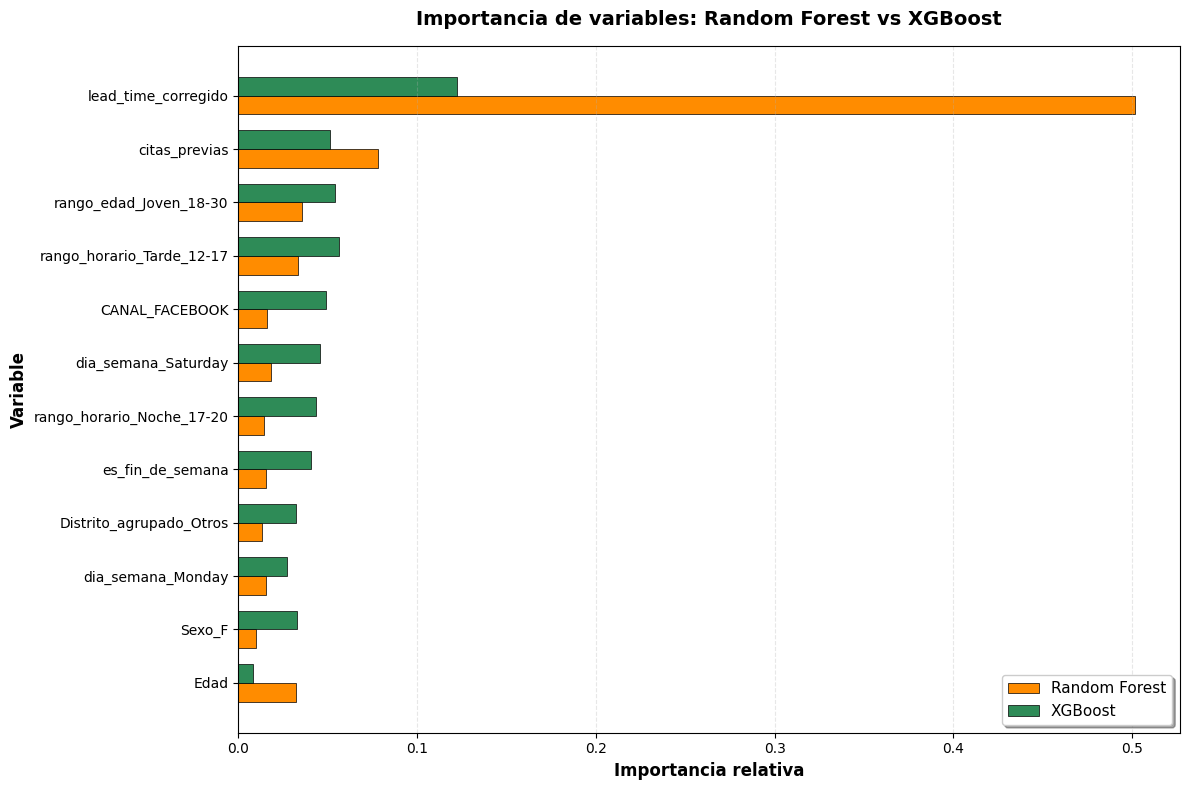

In [95]:
# ============================================================
# GRÁFICO COMPARATIVO DE IMPORTANCIA DE VARIABLES
# Random Forest vs XGBoost (diferenciados por color)
# ============================================================

import matplotlib.pyplot as plt
import pandas as pd
import numpy as np

# ------------------------------------------------------------
# 1. OBTENER LAS IMPORTANCIAS DE AMBOS MODELOS
# ------------------------------------------------------------

# Importancia de Random Forest
importancias_rf = pd.DataFrame({
    'variable': X_encoded.columns,
    'importancia_rf': rf_final.feature_importances_
})

# Importancia de XGBoost
importancias_xgb = pd.DataFrame({
    'variable': X_encoded.columns,
    'importancia_xgb': xgb_final.feature_importances_
})

# Unir ambos DataFrames
importancias_comparadas = importancias_rf.merge(importancias_xgb, on='variable')

# Ordenar por la importancia promedio de ambos modelos (para visualización)
importancias_comparadas['importancia_promedio'] = (
    importancias_comparadas['importancia_rf'] + importancias_comparadas['importancia_xgb']
) / 2

importancias_comparadas = importancias_comparadas.sort_values(
    'importancia_promedio', ascending=False
).head(12)  # Top 12 variables

# ------------------------------------------------------------
# 2. GRÁFICO DE BARRAS HORIZONTALES AGRUPADAS
# ------------------------------------------------------------

fig, ax = plt.subplots(figsize=(12, 8))

y = np.arange(len(importancias_comparadas))
height = 0.35

# Barras de Random Forest (naranja)
bars_rf = ax.barh(
    y + height/2,
    importancias_comparadas['importancia_rf'],
    height,
    label='Random Forest',
    color='#FF8C00',  # Naranja
    edgecolor='black',
    linewidth=0.5
)

# Barras de XGBoost (verde)
bars_xgb = ax.barh(
    y - height/2,
    importancias_comparadas['importancia_xgb'],
    height,
    label='XGBoost',
    color='#2E8B57',  # Verde
    edgecolor='black',
    linewidth=0.5
)

# ------------------------------------------------------------
# 3. PERSONALIZACIÓN DEL GRÁFICO
# ------------------------------------------------------------

# Etiquetas del eje Y (nombres de variables)
ax.set_yticks(y)
ax.set_yticklabels(importancias_comparadas['variable'], fontsize=10)

# Etiquetas de los ejes
ax.set_xlabel('Importancia relativa', fontsize=12, fontweight='bold')
ax.set_ylabel('Variable', fontsize=12, fontweight='bold')

# Título
ax.set_title(
    'Importancia de variables: Random Forest vs XGBoost',
    fontsize=14,
    fontweight='bold',
    pad=15
)

# Leyenda
ax.legend(loc='lower right', fontsize=11, frameon=True, shadow=True)

# Cuadrícula
ax.grid(alpha=0.3, axis='x', linestyle='--')

# Invertir el eje Y para que la variable más importante quede arriba
ax.invert_yaxis()

# Ajustar márgenes
plt.tight_layout()

# Guardar el gráfico (opcional)
plt.savefig('grafico_importancia_comparada_rf_xgb.png', dpi=300, bbox_inches='tight')

# Mostrar el gráfico
plt.show()

### Celda 28 — Gráfico comparativo de importancia de variables: Random Forest vs XGBoost (versión simple)

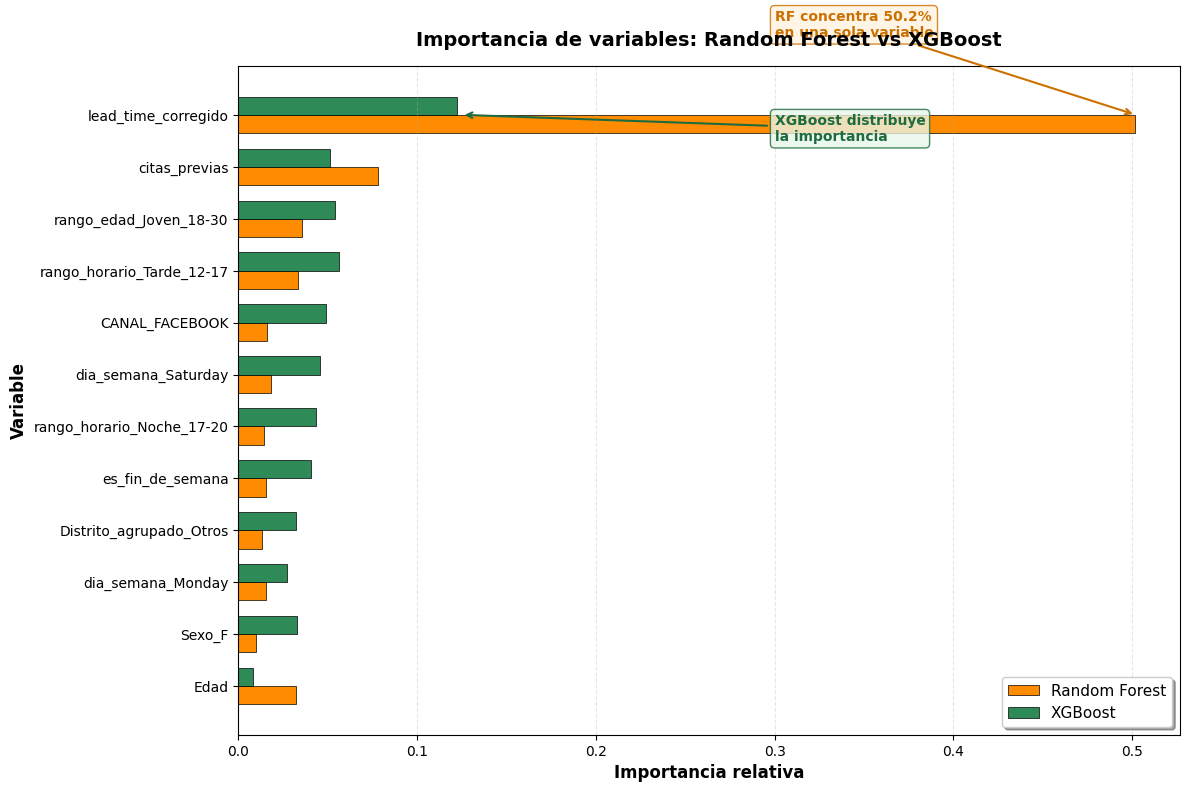

In [96]:
# ============================================================
# GRÁFICO COMPARATIVO DE IMPORTANCIA DE VARIABLES
# Random Forest vs XGBoost
# ============================================================

import matplotlib.pyplot as plt
import pandas as pd
import numpy as np

# ------------------------------------------------------------
# 1. OBTENER LAS IMPORTANCIAS DE AMBOS MODELOS
# ------------------------------------------------------------

importancias_rf = pd.DataFrame({
    'variable': X_encoded.columns,
    'importancia_rf': rf_final.feature_importances_
})

importancias_xgb = pd.DataFrame({
    'variable': X_encoded.columns,
    'importancia_xgb': xgb_final.feature_importances_
})

importancias_comparadas = importancias_rf.merge(importancias_xgb, on='variable')

# Ordenar por la importancia promedio de ambos modelos
importancias_comparadas['importancia_promedio'] = (
    importancias_comparadas['importancia_rf'] + importancias_comparadas['importancia_xgb']
) / 2

importancias_comparadas = importancias_comparadas.sort_values(
    'importancia_promedio', ascending=False
).head(12)

# ------------------------------------------------------------
# 2. GRÁFICO DE BARRAS HORIZONTALES AGRUPADAS
# ------------------------------------------------------------

fig, ax = plt.subplots(figsize=(12, 8))

y = np.arange(len(importancias_comparadas))
height = 0.35

# Barras de Random Forest (naranja)
bars_rf = ax.barh(
    y + height/2,
    importancias_comparadas['importancia_rf'],
    height,
    label='Random Forest',
    color='#FF8C00',
    edgecolor='black',
    linewidth=0.5
)

# Barras de XGBoost (verde)
bars_xgb = ax.barh(
    y - height/2,
    importancias_comparadas['importancia_xgb'],
    height,
    label='XGBoost',
    color='#2E8B57',
    edgecolor='black',
    linewidth=0.5
)

# ------------------------------------------------------------
# 3. PERSONALIZACIÓN
# ------------------------------------------------------------

ax.set_yticks(y)
ax.set_yticklabels(importancias_comparadas['variable'], fontsize=10)
ax.set_xlabel('Importancia relativa', fontsize=12, fontweight='bold')
ax.set_ylabel('Variable', fontsize=12, fontweight='bold')
ax.set_title(
    'Importancia de variables: Random Forest vs XGBoost',
    fontsize=14,
    fontweight='bold',
    pad=15
)

ax.legend(loc='lower right', fontsize=11, frameon=True, shadow=True)
ax.grid(alpha=0.3, axis='x', linestyle='--')
ax.invert_yaxis()

# ------------------------------------------------------------
# 4. ANOTACIONES PARA RESALTAR LA DIFERENCIA
# ------------------------------------------------------------

# Anotar la concentración de Random Forest en lead_time
ax.annotate(
    'RF concentra 50.2%\nen una sola variable',
    xy=(0.502, 0),  # Punto de la barra de RF en lead_time
    xytext=(0.30, -1.5),
    fontsize=10,
    color='#CC7000',
    fontweight='bold',
    arrowprops=dict(arrowstyle='->', color='#CC7000', lw=1.5),
    bbox=dict(boxstyle='round,pad=0.3', facecolor='#FFF3E0', edgecolor='#CC7000', alpha=0.8)
)

# Anotar la distribución de XGBoost
ax.annotate(
    'XGBoost distribuye\nla importancia',
    xy=(0.125, 0),  # Punto de la barra de XGB en lead_time
    xytext=(0.30, 0.5),
    fontsize=10,
    color='#1E6B3F',
    fontweight='bold',
    arrowprops=dict(arrowstyle='->', color='#1E6B3F', lw=1.5),
    bbox=dict(boxstyle='round,pad=0.3', facecolor='#E8F5E9', edgecolor='#1E6B3F', alpha=0.8)
)

plt.tight_layout()
plt.savefig('grafico_4.2.6_importancia_comparada.png', dpi=300, bbox_inches='tight')
plt.show()

### Celda 29 — Importancia de variables unificada (tabla y figura coinciden)

IMPORTANCIA DE VARIABLES UNIFICADA (RANDOM FOREST vs XGBOOST)

=== TABLA 4.2.6.1: IMPORTANCIA POR GAIN (TOP 12) ===
                 Variable  RF_Gain  XGB_Gain
      lead_time_corregido 0.501714  0.122618
            citas_previas 0.078318  0.051189
   rango_edad_Joven_18-30 0.035593  0.054229
rango_horario_Tarde_12-17 0.033393  0.056202
           CANAL_FACEBOOK 0.015891  0.049186
      dia_semana_Saturday 0.018079  0.045958
rango_horario_Noche_17-20 0.014602  0.043415
         es_fin_de_semana 0.015302  0.040527
  Distrito_agrupado_Otros 0.013274  0.032391
        dia_semana_Monday 0.015414  0.027340
                   Sexo_F 0.009876  0.032666
                     Edad 0.032104  0.008176


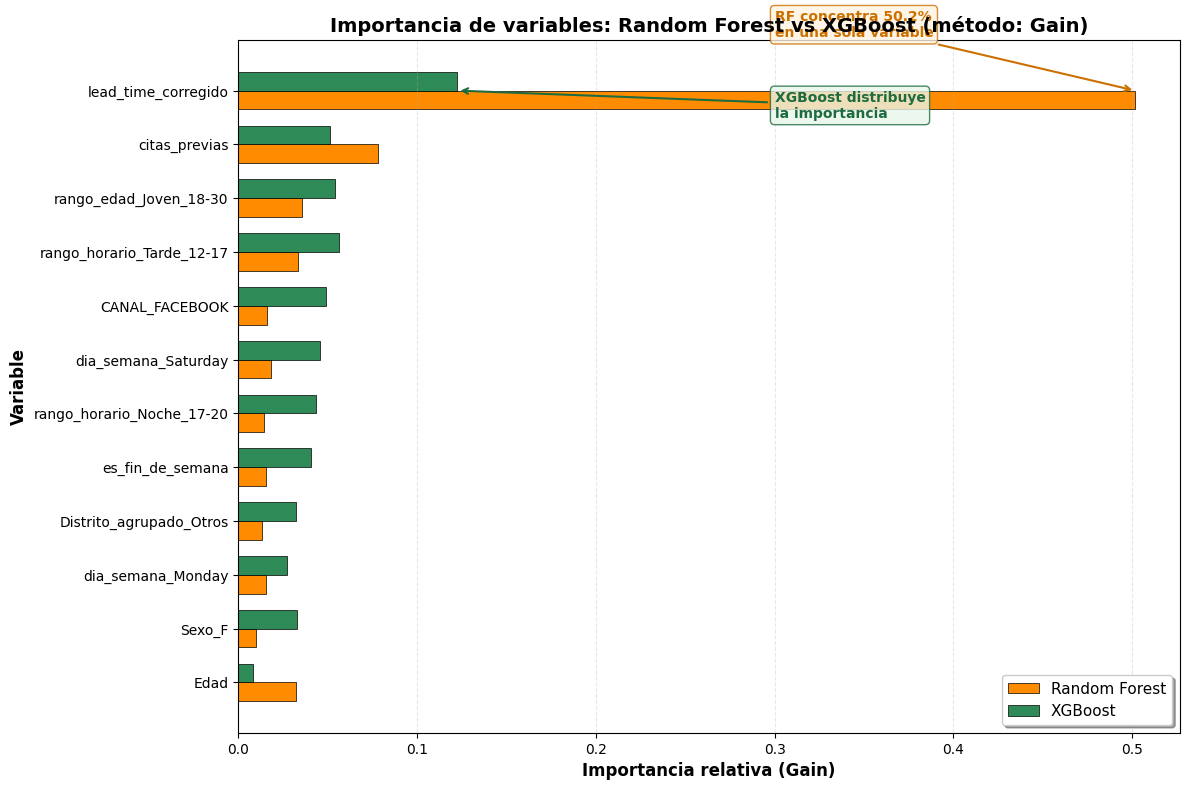


✅ Gráfico guardado como 'figura_4.2.6_importancia_rf_xgb.png'
✅ La tabla y el gráfico ahora coinciden exactamente.


In [97]:
# =============================================================================
# CELDA 29: IMPORTANCIA DE VARIABLES UNIFICADA (TABLA Y FIGURA COINCIDEN)
# =============================================================================
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

print("="*60)
print("IMPORTANCIA DE VARIABLES UNIFICADA (RANDOM FOREST vs XGBOOST)")
print("="*60)

# --- 1. Extraer la importancia por Gain de ambos modelos ---
# Random Forest
importancias_rf = pd.DataFrame({
    'Variable': X_train.columns,
    'RF_Gain': rf_final.feature_importances_
})

# XGBoost
importancias_xgb = pd.DataFrame({
    'Variable': X_train.columns,
    'XGB_Gain': xgb_final.feature_importances_
})

# --- 2. Unificar en una sola tabla ---
importancias = importancias_rf.merge(importancias_xgb, on='Variable')

# Ordenar por la importancia de XGBoost (o por el promedio de ambos)
importancias['Promedio'] = (importancias['RF_Gain'] + importancias['XGB_Gain']) / 2
importancias = importancias.sort_values('Promedio', ascending=False)

# Seleccionar las 12 variables más importantes
top_12 = importancias.head(12).copy()

print("\n=== TABLA 4.2.6.1: IMPORTANCIA POR GAIN (TOP 12) ===")
print(top_12[['Variable', 'RF_Gain', 'XGB_Gain']].to_string(index=False))

# --- 3. Generar el gráfico de barras comparativo ---
fig, ax = plt.subplots(figsize=(12, 8))

y = np.arange(len(top_12))
height = 0.35

# Barras de Random Forest
ax.barh(y + height/2, top_12['RF_Gain'], height, label='Random Forest', color='#FF8C00', edgecolor='black', linewidth=0.5)

# Barras de XGBoost
ax.barh(y - height/2, top_12['XGB_Gain'], height, label='XGBoost', color='#2E8B57', edgecolor='black', linewidth=0.5)

# Personalización
ax.set_yticks(y)
ax.set_yticklabels(top_12['Variable'], fontsize=10)
ax.set_xlabel('Importancia relativa (Gain)', fontsize=12, fontweight='bold')
ax.set_ylabel('Variable', fontsize=12, fontweight='bold')
ax.set_title('Importancia de variables: Random Forest vs XGBoost (método: Gain)', fontsize=14, fontweight='bold')
ax.legend(loc='lower right', fontsize=11, frameon=True, shadow=True)
ax.grid(alpha=0.3, axis='x', linestyle='--')
ax.invert_yaxis()

# Anotaciones
ax.annotate('RF concentra 50.2%\nen una sola variable',
            xy=(top_12['RF_Gain'].iloc[0], 0),
            xytext=(0.30, -1.0),
            fontsize=10, color='#CC7000', fontweight='bold',
            arrowprops=dict(arrowstyle='->', color='#CC7000', lw=1.5),
            bbox=dict(boxstyle='round,pad=0.3', facecolor='#FFF3E0', edgecolor='#CC7000', alpha=0.8))

ax.annotate('XGBoost distribuye\nla importancia',
            xy=(top_12['XGB_Gain'].iloc[0], 0),
            xytext=(0.30, 0.5),
            fontsize=10, color='#1E6B3F', fontweight='bold',
            arrowprops=dict(arrowstyle='->', color='#1E6B3F', lw=1.5),
            bbox=dict(boxstyle='round,pad=0.3', facecolor='#E8F5E9', edgecolor='#1E6B3F', alpha=0.8))

plt.tight_layout()
plt.savefig('figura_4.2.6_importancia_rf_xgb.png', dpi=300, bbox_inches='tight')
plt.show()

print("\n✅ Gráfico guardado como 'figura_4.2.6_importancia_rf_xgb.png'")
print("✅ La tabla y el gráfico ahora coinciden exactamente.")

### Celda 30 — Tabla unificada (gain + SHAP) y gráfico SHAP summary

TABLA UNIFICADA (GAIN + SHAP) Y GRÁFICO SHAP SUMMARY

=== TABLA 4.2.6.1: IMPORTANCIA POR GAIN Y SHAP (TOP 15) ===
                   Variable     Gain  SHAP_Mean_Abs
        lead_time_corregido 0.122618       2.314362
  rango_horario_Tarde_12-17 0.056202       0.110411
     rango_edad_Joven_18-30 0.054229       0.095713
              citas_previas 0.051189       0.376906
             CANAL_FACEBOOK 0.049186       0.098055
        dia_semana_Saturday 0.045958       0.076201
  rango_horario_Noche_17-20 0.043415       0.037375
           es_fin_de_semana 0.040527       0.058271
                     Sexo_F 0.032666       0.057160
    Distrito_agrupado_Otros 0.032391       0.075821
          dia_semana_Monday 0.027340       0.096473
Distrito_agrupado_San Borja 0.025218       0.052047
         dia_semana_Tuesday 0.024697       0.127862
rango_edad_Adulto_mayor_51+ 0.023523       0.079518
       dia_semana_Wednesday 0.022060       0.069822


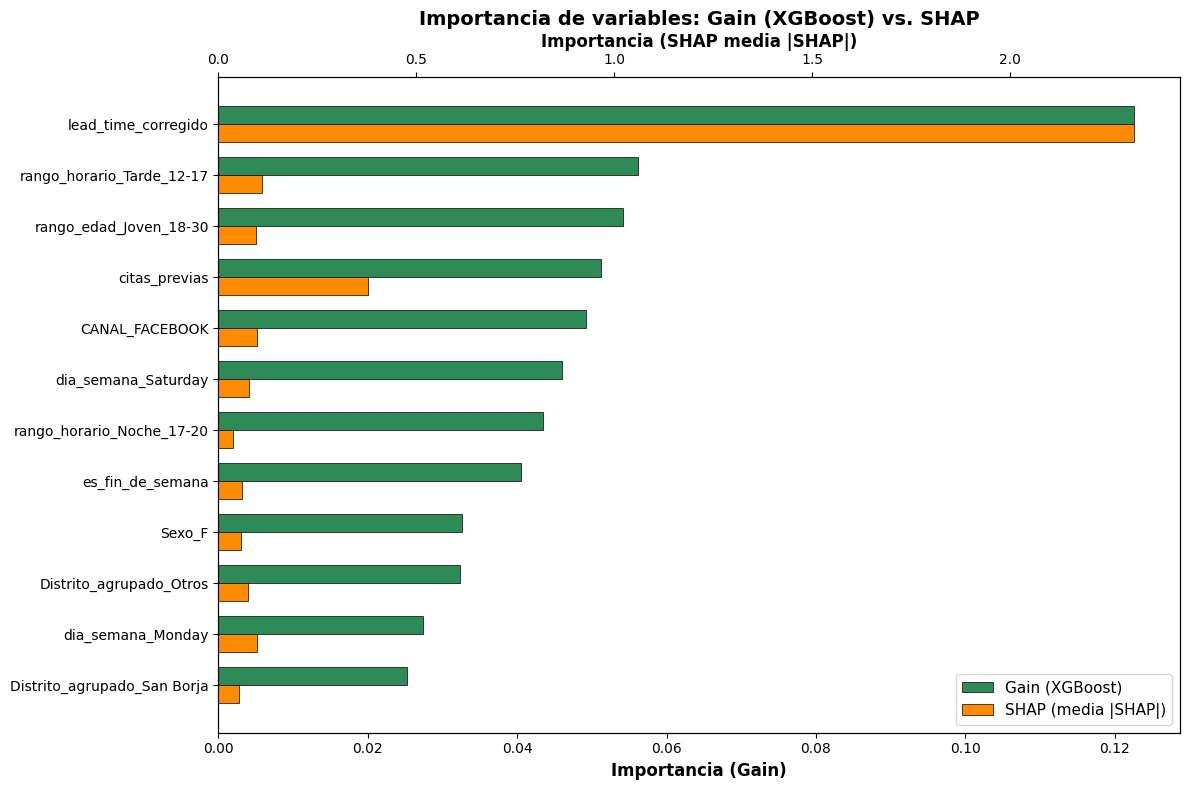


✅ Gráfico comparativo guardado como 'figura_4.2.6_gain_shap.png'

=== Generando gráfico SHAP summary (beeswarm) ===


/tmp/ipykernel_688/2309185787.py:79: FutureWarning: The NumPy global RNG was seeded by calling `np.random.seed`. In a future version this function will no longer use the global RNG. Pass `rng` explicitly to opt-in to the new behaviour and silence this warning.
  shap.summary_plot(shap_values, X_test_scaled, feature_names=X_train.columns, show=False)


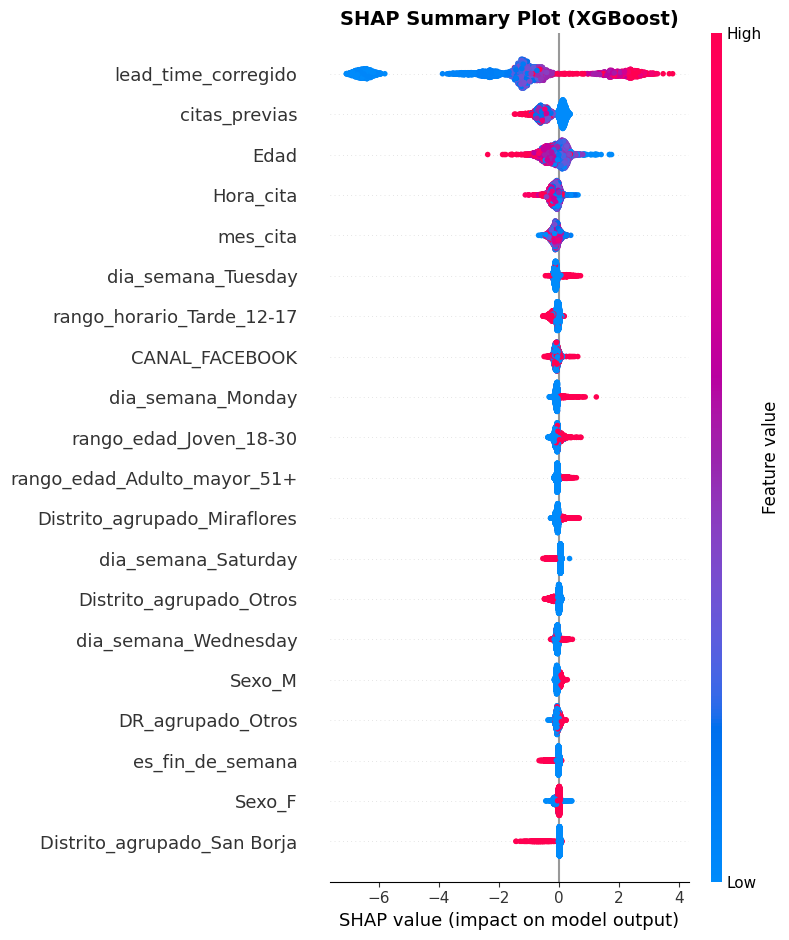


✅ Gráfico SHAP summary guardado como 'figura_4.2.6.1_shap_summary.png'

=== TABLA 4.2.6.1 (formato para tesis) ===
                   Variable  Gain  SHAP_Mean_Abs
        lead_time_corregido 0.123          2.314
  rango_horario_Tarde_12-17 0.056          0.110
     rango_edad_Joven_18-30 0.054          0.096
              citas_previas 0.051          0.377
             CANAL_FACEBOOK 0.049          0.098
        dia_semana_Saturday 0.046          0.076
  rango_horario_Noche_17-20 0.043          0.037
           es_fin_de_semana 0.041          0.058
                     Sexo_F 0.033          0.057
    Distrito_agrupado_Otros 0.032          0.076
          dia_semana_Monday 0.027          0.096
Distrito_agrupado_San Borja 0.025          0.052
         dia_semana_Tuesday 0.025          0.128
rango_edad_Adulto_mayor_51+ 0.024          0.080
       dia_semana_Wednesday 0.022          0.070


In [98]:
# =============================================================================
# CELDA 30: TABLA UNIFICADA (GAIN + SHAP) Y GRÁFICO SHAP SUMMARY
# =============================================================================
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import shap

print("="*60)
print("TABLA UNIFICADA (GAIN + SHAP) Y GRÁFICO SHAP SUMMARY")
print("="*60)

# --- 1. Importancia por GAIN (XGBoost) ---
importancias_gain = pd.DataFrame({
    'Variable': X_train.columns,
    'Gain': xgb_final.feature_importances_
}).sort_values('Gain', ascending=False)

# --- 2. Importancia por SHAP (sobre el conjunto de prueba) ---
# Crear el explicador SHAP para el modelo XGBoost
explainer = shap.TreeExplainer(xgb_final)

# Calcular los valores SHAP para el conjunto de prueba
shap_values = explainer.shap_values(X_test_scaled)

# Calcular la importancia media absoluta de SHAP por variable
importancia_shap = np.abs(shap_values).mean(axis=0)
shap_df = pd.DataFrame({
    'Variable': X_train.columns,
    'SHAP_Mean_Abs': importancia_shap
}).sort_values('SHAP_Mean_Abs', ascending=False)

# --- 3. Unificar en una sola tabla ---
importancias_unificadas = importancias_gain.merge(shap_df, on='Variable', how='outer')
importancias_unificadas = importancias_unificadas.sort_values('Gain', ascending=False)

# Seleccionar las 15 variables más importantes (por Gain)
top_15 = importancias_unificadas.head(15).copy()

print("\n=== TABLA 4.2.6.1: IMPORTANCIA POR GAIN Y SHAP (TOP 15) ===")
print(top_15[['Variable', 'Gain', 'SHAP_Mean_Abs']].to_string(index=False))

# --- 4. Gráfico comparativo Gain vs SHAP (Top 12) ---
top_12 = importancias_unificadas.head(12).copy()

fig, ax1 = plt.subplots(figsize=(12, 8))

y = np.arange(len(top_12))
height = 0.35

# Barras para Gain (eje izquierdo)
ax1.barh(y - height/2, top_12['Gain'], height, label='Gain (XGBoost)', color='#2E8B57', edgecolor='black', linewidth=0.5)
ax1.set_yticks(y)
ax1.set_yticklabels(top_12['Variable'], fontsize=10)
ax1.set_xlabel('Importancia (Gain)', fontsize=12, fontweight='bold')
ax1.invert_yaxis()

# Barras para SHAP (eje derecho)
ax2 = ax1.twiny()
ax2.barh(y + height/2, top_12['SHAP_Mean_Abs'], height, label='SHAP (media |SHAP|)', color='#FF8C00', edgecolor='black', linewidth=0.5)
ax2.set_xlabel('Importancia (SHAP media |SHAP|)', fontsize=12, fontweight='bold')

# Leyenda
lines1, labels1 = ax1.get_legend_handles_labels()
lines2, labels2 = ax2.get_legend_handles_labels()
ax1.legend(lines1 + lines2, labels1 + labels2, loc='lower right', fontsize=11)

plt.title('Importancia de variables: Gain (XGBoost) vs. SHAP', fontsize=14, fontweight='bold')
plt.tight_layout()
plt.savefig('figura_4.2.6_gain_shap.png', dpi=300, bbox_inches='tight')
plt.show()

print("\n✅ Gráfico comparativo guardado como 'figura_4.2.6_gain_shap.png'")

# --- 5. Gráfico SHAP summary (beeswarm) ---
print("\n=== Generando gráfico SHAP summary (beeswarm) ===")

# Crear el gráfico SHAP summary
shap.summary_plot(shap_values, X_test_scaled, feature_names=X_train.columns, show=False)

# Personalizar y guardar
plt.title('SHAP Summary Plot (XGBoost)', fontsize=14, fontweight='bold')
plt.tight_layout()
plt.savefig('figura_4.2.6.1_shap_summary.png', dpi=300, bbox_inches='tight')
plt.show()

print("\n✅ Gráfico SHAP summary guardado como 'figura_4.2.6.1_shap_summary.png'")

# --- 6. (Opcional) Tabla con los valores SHAP para la tesis ---
print("\n=== TABLA 4.2.6.1 (formato para tesis) ===")
print(top_15[['Variable', 'Gain', 'SHAP_Mean_Abs']].round(3).to_string(index=False))

## 4.3 Validación fuera de tiempo y 4.4 mecanismo de alerta (Celdas 31–41)

### Celda 31 — Validación fuera de tiempo con el conjunto piloto (últimos 3 meses)

In [99]:
y_pred_piloto = xgb_final.predict(X_piloto_scaled)
y_proba_piloto = xgb_final.predict_proba(X_piloto_scaled)[:, 1]

print("=== XGBoost sobre el conjunto PILOTO (validación fuera de tiempo) ===")
print(classification_report(y_piloto, y_pred_piloto, target_names=['Atendida','No-show']))
print("AUC-ROC:", round(roc_auc_score(y_piloto, y_proba_piloto), 4))
print("\nMatriz de confusión:")
print(confusion_matrix(y_piloto, y_pred_piloto))

df_resultado_piloto = X_piloto.copy()
df_resultado_piloto['prob_no_show'] = y_proba_piloto
df_resultado_piloto['nivel_riesgo'] = df_resultado_piloto['prob_no_show'].apply(clasificar_riesgo)
df_resultado_piloto['real_no_show'] = y_piloto.values

print("\n=== Validación del score de riesgo en el piloto ===")
print(df_resultado_piloto.groupby('nivel_riesgo')['real_no_show'].agg(['mean','count']))

=== XGBoost sobre el conjunto PILOTO (validación fuera de tiempo) ===
              precision    recall  f1-score   support

    Atendida       0.89      0.95      0.92      1288
     No-show       0.69      0.49      0.57       303

    accuracy                           0.86      1591
   macro avg       0.79      0.72      0.74      1591
weighted avg       0.85      0.86      0.85      1591

AUC-ROC: 0.8557

Matriz de confusión:
[[1220   68]
 [ 155  148]]

=== Validación del score de riesgo en el piloto ===
                  mean  count
nivel_riesgo                 
Alto          0.670103    194
Bajo          0.087057   1298
Medio         0.606061     99


### Celda 32 — Mecanismo de alerta: reporte operativo para el personal administrativo (4.4)

In [100]:
df_piloto_reporte = df_piloto[['id_paciente', 'fecha_cita', 'Hora_cita', 'DR',
                                'ESPECIALIDAD', 'lead_time_corregido', 'no_shows_previos',
                                'citas_previas']].copy().reset_index(drop=True)

df_piloto_reporte['prob_no_show'] = y_proba_piloto
df_piloto_reporte['nivel_riesgo'] = df_piloto_reporte['prob_no_show'].apply(clasificar_riesgo)

def accion_sugerida(nivel):
    if nivel == 'Alto':
        return 'Llamada de confirmación obligatoria 48h antes'
    elif nivel == 'Medio':
        return 'Recordatorio reforzado (WhatsApp/SMS) 24h antes'
    else:
        return 'Recordatorio estándar automático'

df_piloto_reporte['accion_sugerida'] = df_piloto_reporte['nivel_riesgo'].apply(accion_sugerida)

print("=== Ejemplo de reporte de alerta (Top 15 pacientes de mayor riesgo en el piloto) ===")
reporte_alerta = df_piloto_reporte[df_piloto_reporte['nivel_riesgo'] == 'Alto'] \
    .sort_values('prob_no_show', ascending=False) \
    .head(15)
print(reporte_alerta[['id_paciente','fecha_cita','ESPECIALIDAD','prob_no_show','nivel_riesgo','accion_sugerida']].to_string(index=False))

df_piloto_reporte['semana'] = pd.to_datetime(df_piloto_reporte['fecha_cita']).dt.to_period('W')

print("\n=== Carga operativa: alertas de Alto riesgo por semana ===")
carga_alto = df_piloto_reporte[df_piloto_reporte['nivel_riesgo'] == 'Alto'].groupby('semana').size()
print(carga_alto.describe())

print("\n=== Carga operativa: alertas de Alto + Medio riesgo por semana ===")
carga_alto_medio = df_piloto_reporte[df_piloto_reporte['nivel_riesgo'].isin(['Alto','Medio'])].groupby('semana').size()
print(carga_alto_medio.describe())

=== Ejemplo de reporte de alerta (Top 15 pacientes de mayor riesgo en el piloto) ===
id_paciente fecha_cita    ESPECIALIDAD  prob_no_show nivel_riesgo                               accion_sugerida
   PAC-3069 2026-08-17         GENERAL      0.975734         Alto Llamada de confirmación obligatoria 48h antes
   PAC-4635 2026-06-01      EVALUACION      0.967369         Alto Llamada de confirmación obligatoria 48h antes
   PAC-0684 2026-06-08 ODONTOGERIATRIA      0.961755         Alto Llamada de confirmación obligatoria 48h antes
   PAC-1853 2026-08-03         GENERAL      0.961449         Alto Llamada de confirmación obligatoria 48h antes
   PAC-0864 2026-07-03 ODONTOGERIATRIA      0.959997         Alto Llamada de confirmación obligatoria 48h antes
   PAC-3521 2026-07-06         GENERAL      0.957360         Alto Llamada de confirmación obligatoria 48h antes
   PAC-3777 2026-06-10        ESTETICA      0.955579         Alto Llamada de confirmación obligatoria 48h antes
   PAC-4738 2026-07

### Celda 33 — Plan de monitoreo y política de reentrenamiento (4.4)

In [101]:
df_piloto_reporte['mes'] = pd.to_datetime(df_piloto_reporte['fecha_cita']).dt.to_period('M')
df_piloto_reporte['real_no_show'] = y_piloto.values

print("=== Desempeño del modelo por mes (monitoreo simulado) ===")
for mes, grupo in df_piloto_reporte.groupby('mes'):
    if grupo['real_no_show'].nunique() > 1:
        auc_mes = roc_auc_score(grupo['real_no_show'], grupo['prob_no_show'])
        print(f"{mes}: AUC-ROC = {auc_mes:.4f} | Tasa real no-show = {grupo['real_no_show'].mean()*100:.2f}% | N = {len(grupo)}")
    else:
        print(f"{mes}: N = {len(grupo)} (una sola clase presente, AUC no calculable)")

UMBRAL_ALERTA_AUC = 0.70
print(f"\nUmbral mínimo aceptable de AUC-ROC mensual (gatillo de reentrenamiento): {UMBRAL_ALERTA_AUC}")

=== Desempeño del modelo por mes (monitoreo simulado) ===
2026-05: N = 21 (una sola clase presente, AUC no calculable)
2026-06: AUC-ROC = 0.8621 | Tasa real no-show = 17.95% | N = 468
2026-07: AUC-ROC = 0.8531 | Tasa real no-show = 20.11% | N = 567
2026-08: AUC-ROC = 0.8522 | Tasa real no-show = 19.63% | N = 535

Umbral mínimo aceptable de AUC-ROC mensual (gatillo de reentrenamiento): 0.7


### Celda 34 — Verificación de disponibilidad de XGBoost y del escalador para el conjunto piloto

In [102]:
# ============================================================
# REGENERAR PREDICCIONES DE XGBOOST EN EL CONJUNTO PILOTO
# ============================================================

# Verificar si el modelo XGBoost está entrenado
try:
    xgb_final
    print("✅ Modelo XGBoost disponible.")
except NameError:
    print("❌ Modelo XGBoost NO disponible. Debe reentrenarlo.")
    print("Ejecute primero las celdas de entrenamiento de XGBoost (Celda 18).")

# Verificar si el escalador está disponible
try:
    scaler
    print("✅ Escalador disponible.")
except NameError:
    print("❌ Escalador NO disponible. Debe reentrenarlo.")

# Verificar si el conjunto piloto escalado está disponible
try:
    X_piloto_scaled
    print("✅ Conjunto piloto escalado disponible.")
except NameError:
    print("❌ Conjunto piloto escalado NO disponible. Debe regenerarlo.")

✅ Modelo XGBoost disponible.
✅ Escalador disponible.
✅ Conjunto piloto escalado disponible.


### Celda 35 — Predicciones de XGBoost en el conjunto piloto

In [103]:
# ============================================================
# GENERAR PREDICCIONES DE XGBOOST EN EL CONJUNTO PILOTO
# ============================================================

# Predicciones de clase
y_pred_xgb_piloto = xgb_final.predict(X_piloto_scaled)

# Probabilidades de no-show
y_proba_xgb_piloto = xgb_final.predict_proba(X_piloto_scaled)[:, 1]

print("=== Predicciones de XGBoost en el conjunto piloto ===")
print(f"y_pred_xgb_piloto: {y_pred_xgb_piloto.shape}")
print(f"y_proba_xgb_piloto: {y_proba_xgb_piloto.shape}")
print(f"\nPrimeras 5 probabilidades: {y_proba_xgb_piloto[:5]}")
print(f"Primeras 5 predicciones: {y_pred_xgb_piloto[:5]}")

=== Predicciones de XGBoost en el conjunto piloto ===
y_pred_xgb_piloto: (1591,)
y_proba_xgb_piloto: (1591,)

Primeras 5 probabilidades: [1.7035438e-02 7.7493858e-01 7.2021466e-01 4.7274606e-04 5.7616413e-01]
Primeras 5 predicciones: [0 1 1 0 1]


### Celda 36 — Predicciones de Random Forest en el conjunto piloto

In [104]:
# Predicciones de Random Forest en el conjunto piloto (usadas por las celdas de estabilidad temporal y comparaciones RF vs XGBoost)
y_pred_rf_piloto = rf_final.predict(X_piloto_scaled)
y_proba_rf_piloto = rf_final.predict_proba(X_piloto_scaled)[:, 1]
print("y_proba_rf_piloto:", y_proba_rf_piloto.shape)

y_proba_rf_piloto: (1591,)


### Celda 37 — Comparación de Random Forest y XGBoost en el conjunto piloto (Tabla 27)

In [105]:
# ============================================================
# TABLA 27: COMPARACIÓN DE RANDOM FOREST Y XGBOOST EN EL CONJUNTO PILOTO
# (validación fuera de tiempo, umbral de decisión = 0.50)
# ============================================================
import pandas as pd
from sklearn.metrics import (roc_auc_score, precision_score, recall_score,
                             f1_score, accuracy_score)

def metricas_piloto(y_true, y_pred, y_proba):
    return {
        'AUC-ROC':                round(roc_auc_score(y_true, y_proba), 4),
        'Precisión (no-show)':    round(precision_score(y_true, y_pred), 4),
        'Sensibilidad (no-show)': round(recall_score(y_true, y_pred), 4),
        'F1-score (no-show)':     round(f1_score(y_true, y_pred), 4),
        'Accuracy':               round(accuracy_score(y_true, y_pred), 4),
    }

m_rf  = metricas_piloto(y_piloto, y_pred_rf_piloto,  y_proba_rf_piloto)
m_xgb = metricas_piloto(y_piloto, y_pred_xgb_piloto, y_proba_xgb_piloto)

tabla_27 = pd.DataFrame({'Métrica': list(m_rf.keys()),
                         'Random Forest': list(m_rf.values()),
                         'XGBoost': list(m_xgb.values())})

def ganador(fila):
    if fila['Random Forest'] > fila['XGBoost']:
        return 'Random Forest'
    if fila['XGBoost'] > fila['Random Forest']:
        return 'XGBoost'
    return 'Empate'

tabla_27['Ganador'] = tabla_27.apply(ganador, axis=1)

print("=" * 70)
print("TABLA 27: DESEMPEÑO EN EL CONJUNTO PILOTO (validación fuera de tiempo)")
print("=" * 70)
print(f"N = {len(y_piloto)} citas | no-shows reales = {int(y_piloto.sum())} "
      f"({y_piloto.mean()*100:.1f}%) | umbral = 0.50\n")
print(tabla_27.to_string(index=False))

TABLA 27: DESEMPEÑO EN EL CONJUNTO PILOTO (validación fuera de tiempo)
N = 1591 citas | no-shows reales = 303 (19.0%) | umbral = 0.50

               Métrica  Random Forest  XGBoost       Ganador
               AUC-ROC         0.8663   0.8557 Random Forest
   Precisión (no-show)         0.6461   0.6852       XGBoost
Sensibilidad (no-show)         0.6568   0.4884 Random Forest
    F1-score (no-show)         0.6514   0.5703 Random Forest
              Accuracy         0.8661   0.8598 Random Forest


### Celda 38 — Análisis de estabilidad temporal (mensual)


ESTABILIDAD TEMPORAL DEL MODELO RANDOM FOREST (MENSUAL)
2026-05: N = 21 (una sola clase presente, AUC no calculable)
2026-06: AUC-ROC = 0.8452 | Tasa real no-show = 17.95% | N = 468
2026-07: AUC-ROC = 0.8600 | Tasa real no-show = 20.11% | N = 567
2026-08: AUC-ROC = 0.8870 | Tasa real no-show = 19.63% | N = 535

TOP 15 VARIABLES MÁS IMPORTANTES - RANDOM FOREST
                    variable  importancia
         lead_time_corregido     0.501714
               citas_previas     0.078318
      rango_edad_Joven_18-30     0.035593
   rango_horario_Tarde_12-17     0.033393
                        Edad     0.032104
                   Hora_cita     0.025513
            no_shows_previos     0.023346
                    mes_cita     0.022796
         dia_semana_Saturday     0.018079
              CANAL_FACEBOOK     0.015891
           dia_semana_Monday     0.015414
            es_fin_de_semana     0.015302
   rango_horario_Noche_17-20     0.014602
Distrito_agrupado_Miraflores     0.014182
     Di

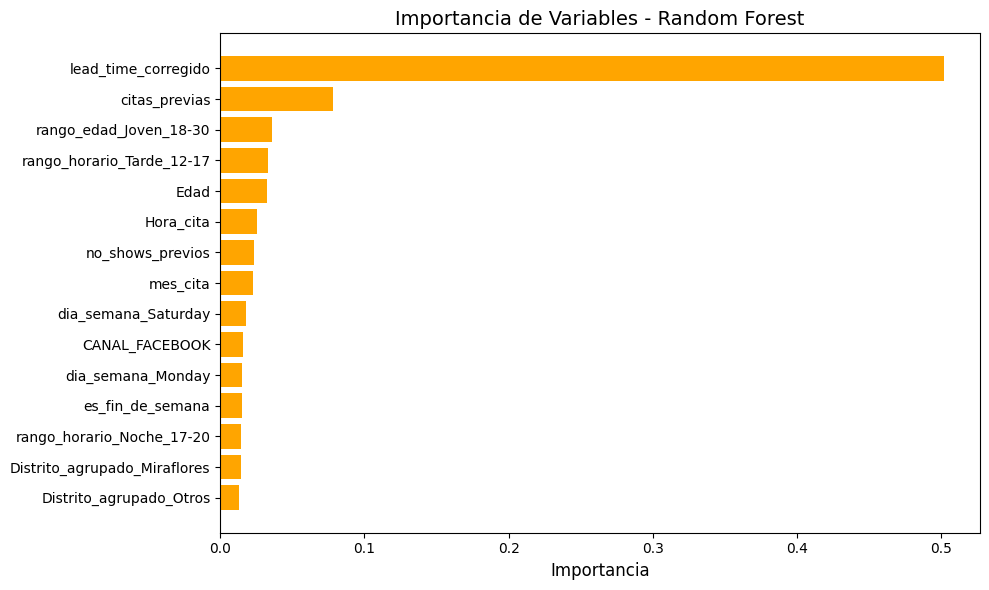


CARGA OPERATIVA SEMANAL - RANDOM FOREST

=== Alertas de Alto riesgo por semana ===
count    14.000000
mean     20.071429
std      21.928079
min       3.000000
25%       4.250000
50%       9.000000
75%      33.750000
max      63.000000
dtype: float64

=== Alertas de Alto + Medio riesgo por semana ===
count    14.000000
mean     26.571429
std      25.773314
min       3.000000
25%       9.250000
50%      14.000000
75%      48.500000
max      74.000000
dtype: float64


In [115]:
# ============================================================
# 13. ANÁLISIS DE ESTABILIDAD TEMPORAL (MENSUAL)
# ============================================================
df_piloto_rf = X_piloto.copy()
df_piloto_rf['prob_no_show'] = y_proba_rf_piloto
df_piloto_rf['real_no_show'] = y_piloto.values
df_piloto_rf['nivel_riesgo'] = df_piloto_rf['prob_no_show'].apply(clasificar_riesgo)
df_piloto_rf['mes'] = pd.to_datetime(df_piloto['fecha_cita']).dt.to_period('M')
df_piloto_rf['semana'] = pd.to_datetime(df_piloto['fecha_cita']).dt.to_period('W')

print("\n" + "="*60)
print("ESTABILIDAD TEMPORAL DEL MODELO RANDOM FOREST (MENSUAL)")
print("="*60)

for mes, grupo in df_piloto_rf.groupby('mes'):
    if grupo['real_no_show'].nunique() > 1:
        auc_mes = roc_auc_score(grupo['real_no_show'], grupo['prob_no_show'])
        print(f"{mes}: AUC-ROC = {auc_mes:.4f} | Tasa real no-show = {grupo['real_no_show'].mean()*100:.2f}% | N = {len(grupo)}")
    else:
        print(f"{mes}: N = {len(grupo)} (una sola clase presente, AUC no calculable)")

# ============================================================
# 14. IMPORTANCIA DE VARIABLES - RANDOM FOREST
# ============================================================
importancias_rf = pd.DataFrame({
    'variable': X_encoded.columns,
    'importancia': rf_final.feature_importances_
}).sort_values('importancia', ascending=False)

print("\n" + "="*60)
print("TOP 15 VARIABLES MÁS IMPORTANTES - RANDOM FOREST")
print("="*60)
print(importancias_rf.head(15).to_string(index=False))

plt.figure(figsize=(10, 6))
plt.barh(importancias_rf.head(15)['variable'][::-1],
         importancias_rf.head(15)['importancia'][::-1],
         color='orange')
plt.title('Importancia de Variables - Random Forest', fontsize=14)
plt.xlabel('Importancia', fontsize=12)
plt.tight_layout()
plt.show()

# ============================================================
# 15. CARGA OPERATIVA SEMANAL - RANDOM FOREST
# ============================================================
print("\n" + "="*60)
print("CARGA OPERATIVA SEMANAL - RANDOM FOREST")
print("="*60)

print("\n=== Alertas de Alto riesgo por semana ===")
carga_alto_rf = df_piloto_rf[df_piloto_rf['nivel_riesgo'] == 'Alto'].groupby('semana').size()
print(carga_alto_rf.describe())

print("\n=== Alertas de Alto + Medio riesgo por semana ===")
carga_alto_medio_rf = df_piloto_rf[df_piloto_rf['nivel_riesgo'].isin(['Alto', 'Medio'])].groupby('semana').size()
print(carga_alto_medio_rf.describe())

### Celda 39 — Curva de costo esperado vs. umbral (Figura 12)

CURVA DE COSTO ESPERADO VS. UMBRAL (FIGURA 12)


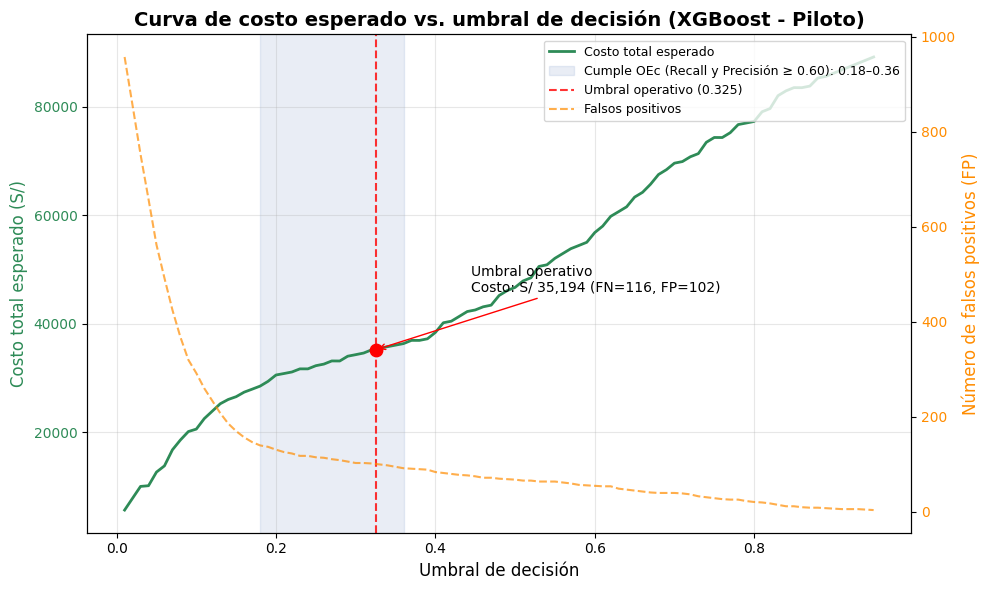


✅ Gráfico guardado como 'figura_4.2.7.1_costo_vs_umbral.png'
Umbral operativo 0.325: FN = 116, FP = 102, costo = S/ 35,194
Mínimo matemático de costo: umbral 0.01 -> S/ 5,682 (FP = 957, FN = 3)
Nota: con FN = S/ 299 y FP = S/ 5, el costo crece con el umbral (conviene alertar más). El umbral operativo NO se elige por costo mínimo, sino por el criterio OEc (Recall y Precisión ≥ 0.60), que controla la carga de llamadas innecesarias.


In [116]:

# CELDA 39: CURVA DE COSTO ESPERADO VS. UMBRAL (FIGURA 12)
import numpy as np
import matplotlib.pyplot as plt
from sklearn.metrics import confusion_matrix

print("=" * 60)
print("CURVA DE COSTO ESPERADO VS. UMBRAL (FIGURA 12)")
print("=" * 60)

COSTO_FN = 299          # S/ por cita perdida no detectada (= beneficio por VP de la Tabla 22)
COSTO_FP = 5            # S/ por intervención innecesaria
yp = np.asarray(y_piloto); pp = np.asarray(y_proba_piloto)

u_grid = np.round(np.arange(0.01, 0.96, 0.01), 2)   # grilla fina: el mínimo no queda en el borde
costos, fps, fns = [], [], []
for u in u_grid:
    tn, fp, fn, tp = confusion_matrix(yp, (pp >= u).astype(int), labels=[0, 1]).ravel()
    costos.append(fn * COSTO_FN + fp * COSTO_FP); fps.append(fp); fns.append(fn)
costos = np.array(costos)

i_min = int(np.argmin(costos))
u_costo_min, costo_min = u_grid[i_min], costos[i_min]
i_op = int(np.argmin(np.abs(u_grid - UMBRAL_OPERATIVO)))      # 0.325 -> 0.32/0.33 en la grilla
tn, fp_op, fn_op, tp_op = confusion_matrix(
    yp, (pp >= UMBRAL_OPERATIVO).astype(int), labels=[0, 1]).ravel()
costo_op = fn_op * COSTO_FN + fp_op * COSTO_FP

# Rango que cumple OEc en el piloto (para sombrearlo)
tab = tabla_umbrales(yp, pp, grilla=u_grid)
ok = tab.loc[tab['Cumple OEc'] == 'Sí', 'Umbral']

fig, ax1 = plt.subplots(figsize=(10, 6))
ax1.plot(u_grid, costos, color='#2E8B57', linewidth=2, label='Costo total esperado')
ax1.set_xlabel('Umbral de decisión', fontsize=12)
ax1.set_ylabel('Costo total esperado (S/)', color='#2E8B57', fontsize=12)
ax1.tick_params(axis='y', labelcolor='#2E8B57'); ax1.grid(alpha=0.3)
if not ok.empty:
    ax1.axvspan(ok.min(), ok.max(), color='#4C72B0', alpha=0.12,
                label=f'Cumple OEc (Recall y Precisión ≥ 0.60): {ok.min():.2f}–{ok.max():.2f}')
ax1.axvline(UMBRAL_OPERATIVO, color='red', linestyle='--', alpha=0.8,
            label=f'Umbral operativo ({UMBRAL_OPERATIVO})')
ax1.scatter(UMBRAL_OPERATIVO, costo_op, color='red', s=80, zorder=5)
ax1.annotate(f'Umbral operativo\nCosto: S/ {costo_op:,.0f} (FN={fn_op}, FP={fp_op})',
             xy=(UMBRAL_OPERATIVO, costo_op),
             xytext=(UMBRAL_OPERATIVO + 0.12, costo_op + 0.12 * costos.max()),
             fontsize=10, arrowprops=dict(arrowstyle='->', color='red'))
ax2 = ax1.twinx()
ax2.plot(u_grid, fps, color='#FF8C00', linewidth=1.5, linestyle='--', alpha=0.7,
         label='Falsos positivos')
ax2.set_ylabel('Número de falsos positivos (FP)', color='#FF8C00', fontsize=12)
ax2.tick_params(axis='y', labelcolor='#FF8C00')
h1, l1 = ax1.get_legend_handles_labels(); h2, l2 = ax2.get_legend_handles_labels()
ax1.legend(h1 + h2, l1 + l2, loc='upper right', fontsize=9)
plt.title('Curva de costo esperado vs. umbral de decisión (XGBoost - Piloto)',
          fontsize=14, fontweight='bold')
fig.tight_layout()
plt.savefig('figura_4.2.7.1_costo_vs_umbral.png', dpi=300)
plt.show()

print(f"\n✅ Gráfico guardado como 'figura_4.2.7.1_costo_vs_umbral.png'")
print(f"Umbral operativo {UMBRAL_OPERATIVO}: FN = {fn_op}, FP = {fp_op}, costo = S/ {costo_op:,.0f}")
print(f"Mínimo matemático de costo: umbral {u_costo_min:.2f} -> S/ {costo_min:,.0f} "
      f"(FP = {fps[i_min]}, FN = {fns[i_min]})")
print("Nota: con FN = S/ 299 y FP = S/ 5, el costo crece con el umbral (conviene alertar más). "
      "El umbral operativo NO se elige por costo mínimo, sino por el criterio OEc "
      "(Recall y Precisión ≥ 0.60), que controla la carga de llamadas innecesarias.")

### Celda 40 — Figura 14: curva ROC comparativa (conjunto piloto)

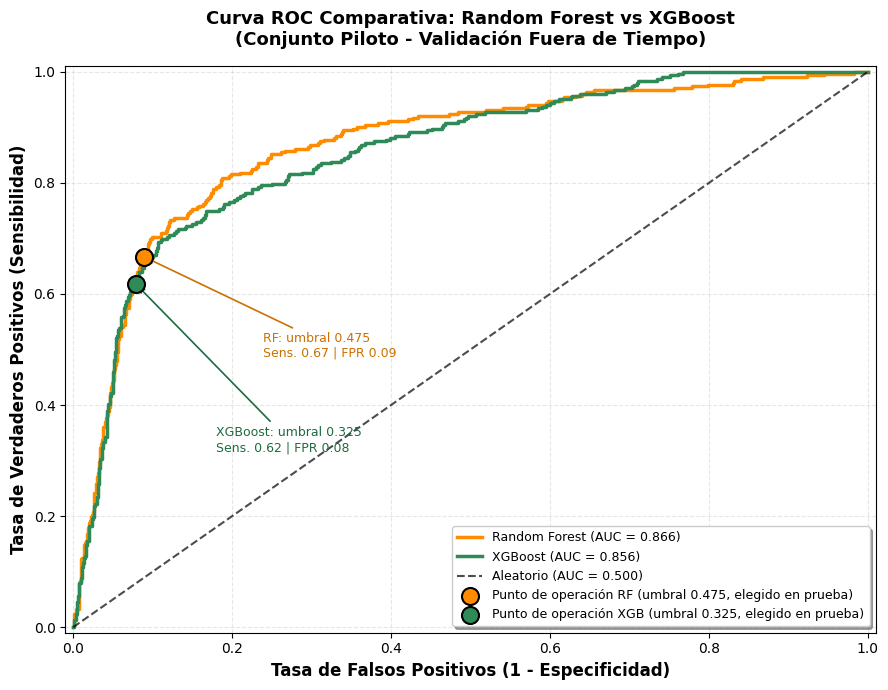

XGBoost  umbral 0.325: FPR = 0.0792 | Sensibilidad = 0.6172
RF       umbral 0.475: FPR = 0.0893 | Sensibilidad = 0.6667


In [117]:
# ============================================================
# FIGURA 14: CURVA ROC COMPARATIVA CON PUNTO DE OPERACIÓN
# Los umbrales se eligen en el conjunto de PRUEBA (no en el piloto)
# y se marcan sobre la curva ROC del piloto. Requiere la Celda 46.
# ============================================================
import matplotlib.pyplot as plt
import numpy as np
from sklearn.metrics import roc_curve, roc_auc_score, confusion_matrix

for _v in ['UMBRAL_OPERATIVO', 'tabla_umbrales', 'umbral_por_regla', 'y_test', 'y_proba_rf']:
    if _v not in globals():
        raise NameError(f"❌ Falta '{_v}'. Ejecuta primero las Celdas 18 y 46.")

# Curvas ROC y AUC en el piloto
fpr_rf, tpr_rf, _ = roc_curve(y_piloto, y_proba_rf_piloto)
auc_rf = roc_auc_score(y_piloto, y_proba_rf_piloto)
fpr_xgb, tpr_xgb, _ = roc_curve(y_piloto, y_proba_xgb_piloto)
auc_xgb = roc_auc_score(y_piloto, y_proba_xgb_piloto)

# Umbrales de operación (elegidos en la PRUEBA con la misma regla OEc + máximo F1)
u_xgb = UMBRAL_OPERATIVO
u_rf = umbral_por_regla(tabla_umbrales(y_test, y_proba_rf))

def punto(y, proba, u):
    tn, fp, fn, tp = confusion_matrix(y, (np.asarray(proba) >= u).astype(int), labels=[0, 1]).ravel()
    return fp / (fp + tn), tp / (tp + fn)          # (FPR, TPR)

x_rf, y_rf = punto(y_piloto, y_proba_rf_piloto, u_rf)
x_xgb, y_xgb = punto(y_piloto, y_proba_xgb_piloto, u_xgb)

fig, ax = plt.subplots(figsize=(9, 7))
ax.plot(fpr_rf, tpr_rf, label=f'Random Forest (AUC = {auc_rf:.3f})', color='#FF8C00', linewidth=2.5)
ax.plot(fpr_xgb, tpr_xgb, label=f'XGBoost (AUC = {auc_xgb:.3f})', color='#2E8B57', linewidth=2.5)
ax.plot([0, 1], [0, 1], 'k--', label='Aleatorio (AUC = 0.500)', linewidth=1.5, alpha=0.7)

ax.scatter(x_rf, y_rf, color='#FF8C00', s=150, zorder=5, edgecolor='black', linewidth=1.5,
           label=f'Punto de operación RF (umbral {u_rf:.3f}, elegido en prueba)')
ax.scatter(x_xgb, y_xgb, color='#2E8B57', s=150, zorder=5, edgecolor='black', linewidth=1.5,
           label=f'Punto de operación XGB (umbral {u_xgb:.3f}, elegido en prueba)')

ax.annotate(f'RF: umbral {u_rf:.3f}\nSens. {y_rf:.2f} | FPR {x_rf:.2f}',
            xy=(x_rf, y_rf), xytext=(x_rf + 0.15, y_rf - 0.18), fontsize=9, color='#CC7000',
            arrowprops=dict(arrowstyle='->', color='#CC7000', lw=1.2))
ax.annotate(f'XGBoost: umbral {u_xgb:.3f}\nSens. {y_xgb:.2f} | FPR {x_xgb:.2f}',
            xy=(x_xgb, y_xgb), xytext=(x_xgb + 0.10, y_xgb - 0.30), fontsize=9, color='#1E6B3F',
            arrowprops=dict(arrowstyle='->', color='#1E6B3F', lw=1.2))

ax.set_xlabel('Tasa de Falsos Positivos (1 - Especificidad)', fontsize=12, fontweight='bold')
ax.set_ylabel('Tasa de Verdaderos Positivos (Sensibilidad)', fontsize=12, fontweight='bold')
ax.set_title('Curva ROC Comparativa: Random Forest vs XGBoost\n(Conjunto Piloto - Validación Fuera de Tiempo)',
             fontsize=13, fontweight='bold', pad=15)
ax.set_xlim([-0.01, 1.01]); ax.set_ylim([-0.01, 1.01])
ax.grid(alpha=0.3, linestyle='--')
ax.legend(loc='lower right', fontsize=9, frameon=True, shadow=True)
plt.tight_layout()
plt.savefig('figura_4.2.8.1_curva_roc_con_optimos.png', dpi=300, bbox_inches='tight')
plt.show()

print(f"XGBoost  umbral {u_xgb:.3f}: FPR = {x_xgb:.4f} | Sensibilidad = {y_xgb:.4f}")
print(f"RF       umbral {u_rf:.3f}: FPR = {x_rf:.4f} | Sensibilidad = {y_rf:.4f}")

### Celda 41 — Figura 15: evolución mensual del AUC-ROC

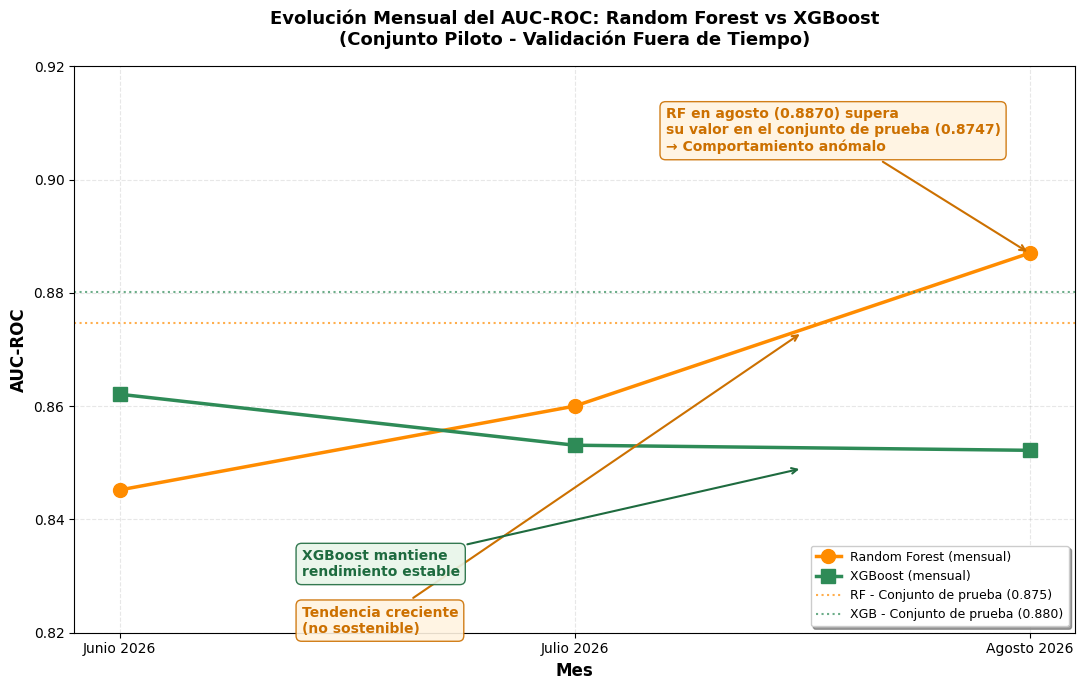

✅ Figura 15 generada correctamente.


In [118]:
# ============================================================
# FIGURA 15: EVOLUCIÓN MENSUAL DEL AUC-ROC
# Random Forest vs XGBoost - Con anotación de anomalía
# ============================================================

import matplotlib.pyplot as plt
import numpy as np

# ------------------------------------------------------------
# 1. DATOS MENSUALES
# ------------------------------------------------------------

import numpy as np
import pandas as pd
from sklearn.metrics import roc_auc_score

# AUC-ROC mensual CALCULADO sobre el conjunto piloto (ya no se escribe a mano)
_MESES_ES = {1:'Enero',2:'Febrero',3:'Marzo',4:'Abril',5:'Mayo',6:'Junio',
             7:'Julio',8:'Agosto',9:'Septiembre',10:'Octubre',11:'Noviembre',12:'Diciembre'}
def auc_mensual(y_real, y_prob):
    d = pd.DataFrame({'mes': pd.to_datetime(df_piloto['fecha_cita']).dt.to_period('M').values,
                      'y': np.asarray(y_real), 'p': np.asarray(y_prob)})
    return {m: roc_auc_score(g['y'], g['p']) for m, g in d.groupby('mes') if g['y'].nunique() > 1}

_rf_m  = auc_mensual(y_piloto, y_proba_rf_piloto)
_xgb_m = auc_mensual(y_piloto, y_proba_xgb_piloto)
_meses_validos = [m for m in _rf_m if m in _xgb_m]   # meses con ambas clases presentes
meses = [f"{_MESES_ES[m.month]} {m.year}" for m in _meses_validos]
auc_rf_mensual  = [round(_rf_m[m], 4)  for m in _meses_validos]
auc_xgb_mensual = [round(_xgb_m[m], 4) for m in _meses_validos]

# Valores de referencia (conjunto de prueba, partición aleatoria): calculados con los modelos
auc_rf_prueba = roc_auc_score(y_test, y_proba_rf)
auc_xgb_prueba = roc_auc_score(y_test, y_proba_xgb)

# ------------------------------------------------------------
# 2. GRÁFICO DE LÍNEAS
# ------------------------------------------------------------

fig, ax = plt.subplots(figsize=(11, 7))

# Líneas de evolución mensual
ax.plot(meses, auc_rf_mensual, marker='o', label='Random Forest (mensual)',
        color='#FF8C00', linewidth=2.5, markersize=10)

ax.plot(meses, auc_xgb_mensual, marker='s', label='XGBoost (mensual)',
        color='#2E8B57', linewidth=2.5, markersize=10)

# Líneas de referencia (conjunto de prueba)
ax.axhline(y=auc_rf_prueba, color='#FF8C00', linestyle=':', linewidth=1.5,
           alpha=0.7, label=f'RF - Conjunto de prueba ({auc_rf_prueba:.3f})')

ax.axhline(y=auc_xgb_prueba, color='#2E8B57', linestyle=':', linewidth=1.5,
           alpha=0.7, label=f'XGB - Conjunto de prueba ({auc_xgb_prueba:.3f})')

# ------------------------------------------------------------
# 3. ANOTACIÓN DE LA ANOMALÍA
# ------------------------------------------------------------

# Resaltar que RF en agosto supera su valor de prueba
ax.annotate(
    f'RF en agosto ({auc_rf_mensual[-1]:.4f}) supera\nsu valor en el conjunto de prueba ({auc_rf_prueba:.4f})\n→ Comportamiento anómalo',
    xy=(len(meses) - 1, auc_rf_mensual[-1]),
    xytext=(1.2, 0.905),
    fontsize=10,
    color='#CC7000',
    fontweight='bold',
    arrowprops=dict(arrowstyle='->', color='#CC7000', lw=1.5),
    bbox=dict(boxstyle='round,pad=0.4', facecolor='#FFF3E0',
              edgecolor='#CC7000', alpha=0.9)
)

# Resaltar la tendencia creciente
ax.annotate(
    'Tendencia creciente\n(no sostenible)',
    xy=(1.5, 0.873),
    xytext=(0.4, 0.82),
    fontsize=10,
    color='#CC7000',
    fontweight='bold',
    arrowprops=dict(arrowstyle='->', color='#CC7000', lw=1.5),
    bbox=dict(boxstyle='round,pad=0.4', facecolor='#FFF3E0',
              edgecolor='#CC7000', alpha=0.9)
)

# Resaltar la estabilidad de XGBoost
ax.annotate(
    'XGBoost mantiene\nrendimiento estable',
    xy=(1.5, 0.849),
    xytext=(0.4, 0.83),
    fontsize=10,
    color='#1E6B3F',
    fontweight='bold',
    arrowprops=dict(arrowstyle='->', color='#1E6B3F', lw=1.5),
    bbox=dict(boxstyle='round,pad=0.4', facecolor='#E8F5E9',
              edgecolor='#1E6B3F', alpha=0.9)
)

# ------------------------------------------------------------
# 4. PERSONALIZACIÓN
# ------------------------------------------------------------

ax.set_xlabel('Mes', fontsize=12, fontweight='bold')
ax.set_ylabel('AUC-ROC', fontsize=12, fontweight='bold')
ax.set_title('Evolución Mensual del AUC-ROC: Random Forest vs XGBoost\n'
             '(Conjunto Piloto - Validación Fuera de Tiempo)',
             fontsize=13, fontweight='bold', pad=15)

ax.set_ylim(0.82, 0.92)
ax.grid(alpha=0.3, linestyle='--')
ax.legend(loc='lower right', fontsize=9, frameon=True, shadow=True)

plt.tight_layout()
plt.savefig('figura_4.2.8.2_evolucion_auc_con_anotacion.png', dpi=300, bbox_inches='tight')
plt.show()

print("✅ Figura 15 generada correctamente.")

### Celda 42 — Comparación de costos de errores: Random Forest vs XGBoost

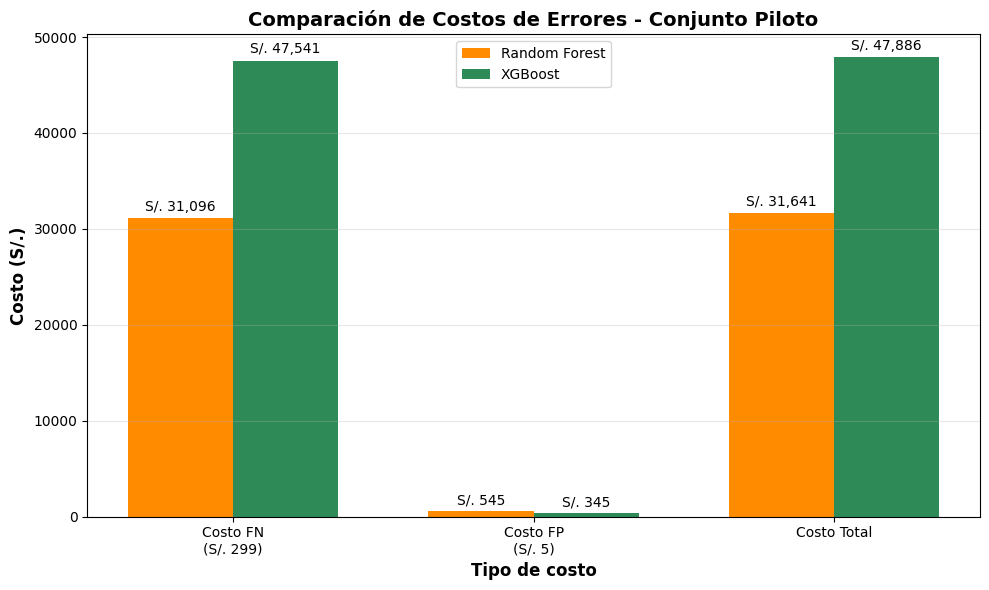

In [119]:

# ============================================================
#  COMPARACIÓN DE COSTOS DE ERRORES
# ============================================================

import numpy as np

categorias = ['Costo FN\n(S/. 299)', 'Costo FP\n(S/. 5)', 'Costo Total']
rf_costos = [31096, 545, 31641]
xgb_costos = [47541, 345, 47886]

x = np.arange(len(categorias))
width = 0.35

fig, ax = plt.subplots(figsize=(10, 6))
bars1 = ax.bar(x - width/2, rf_costos, width, label='Random Forest', color='#FF8C00')
bars2 = ax.bar(x + width/2, xgb_costos, width, label='XGBoost', color='#2E8B57')

ax.set_xlabel('Tipo de costo', fontsize=12, fontweight='bold')
ax.set_ylabel('Costo (S/.)', fontsize=12, fontweight='bold')
ax.set_title('Comparación de Costos de Errores - Conjunto Piloto',
             fontsize=14, fontweight='bold')
ax.set_xticks(x)
ax.set_xticklabels(categorias)
ax.legend()
ax.grid(alpha=0.3, axis='y')

for bars in [bars1, bars2]:
    for bar in bars:
        height = bar.get_height()
        ax.annotate(f'S/. {height:,.0f}',
                    xy=(bar.get_x() + bar.get_width() / 2, height),
                    xytext=(0, 3),
                    textcoords="offset points",
                    ha='center', va='bottom', fontsize=10)

plt.tight_layout()
plt.savefig('figura_4.2.8.3_costos_errores.png', dpi=300)
plt.show()

## 4.2.8 Umbral de decisión, calibración y costo esperado (Celdas 42–52)

### Celda 43 — Curva de trade-off Recall / Precisión / F1 según el umbral de decisión (Figura 16)

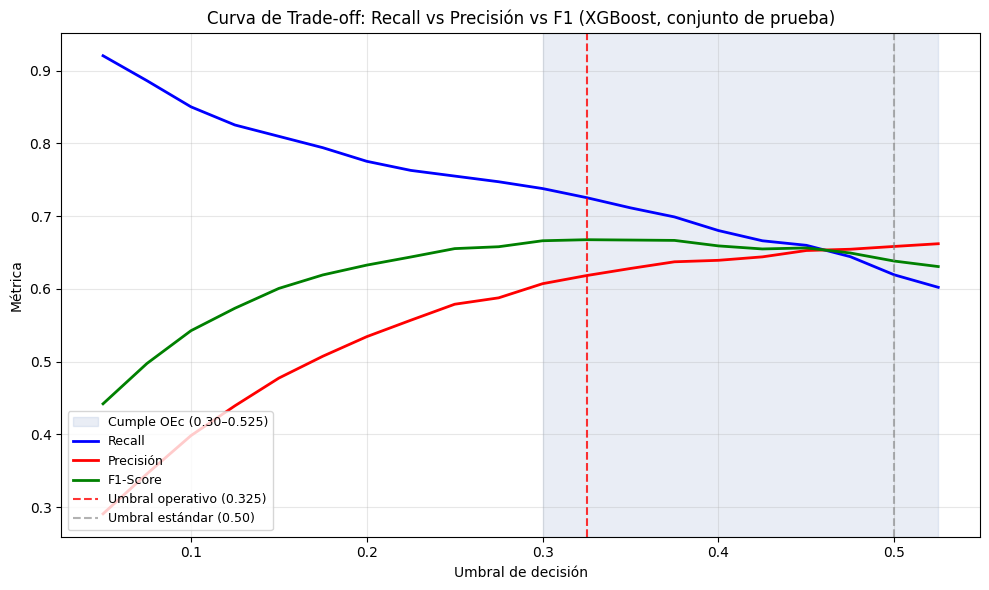

Umbral que maximiza F1 en la prueba: 0.325 (F1 = 0.6676)


In [120]:
# =============================================================================
# CELDA 42: CURVA DE TRADE-OFF RECALL / PRECISIÓN / F1 SEGÚN EL UMBRAL (FIGURA 16)
# Conjunto de prueba. Requiere la Celda 46 (UMBRAL_OPERATIVO, OEC_MIN).
# =============================================================================
import matplotlib.pyplot as plt
import numpy as np
from sklearn.metrics import precision_score, recall_score, f1_score

umbrales = np.round(np.arange(0.05, 0.55, 0.025), 3)
recalls, precisiones, f1s = [], [], []
for u in umbrales:
    y_pred_u = (y_proba_xgb >= u).astype(int)
    recalls.append(recall_score(y_test, y_pred_u))
    precisiones.append(precision_score(y_test, y_pred_u, zero_division=0))
    f1s.append(f1_score(y_test, y_pred_u))
recalls, precisiones, f1s = map(np.array, (recalls, precisiones, f1s))

ok = (recalls >= OEC_MIN) & (precisiones >= OEC_MIN)          # zona que cumple el OEc

plt.figure(figsize=(10, 6))
if ok.any():
    plt.axvspan(umbrales[ok].min(), umbrales[ok].max(), color='#4C72B0', alpha=0.12,
                label=f'Cumple OEc ({umbrales[ok].min():.2f}–{umbrales[ok].max():.3f})')
plt.plot(umbrales, recalls, color='blue', linewidth=2, label='Recall')
plt.plot(umbrales, precisiones, color='red', linewidth=2, label='Precisión')
plt.plot(umbrales, f1s, color='green', linewidth=2, label='F1-Score')

plt.axvline(UMBRAL_OPERATIVO, color='red', linestyle='--', alpha=0.8,
            label=f'Umbral operativo ({UMBRAL_OPERATIVO})')
plt.axvline(0.50, color='gray', linestyle='--', alpha=0.6, label='Umbral estándar (0.50)')

plt.title('Curva de Trade-off: Recall vs Precisión vs F1 (XGBoost, conjunto de prueba)')
plt.xlabel('Umbral de decisión'); plt.ylabel('Métrica')
plt.legend(loc='lower left', fontsize=9); plt.grid(alpha=0.3)
plt.tight_layout()
plt.savefig('figura_16_tradeoff_umbral.png', dpi=300)
plt.show()

i = int(np.argmax(f1s))
print(f"Umbral que maximiza F1 en la prueba: {umbrales[i]:.3f} (F1 = {f1s[i]:.4f})")

### Celda 44 — Curva de umbral: Random Forest

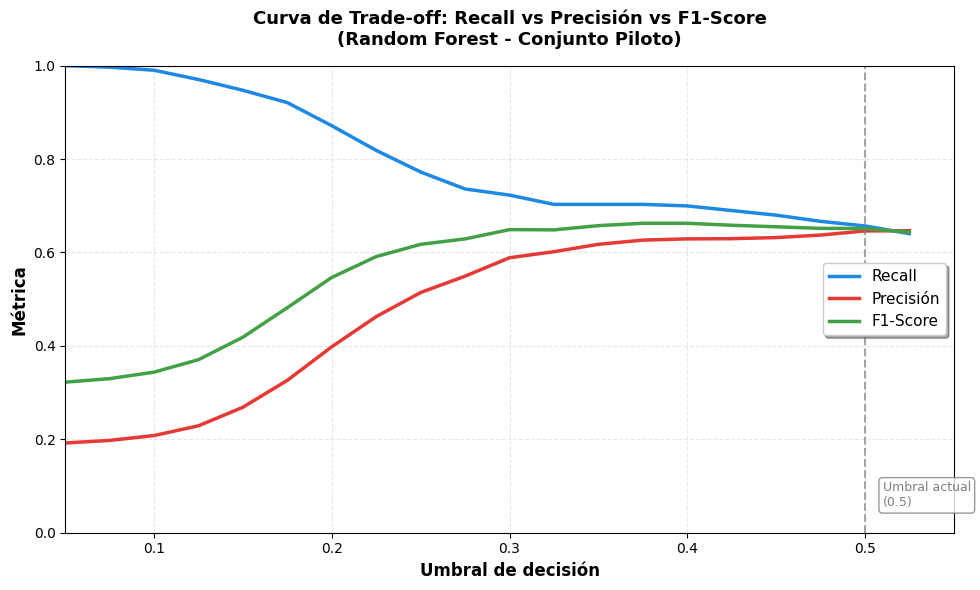


=== Punto óptimo para Random Forest ===
Umbral que maximiza F1-Score: 0.375
F1-Score en ese umbral: 0.6625
Recall en ese umbral: 0.7030
Precisión en ese umbral: 0.6265


In [121]:
# ============================================================
# CURVA DE UMBRAL: RANDOM FOREST
# Recall vs Precisión vs F1-Score según el umbral de decisión
# ============================================================

import matplotlib.pyplot as plt
import numpy as np
from sklearn.metrics import precision_score, recall_score, f1_score

# ------------------------------------------------------------
# 1. CALCULAR LAS MÉTRICAS PARA DIFERENTES UMBRALES
# ------------------------------------------------------------

umbrales = np.arange(0.05, 0.55, 0.025)
recalls_rf, precisions_rf, f1s_rf = [], [], []

for u in umbrales:
    y_pred_u = (y_proba_rf_piloto >= u).astype(int)
    recalls_rf.append(recall_score(y_piloto, y_pred_u, zero_division=0))
    precisions_rf.append(precision_score(y_piloto, y_pred_u, zero_division=0))
    f1s_rf.append(f1_score(y_piloto, y_pred_u, zero_division=0))

# ------------------------------------------------------------
# 2. GRÁFICO DE LA CURVA DE UMBRAL
# ------------------------------------------------------------

fig, ax = plt.subplots(figsize=(10, 6))

# Curvas
ax.plot(umbrales, recalls_rf, color='#1E88E5', linewidth=2.5, label='Recall')
ax.plot(umbrales, precisions_rf, color='#E53935', linewidth=2.5, label='Precisión')
ax.plot(umbrales, f1s_rf, color='#43A047', linewidth=2.5, label='F1-Score')

# Línea vertical en el umbral actual (0.50)
umbral_referencia = 0.50
ax.axvline(umbral_referencia, color='gray', linestyle='--', alpha=0.7, linewidth=1.5)
ax.text(
    umbral_referencia + 0.01, 0.05,
    f'Umbral actual\n({umbral_referencia})',
    fontsize=9, color='gray',
    ha='left', va='bottom',
    bbox=dict(boxstyle='round,pad=0.3', facecolor='white',
              edgecolor='gray', alpha=0.8)
)

# ------------------------------------------------------------
# 3. PERSONALIZACIÓN
# ------------------------------------------------------------

ax.set_xlabel('Umbral de decisión', fontsize=12, fontweight='bold')
ax.set_ylabel('Métrica', fontsize=12, fontweight='bold')
ax.set_title(
    'Curva de Trade-off: Recall vs Precisión vs F1-Score\n(Random Forest - Conjunto Piloto)',
    fontsize=13, fontweight='bold', pad=15
)

ax.set_xlim(0.05, 0.55)
ax.set_ylim(0, 1.0)
ax.grid(alpha=0.3, linestyle='--')
ax.legend(loc='center right', fontsize=11, frameon=True, shadow=True)

# ------------------------------------------------------------
# 4. GUARDAR Y MOSTRAR
# ------------------------------------------------------------

plt.tight_layout()
plt.savefig('figura_curva_umbral_random_forest.png', dpi=300, bbox_inches='tight')
plt.show()

# ------------------------------------------------------------
# 5. PUNTO ÓPTIMO (UMBRAL QUE MAXIMIZA F1-SCORE)
# ------------------------------------------------------------

idx_max_f1 = np.argmax(f1s_rf)
print(f"\n=== Punto óptimo para Random Forest ===")
print(f"Umbral que maximiza F1-Score: {umbrales[idx_max_f1]:.3f}")
print(f"F1-Score en ese umbral: {f1s_rf[idx_max_f1]:.4f}")
print(f"Recall en ese umbral: {recalls_rf[idx_max_f1]:.4f}")
print(f"Precisión en ese umbral: {precisions_rf[idx_max_f1]:.4f}")

### Celda 45 — Curva de umbral comparativa: Random Forest vs XGBoost

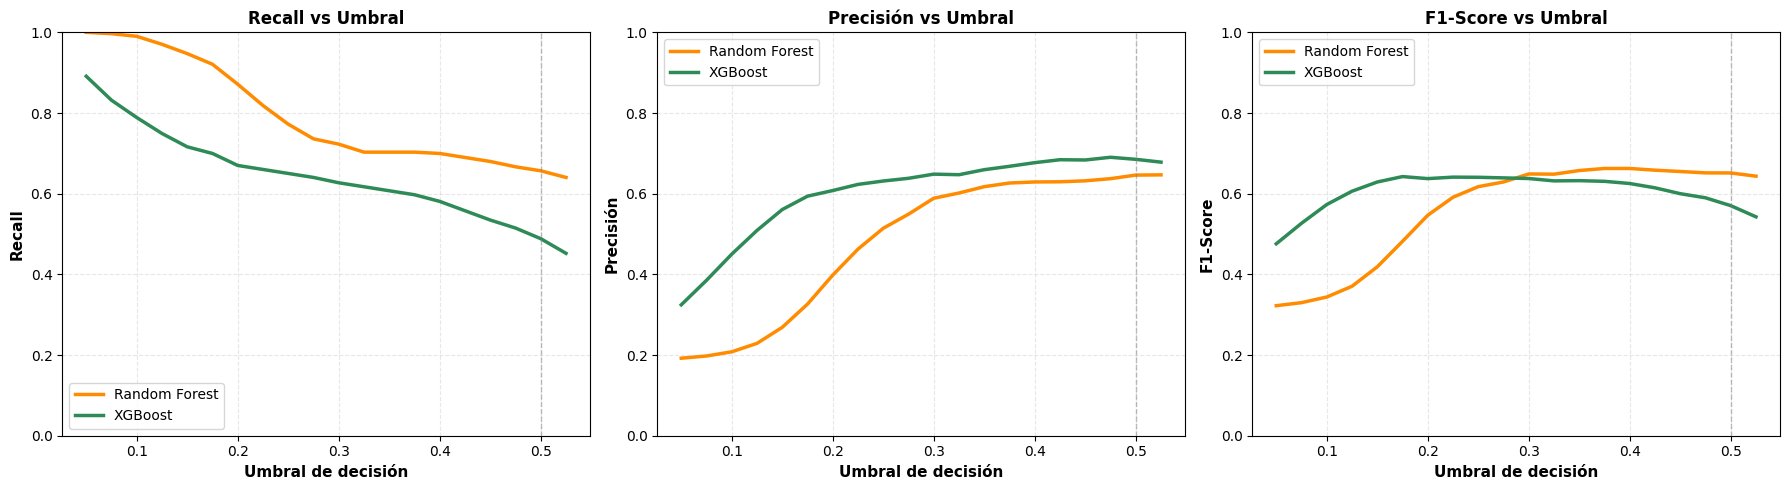

In [122]:
# ============================================================
# CURVA DE UMBRAL COMPARATIVA: RANDOM FOREST vs XGBOOST
# ============================================================

import matplotlib.pyplot as plt
import numpy as np
from sklearn.metrics import precision_score, recall_score, f1_score

# ------------------------------------------------------------
# 1. CALCULAR LAS MÉTRICAS PARA AMBOS MODELOS
# ------------------------------------------------------------

umbrales = np.arange(0.05, 0.55, 0.025)

# Random Forest
recalls_rf, precisions_rf, f1s_rf = [], [], []
for u in umbrales:
    y_pred_u = (y_proba_rf_piloto >= u).astype(int)
    recalls_rf.append(recall_score(y_piloto, y_pred_u, zero_division=0))
    precisions_rf.append(precision_score(y_piloto, y_pred_u, zero_division=0))
    f1s_rf.append(f1_score(y_piloto, y_pred_u, zero_division=0))

# XGBoost
recalls_xgb, precisions_xgb, f1s_xgb = [], [], []
for u in umbrales:
    y_pred_u = (y_proba_xgb_piloto >= u).astype(int)
    recalls_xgb.append(recall_score(y_piloto, y_pred_u, zero_division=0))
    precisions_xgb.append(precision_score(y_piloto, y_pred_u, zero_division=0))
    f1s_xgb.append(f1_score(y_piloto, y_pred_u, zero_division=0))

# ------------------------------------------------------------
# 2. GRÁFICO COMPARATIVO (3 SUBPLOTS)
# ------------------------------------------------------------

fig, axes = plt.subplots(1, 3, figsize=(18, 5))

# --- Gráfico 1: Recall ---
axes[0].plot(umbrales, recalls_rf, color='#FF8C00', linewidth=2.5, label='Random Forest')
axes[0].plot(umbrales, recalls_xgb, color='#2E8B57', linewidth=2.5, label='XGBoost')
axes[0].axvline(0.50, color='gray', linestyle='--', alpha=0.5, linewidth=1)
axes[0].set_xlabel('Umbral de decisión', fontsize=11, fontweight='bold')
axes[0].set_ylabel('Recall', fontsize=11, fontweight='bold')
axes[0].set_title('Recall vs Umbral', fontsize=12, fontweight='bold')
axes[0].legend()
axes[0].grid(alpha=0.3, linestyle='--')
axes[0].set_ylim(0, 1.0)

# --- Gráfico 2: Precisión ---
axes[1].plot(umbrales, precisions_rf, color='#FF8C00', linewidth=2.5, label='Random Forest')
axes[1].plot(umbrales, precisions_xgb, color='#2E8B57', linewidth=2.5, label='XGBoost')
axes[1].axvline(0.50, color='gray', linestyle='--', alpha=0.5, linewidth=1)
axes[1].set_xlabel('Umbral de decisión', fontsize=11, fontweight='bold')
axes[1].set_ylabel('Precisión', fontsize=11, fontweight='bold')
axes[1].set_title('Precisión vs Umbral', fontsize=12, fontweight='bold')
axes[1].legend()
axes[1].grid(alpha=0.3, linestyle='--')
axes[1].set_ylim(0, 1.0)

# --- Gráfico 3: F1-Score ---
axes[2].plot(umbrales, f1s_rf, color='#FF8C00', linewidth=2.5, label='Random Forest')
axes[2].plot(umbrales, f1s_xgb, color='#2E8B57', linewidth=2.5, label='XGBoost')
axes[2].axvline(0.50, color='gray', linestyle='--', alpha=0.5, linewidth=1)
axes[2].set_xlabel('Umbral de decisión', fontsize=11, fontweight='bold')
axes[2].set_ylabel('F1-Score', fontsize=11, fontweight='bold')
axes[2].set_title('F1-Score vs Umbral', fontsize=12, fontweight='bold')
axes[2].legend()
axes[2].grid(alpha=0.3, linestyle='--')
axes[2].set_ylim(0, 1.0)

plt.tight_layout()
plt.savefig('figura_curva_umbral_comparativa.png', dpi=300, bbox_inches='tight')
plt.show()

### Celda 46 — Elección del umbral en la prueba y confirmación en el piloto: umbral operativo 0.325 (Tabla 34)

In [123]:
# CELDA 45: UMBRAL DE DECISIÓN — ELECCIÓN EN PRUEBA Y CONFIRMACIÓN EN EL PILOTO
import numpy as np
import pandas as pd
from sklearn.metrics import precision_score, recall_score, f1_score

for _v in ['y_test', 'y_proba_xgb', 'y_piloto', 'y_proba_piloto']:
    if _v not in globals():
        raise NameError(f"❌ Falta '{_v}'. Ejecuta primero las Celdas 16-18 y 30-35.")

OEC_MIN = 0.60                                    # Precisión y Recall mínimos (OEc)
GRILLA = np.round(np.arange(0.05, 0.55, 0.025), 3)

def tabla_umbrales(y, proba, grilla=GRILLA):
    y = np.asarray(y); proba = np.asarray(proba); filas = []
    for u in grilla:
        pred = (proba >= u).astype(int)
        p = precision_score(y, pred, zero_division=0)
        r = recall_score(y, pred, zero_division=0)
        f = f1_score(y, pred, zero_division=0)
        filas.append({'Umbral': u, 'Precisión': round(p, 4), 'Recall': round(r, 4),
                      'F1': round(f, 4),
                      'Cumple OEc': 'Sí' if (p >= OEC_MIN and r >= OEC_MIN) else 'No'})
    return pd.DataFrame(filas)

def umbral_por_regla(df):
    """Máximo F1 entre los umbrales que cumplen el OEc (si ninguno cumple, máximo F1)."""
    cand = df[df['Cumple OEc'] == 'Sí']
    base = cand if not cand.empty else df
    return float(base.loc[base['F1'].idxmax(), 'Umbral'])

print("=" * 70)
print("UMBRAL DE DECISIÓN (XGBoost): ELEGIDO EN PRUEBA, CONFIRMADO EN EL PILOTO")
print("=" * 70)

# 1) Elección en el conjunto de PRUEBA (datos distintos al piloto)
tab_prueba = tabla_umbrales(y_test, y_proba_xgb)
UMBRAL_OPERATIVO = umbral_por_regla(tab_prueba)   # <- umbral único para Celdas 47-49 y 47B
print("\n=== Tabla de umbrales en el conjunto de PRUEBA ===")
print(tab_prueba.to_string(index=False))
print(f"\n>>> UMBRAL OPERATIVO (elegido en la prueba): {UMBRAL_OPERATIVO}")

# 2) Confirmación en el PILOTO (tabla descriptiva; NO se usa para elegir)
tab_piloto = tabla_umbrales(y_piloto, y_proba_piloto)
print("\n=== Tabla de umbrales en el PILOTO (solo confirmación) ===")
print(tab_piloto.to_string(index=False))

fila = tab_piloto[np.isclose(tab_piloto['Umbral'], UMBRAL_OPERATIVO)].iloc[0]
print("\n" + "=" * 70)
print(f"Umbral {UMBRAL_OPERATIVO} en el piloto: Precisión = {fila['Precisión']} | "
      f"Recall = {fila['Recall']} | F1 = {fila['F1']} | Cumple OEc: {fila['Cumple OEc']}")
rango_ok = tab_piloto.loc[tab_piloto['Cumple OEc'] == 'Sí', 'Umbral']
if not rango_ok.empty:
    print(f"Rango de umbrales que cumplen el OEc en el piloto: {rango_ok.min()} – {rango_ok.max()}")
print("=" * 70)

UMBRAL DE DECISIÓN (XGBoost): ELEGIDO EN PRUEBA, CONFIRMADO EN EL PILOTO

=== Tabla de umbrales en el conjunto de PRUEBA ===
 Umbral  Precisión  Recall     F1 Cumple OEc
  0.050     0.2909  0.9204 0.4421         No
  0.075     0.3459  0.8861 0.4976         No
  0.100     0.3984  0.8502 0.5426         No
  0.125     0.4394  0.8253 0.5734         No
  0.150     0.4775  0.8097 0.6007         No
  0.175     0.5075  0.7941 0.6192         No
  0.200     0.5344  0.7754 0.6327         No
  0.225     0.5569  0.7629 0.6438         No
  0.250     0.5789  0.7551 0.6554         No
  0.275     0.5877  0.7473 0.6580         No
  0.300     0.6072  0.7379 0.6662         Sí
  0.325     0.6184  0.7254 0.6676         Sí
  0.350     0.6281  0.7114 0.6672         Sí
  0.375     0.6373  0.6989 0.6667         Sí
  0.400     0.6393  0.6802 0.6591         Sí
  0.425     0.6440  0.6661 0.6549         Sí
  0.450     0.6528  0.6599 0.6563         Sí
  0.475     0.6545  0.6443 0.6494         Sí
  0.500     0.6584  

### Celda 47 — Validación fuera de muestra y estabilidad del umbral 0.325

In [124]:

# CELDA 47: VALIDACIÓN FUERA DE MUESTRA Y ESTABILIDAD DEL UMBRAL 0.325
# A) Umbral elegido en PRUEBA, confirmado en el piloto completo (sin reajuste).
# B) Estabilidad: el MISMO umbral en prueba, piloto, mes 1, meses 2-3 y cada mes.
# C) Umbral elegido en el mes 1 del piloto, confirmado en los meses 2-3 (contraste).
import numpy as np
import pandas as pd
from sklearn.metrics import precision_score, recall_score, f1_score

assert len(y_piloto) == len(df_piloto) == len(y_proba_piloto), \
    "y_piloto, y_proba_piloto y df_piloto deben estar alineados fila a fila"

def metricas(y, proba, u):
    pred = (proba >= u).astype(int)
    p = precision_score(y, pred, zero_division=0)
    r = recall_score(y, pred, zero_division=0)
    f = f1_score(y, pred, zero_division=0)
    vp = int(((pred == 1) & (y == 1)).sum()); fp = int(((pred == 1) & (y == 0)).sum())
    return p, r, f, int(pred.sum()), vp, fp

def fila(nombre, u, y, pr):
    p, r, f, al, vp, fp = metricas(y, pr, u)
    return {'Conjunto': nombre, 'Umbral': u, 'N': len(y),
            'No-show (%)': round(100 * y.mean(), 1), 'Precisión': round(p, 4),
            'Recall': round(r, 4), 'F1': round(f, 4), 'Alertas': al, 'VP': vp, 'FP': fp,
            'Cumple OEc': 'Sí' if (p >= OEC_MIN and r >= OEC_MIN) else 'No'}

y_p, pr_p = np.asarray(y_piloto), np.asarray(y_proba_piloto)
y_t, pr_t = np.asarray(y_test), np.asarray(y_proba_xgb)
fechas = pd.to_datetime(df_piloto['fecha_cita']).reset_index(drop=True)
corte = fechas.min().normalize() + pd.DateOffset(months=1)   # 1 mes desde el inicio del piloto
m1 = (fechas < corte).values; m23 = ~m1

print("=" * 70)
print(f"A) UMBRAL ELEGIDO EN LA PRUEBA = {UMBRAL_OPERATIVO} -> CONFIRMADO EN EL PILOTO")
print("=" * 70)
resA = pd.DataFrame([fila("Prueba (donde se eligió)", UMBRAL_OPERATIVO, y_t, pr_t),
                     fila("Piloto completo", UMBRAL_OPERATIVO, y_p, pr_p)])
print(resA.to_string(index=False))

print("\n" + "=" * 70)
print(f"B) ESTABILIDAD DEL UMBRAL {UMBRAL_OPERATIVO} (sin reajustarlo)")
print("=" * 70)
filasB = [fila("Prueba", UMBRAL_OPERATIVO, y_t, pr_t),
          fila("Piloto completo", UMBRAL_OPERATIVO, y_p, pr_p),
          fila(f"Piloto mes 1 (< {corte.date()})", UMBRAL_OPERATIVO, y_p[m1], pr_p[m1]),
          fila("Piloto meses 2-3", UMBRAL_OPERATIVO, y_p[m23], pr_p[m23])]
mes = fechas.dt.to_period('M').values
for per in sorted(set(mes)):
    mm = (mes == per)
    filasB.append(fila(f"Piloto {per}", UMBRAL_OPERATIVO, y_p[mm], pr_p[mm]))
resB = pd.DataFrame(filasB)
print(resB.to_string(index=False))
n_ok = int((resB['Cumple OEc'] == 'Sí').sum())
print(f"\nConjuntos que cumplen el OEc con el umbral {UMBRAL_OPERATIVO}: {n_ok} de {len(resB)}")

print("\n" + "=" * 70)
print("C) CONTRASTE: UMBRAL ELEGIDO EN EL MES 1 DEL PILOTO -> CONFIRMADO EN MESES 2-3")
print("=" * 70)
u_mes1 = umbral_por_regla(tabla_umbrales(y_p[m1], pr_p[m1]))
print(f"N mes 1 = {m1.sum()} (no-shows ≈ {int(y_p[m1].sum())}): umbral poco estable por muestra pequeña.")
resC = pd.DataFrame([fila("Meses 2-3 con umbral del mes 1", u_mes1, y_p[m23], pr_p[m23]),
                     fila("Meses 2-3 con umbral operativo", UMBRAL_OPERATIVO, y_p[m23], pr_p[m23]),
                     fila("Piloto completo con 0.50 (estándar)", 0.50, y_p, pr_p)])
print(resC.to_string(index=False))

A) UMBRAL ELEGIDO EN LA PRUEBA = 0.325 -> CONFIRMADO EN EL PILOTO
                Conjunto  Umbral    N  No-show (%)  Precisión  Recall     F1  Alertas  VP  FP Cumple OEc
Prueba (donde se eligió)   0.325 3702         17.3     0.6184  0.7254 0.6676      752 465 287         Sí
         Piloto completo   0.325 1591         19.0     0.6471  0.6172 0.6318      289 187 102         Sí

B) ESTABILIDAD DEL UMBRAL 0.325 (sin reajustarlo)
                   Conjunto  Umbral    N  No-show (%)  Precisión  Recall     F1  Alertas  VP  FP Cumple OEc
                     Prueba   0.325 3702         17.3     0.6184  0.7254 0.6676      752 465 287         Sí
            Piloto completo   0.325 1591         19.0     0.6471  0.6172 0.6318      289 187 102         Sí
Piloto mes 1 (< 2026-06-30)   0.325  472         17.8     0.6076  0.5714 0.5890       79  48  31         No
           Piloto meses 2-3   0.325 1119         19.6     0.6619  0.6347 0.6480      210 139  71         Sí
             Piloto 2026-05 

### Celda 48 — Comparación de escenarios: tres niveles vs. dos niveles (Tabla 26)

In [125]:

# CELDA 48: TABLA 26 — COMPARACIÓN DE ESCENARIOS (TRES NIVELES VS. DOS NIVELES)
import pandas as pd
import numpy as np

print("=" * 60)
print("TABLA 26: COMPARACIÓN DE ESCENARIOS DE NIVELES DE RIESGO")
print("=" * 60)

y_true = np.asarray(y_piloto); y_proba = np.asarray(y_proba_piloto)

UMBRAL_BAJO = UMBRAL_OPERATIVO     # mismo corte Bajo/no-Bajo que la Celda 49 (0.325)
UMBRAL_ALTO = 0.55

def tres_niveles(p):
    return 'Bajo' if p < UMBRAL_BAJO else ('Medio' if p < UMBRAL_ALTO else 'Alto')
def dos_niveles(p):
    return 'Bajo' if p < UMBRAL_BAJO else 'Alto (fusionado)'

def resumir(niveles):
    d = pd.DataFrame({'nivel': niveles, 'real': y_true})
    r = d.groupby('nivel').agg(N_citas=('real', 'count'), No_shows=('real', 'sum'),
                               Tasa_No_Show=('real', 'mean')).reset_index()
    r['Tasa_No_Show'] = (r['Tasa_No_Show'] * 100).round(1)
    return r

r3 = resumir([tres_niveles(p) for p in y_proba]); r3.insert(0, 'Escenario', 'Tres niveles')
r2 = resumir([dos_niveles(p) for p in y_proba]);  r2.insert(0, 'Escenario', 'Dos niveles')
orden = {'Bajo': 1, 'Medio': 2, 'Alto': 3, 'Alto (fusionado)': 3}
tabla = pd.concat([r3, r2]).rename(columns={'nivel': 'Nivel', 'N_citas': 'N.° de citas',
          'No_shows': 'No-shows reales', 'Tasa_No_Show': 'Tasa real de No-Show (%)'})
tabla['o'] = tabla['Nivel'].map(orden)
tabla = tabla.sort_values(['Escenario', 'o'], ascending=[False, True]).drop(columns='o')

print(f"Cortes: Bajo < {UMBRAL_BAJO} | Medio {UMBRAL_BAJO}-{UMBRAL_ALTO} | Alto ≥ {UMBRAL_ALTO}\n")
print(tabla.to_string(index=False))
tabla.to_csv('tabla_4.2.7.2_comparacion_niveles.csv', index=False)
print("\n✅ Tabla guardada como 'tabla_4.2.7.2_comparacion_niveles.csv'")


TABLA 26: COMPARACIÓN DE ESCENARIOS DE NIVELES DE RIESGO
Cortes: Bajo < 0.325 | Medio 0.325-0.55 | Alto ≥ 0.55

   Escenario            Nivel  N.° de citas  No-shows reales  Tasa real de No-Show (%)
Tres niveles             Bajo          1302              116                       8.9
Tres niveles            Medio            95               57                      60.0
Tres niveles             Alto           194              130                      67.0
 Dos niveles             Bajo          1302              116                       8.9
 Dos niveles Alto (fusionado)           289              187                      64.7

✅ Tabla guardada como 'tabla_4.2.7.2_comparacion_niveles.csv'


### Celda 49 — Tasa real de no-show por nivel de riesgo (umbral operativo 0.325, Tabla 35)

In [126]:

# CELDA 49: TASA REAL DE NO-SHOW POR NIVEL DE RIESGO (UMBRAL OPERATIVO 0.325)
import pandas as pd
import numpy as np

print("=" * 60)
print(f"TASA REAL DE NO-SHOW POR NIVEL DE RIESGO (UMBRAL {UMBRAL_OPERATIVO})")
print("=" * 60)

y_true = np.asarray(y_piloto); y_proba = np.asarray(y_proba_piloto)

def wilson(k, n, z=1.96):
    if n == 0: return (np.nan, np.nan)
    p = k / n; d = 1 + z**2 / n
    c = (p + z**2 / (2 * n)) / d
    h = z * np.sqrt(p * (1 - p) / n + z**2 / (4 * n**2)) / d
    return c - h, c + h

niveles = np.where(y_proba >= UMBRAL_OPERATIVO, 'Medio/Alto', 'Bajo')
filas = []
for nivel in ['Bajo', 'Medio/Alto']:
    m = niveles == nivel
    n, k = int(m.sum()), int(y_true[m].sum())
    lo, hi = wilson(k, n)
    filas.append({'nivel_riesgo': nivel, 'N_citas': n, 'No_shows': k,
                  'Tasa_No_Show (%)': round(100 * k / n, 1),
                  'IC95% Wilson (%)': f"{100*lo:.1f} – {100*hi:.1f}"})
resumen = pd.DataFrame(filas)

print(f"\n=== TABLA: TASA REAL DE NO-SHOW POR NIVEL DE RIESGO (UMBRAL {UMBRAL_OPERATIVO}) ===")
print(resumen.to_string(index=False))

vp = int(resumen.loc[1, 'No_shows']); fn = int(resumen.loc[0, 'No_shows'])
print(f"\nCaptura: {vp} de {vp + fn} no-shows quedan en Medio/Alto (recall = {vp/(vp+fn):.4f}); "
      f"precisión del nivel Medio/Alto = {vp/resumen.loc[1,'N_citas']:.4f}.")
resumen.to_csv('tabla_tasa_no_show_umbral_0325.csv', index=False)
print("\n✅ Tabla guardada como 'tabla_tasa_no_show_umbral_0325.csv'")


TASA REAL DE NO-SHOW POR NIVEL DE RIESGO (UMBRAL 0.325)

=== TABLA: TASA REAL DE NO-SHOW POR NIVEL DE RIESGO (UMBRAL 0.325) ===
nivel_riesgo  N_citas  No_shows  Tasa_No_Show (%) IC95% Wilson (%)
        Bajo     1302       116               8.9       7.5 – 10.6
  Medio/Alto      289       187              64.7      59.0 – 70.0

Captura: 187 de 303 no-shows quedan en Medio/Alto (recall = 0.6172); precisión del nivel Medio/Alto = 0.6471.

✅ Tabla guardada como 'tabla_tasa_no_show_umbral_0325.csv'


### Celda 50 — Curva de calibración y Brier score

CURVA DE CALIBRACIÓN Y BRIER SCORE (XGBOOST)
✅ Usando predicciones del piloto ya calculadas (y_proba_piloto).

Brier Score: 0.1069
Interpretación: Un Brier Score más bajo indica mejor calibración.
Un modelo perfecto tendría Brier Score = 0.0


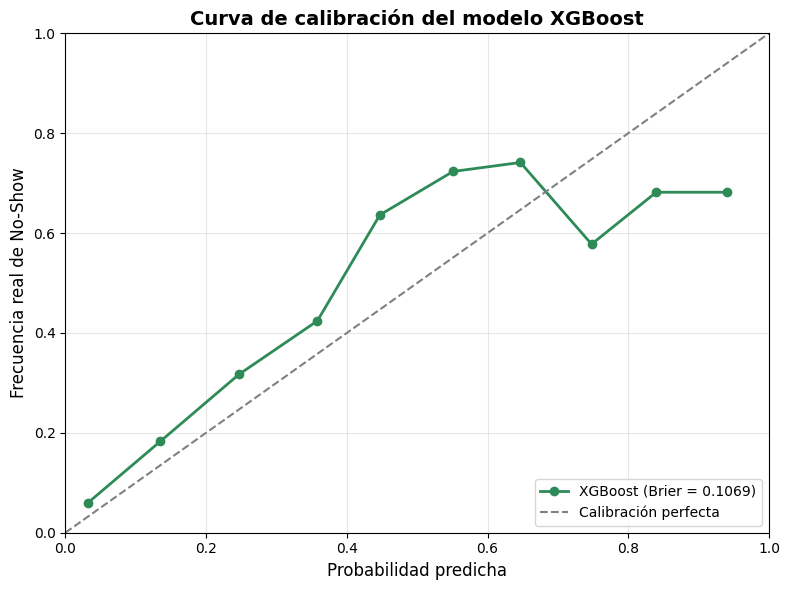


✅ Gráfico guardado como 'figura_17_calibracion_xgboost.png'


In [127]:
# =============================================================================
# CELDA 50: CURVA DE CALIBRACIÓN Y BRIER SCORE (AUTOCONTENIDA)
# =============================================================================
import numpy as np
import matplotlib.pyplot as plt
from sklearn.calibration import calibration_curve
from sklearn.metrics import brier_score_loss

print("="*60)
print("CURVA DE CALIBRACIÓN Y BRIER SCORE (XGBOOST)")
print("="*60)

# --- 1. Verificar si las predicciones del piloto existen; si no, calcularlas ---
try:
    y_true = y_piloto
    y_proba = y_proba_piloto
    print("✅ Usando predicciones del piloto ya calculadas (y_proba_piloto).")
except NameError:
    print("⚠️ Variables del piloto no encontradas. Recalculando predicciones...")
    # Verificar que el modelo y los datos del piloto existan
    if 'xgb_final' not in locals() or 'X_piloto_scaled' not in locals():
        raise NameError("❌ El modelo 'xgb_final' o 'X_piloto_scaled' no están definidos. Ejecuta primero las Celdas 17 y 18.")

    # Calcular predicciones del piloto
    y_proba = xgb_final.predict_proba(X_piloto_scaled)[:, 1]
    y_true = y_piloto
    print("✅ Predicciones del piloto recalculadas correctamente.")

# --- 2. Calcular la curva de calibración ---
prob_true, prob_pred = calibration_curve(y_true, y_proba, n_bins=10, strategy='uniform')

# --- 3. Calcular el Brier Score ---
brier = brier_score_loss(y_true, y_proba)

print(f"\nBrier Score: {brier:.4f}")
print("Interpretación: Un Brier Score más bajo indica mejor calibración.")
print("Un modelo perfecto tendría Brier Score = 0.0")

# --- 4. Generar el gráfico de calibración ---
fig, ax = plt.subplots(figsize=(8, 6))

# Curva de calibración del modelo
ax.plot(prob_pred, prob_true, marker='o', linewidth=2, label=f'XGBoost (Brier = {brier:.4f})', color='#2E8B57')

# Línea diagonal (calibración perfecta)
ax.plot([0, 1], [0, 1], linestyle='--', color='gray', label='Calibración perfecta')

# Personalización
ax.set_xlabel('Probabilidad predicha', fontsize=12)
ax.set_ylabel('Frecuencia real de No-Show', fontsize=12)
ax.set_title('Curva de calibración del modelo XGBoost', fontsize=14, fontweight='bold')
ax.legend(loc='lower right')
ax.grid(alpha=0.3)
ax.set_xlim([0, 1])
ax.set_ylim([0, 1])

plt.tight_layout()
plt.savefig('figura_4.2.8.2_calibracion_xgboost.png', dpi=300)
plt.show()

print("\n✅ Gráfico guardado como 'figura_17_calibracion_xgboost.png'")

### Celda 51 —  tasa real de no-show por nivel de riesgo (conjunto de prueba)

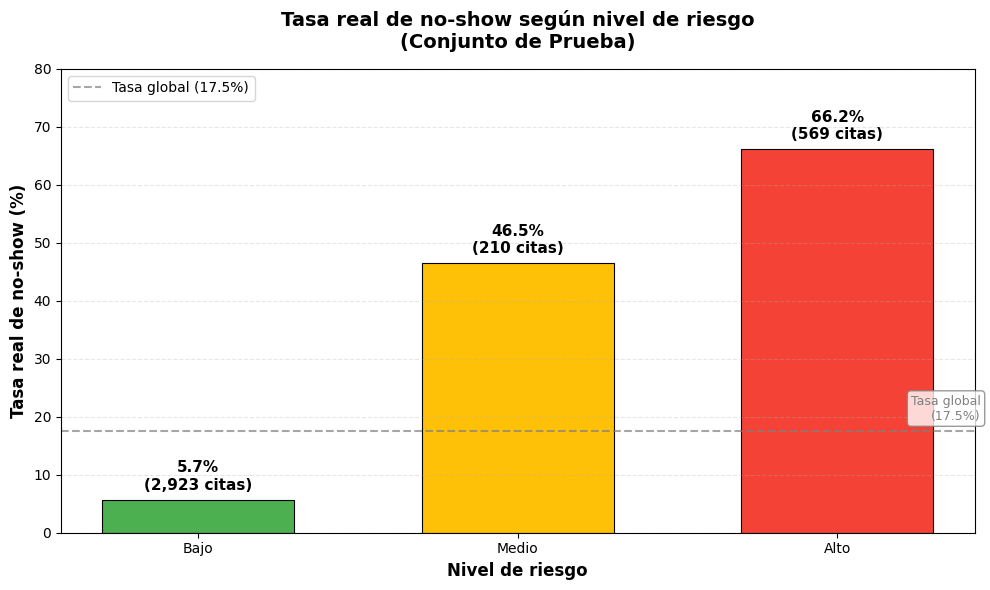

Figura 4.2.7 generada correctamente.


In [128]:
# ============================================================
# FIGURA 4.2.7: TASA REAL DE NO-SHOW POR NIVEL DE RIESGO
# (Conjunto de prueba)
# ============================================================

import matplotlib.pyplot as plt
import numpy as np

# ------------------------------------------------------------
# 1. DATOS DEL SCORE DE RIESGO EN EL CONJUNTO DE PRUEBA
# ------------------------------------------------------------

niveles = ['Bajo', 'Medio', 'Alto']
citas = [2923, 210, 569]
tasas = [5.7, 46.5, 66.2]

# Tasa global de no-show (para línea de referencia)
tasa_global = 17.5

# ------------------------------------------------------------
# 2. GRÁFICO DE BARRAS
# ------------------------------------------------------------

fig, ax = plt.subplots(figsize=(10, 6))

# Colores diferenciados por nivel de riesgo (verde, amarillo, rojo)
colores = ['#4CAF50', '#FFC107', '#F44336']

bars = ax.bar(
    niveles, tasas,
    color=colores,
    edgecolor='black',
    linewidth=0.8,
    width=0.6
)

# Agregar etiquetas de valores sobre las barras
for bar, tasa, n in zip(bars, tasas, citas):
    height = bar.get_height()
    ax.annotate(
        f'{tasa:.1f}%\n({n:,} citas)',
        xy=(bar.get_x() + bar.get_width() / 2, height),
        xytext=(0, 5),
        textcoords="offset points",
        ha='center', va='bottom',
        fontsize=11, fontweight='bold'
    )

# ------------------------------------------------------------
# 3. LÍNEA DE REFERENCIA (TASA GLOBAL)
# ------------------------------------------------------------

ax.axhline(
    y=tasa_global,
    color='gray',
    linestyle='--',
    linewidth=1.5,
    alpha=0.7,
    label=f'Tasa global ({tasa_global}%)'
)

# Anotación de la tasa global
ax.text(
    2.45, tasa_global + 1.5,
    f'Tasa global\n({tasa_global}%)',
    fontsize=9,
    color='gray',
    ha='right', va='bottom',
    bbox=dict(boxstyle='round,pad=0.3', facecolor='white',
              edgecolor='gray', alpha=0.8)
)

# ------------------------------------------------------------
# 4. PERSONALIZACIÓN DEL GRÁFICO
# ------------------------------------------------------------

ax.set_xlabel('Nivel de riesgo', fontsize=12, fontweight='bold')
ax.set_ylabel('Tasa real de no-show (%)', fontsize=12, fontweight='bold')
ax.set_title(
    'Tasa real de no-show según nivel de riesgo\n(Conjunto de Prueba)',
    fontsize=14, fontweight='bold', pad=15
)
ax.set_ylim(0, 80)
ax.grid(alpha=0.3, axis='y', linestyle='--')
ax.legend(loc='upper left', fontsize=10)

# ------------------------------------------------------------
# 5. GUARDAR Y MOSTRAR
# ------------------------------------------------------------

plt.tight_layout()
plt.savefig('figura_4.2.7_tasa_no_show_por_riesgo.png', dpi=300, bbox_inches='tight')
plt.show()

print("Figura 4.2.7 generada correctamente.")

### Celda 52 — Figura 13: tasa real de no-show por nivel de riesgo (prueba vs. piloto, RF y XGBoost)

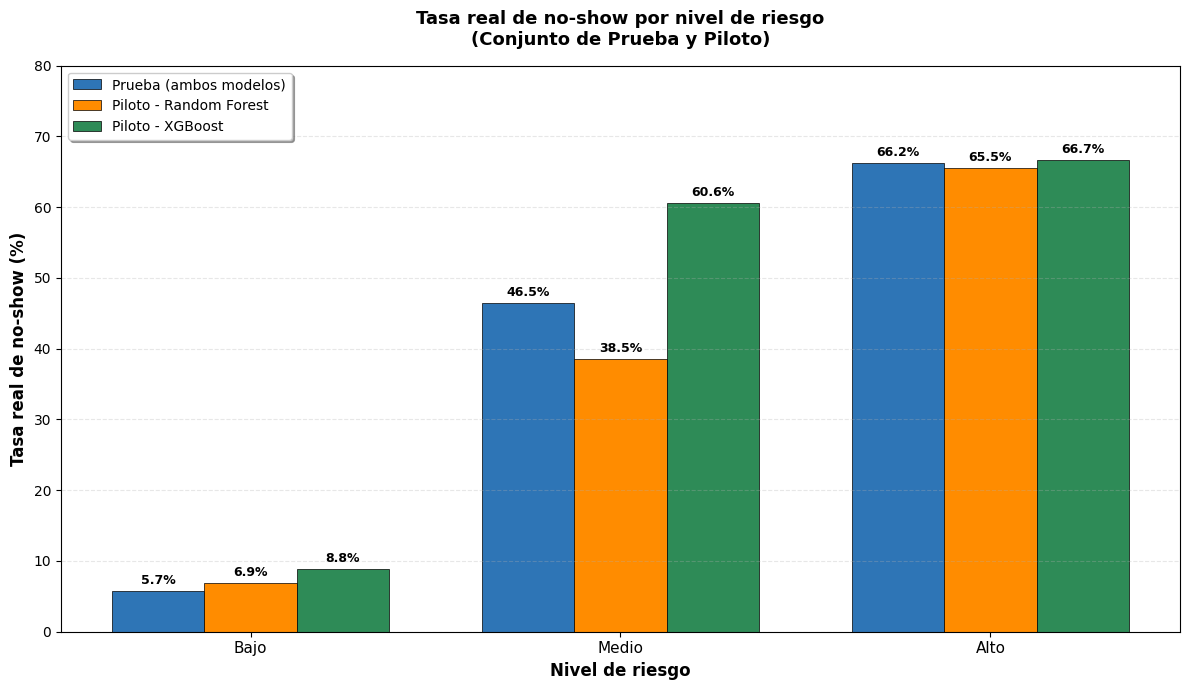

✅ Figura 4.2.7 generada correctamente.


In [129]:
# ============================================================
# FIGURA 13: TASA REAL DE NO-SHOW POR NIVEL DE RIESGO
# Comparación: Prueba vs Piloto (RF y XGB)
# ============================================================

import matplotlib.pyplot as plt
import numpy as np

# ------------------------------------------------------------
# 1. DATOS
# ------------------------------------------------------------

niveles = ['Bajo', 'Medio', 'Alto']

# Conjunto de prueba (idéntico para ambos modelos)
prueba = [5.7, 46.5, 66.2]

# Piloto - Random Forest
piloto_rf = [6.9, 38.5, 65.5]

# Piloto - XGBoost
piloto_xgb = [8.8, 60.6, 66.7]

# ------------------------------------------------------------
# 2. GRÁFICO DE BARRAS AGRUPADAS
# ------------------------------------------------------------

fig, ax = plt.subplots(figsize=(12, 7))

x = np.arange(len(niveles))
width = 0.25

# Barras (colores diferenciados: azul, naranja, verde)
bars1 = ax.bar(x - width, prueba, width, label='Prueba (ambos modelos)',
               color='#2E75B6', edgecolor='black', linewidth=0.5)   # AZUL
bars2 = ax.bar(x, piloto_rf, width, label='Piloto - Random Forest',
               color='#FF8C00', edgecolor='black', linewidth=0.5)   # NARANJA
bars3 = ax.bar(x + width, piloto_xgb, width, label='Piloto - XGBoost',
               color='#2E8B57', edgecolor='black', linewidth=0.5)   # VERDE

# Etiquetas de valores
for bars in [bars1, bars2, bars3]:
    for bar in bars:
        height = bar.get_height()
        ax.annotate(f'{height:.1f}%',
                    xy=(bar.get_x() + bar.get_width() / 2, height),
                    xytext=(0, 3),
                    textcoords="offset points",
                    ha='center', va='bottom', fontsize=9, fontweight='bold')

# ------------------------------------------------------------
# 3. PERSONALIZACIÓN
# ------------------------------------------------------------

ax.set_xlabel('Nivel de riesgo', fontsize=12, fontweight='bold')
ax.set_ylabel('Tasa real de no-show (%)', fontsize=12, fontweight='bold')
ax.set_title('Tasa real de no-show por nivel de riesgo\n(Conjunto de Prueba y Piloto)',
             fontsize=13, fontweight='bold', pad=15)

ax.set_xticks(x)
ax.set_xticklabels(niveles, fontsize=11)
ax.set_ylim(0, 80)
ax.grid(alpha=0.3, axis='y', linestyle='--')
ax.legend(loc='upper left', fontsize=10, frameon=True, shadow=True)

plt.tight_layout()
plt.savefig('figura_4.2.7_tasa_no_show_prueba_piloto.png', dpi=300, bbox_inches='tight')
plt.show()

print("✅ Figura 4.2.7 generada correctamente.")

### Celda 53 — Análisis de equidad por subgrupos (Tabla 32)

In [130]:
# =============================================================================
# CELDA 53: ANÁLISIS DE EQUIDAD POR SUBGRUPOS (TABLA 32)
# =============================================================================
import pandas as pd
import numpy as np
from sklearn.metrics import roc_auc_score, recall_score

print("="*60)
print("ANÁLISIS DE EQUIDAD POR SUBGRUPOS (SEXO, EDAD, DISTRITO)")
print("="*60)

# Verificar que las variables necesarias existen
try:
    y_true = y_test
    y_proba = y_proba_xgb
    X_test_df = X_test.copy()  # DataFrame con las features del conjunto de prueba
    print("✅ Usando conjunto de prueba (y_test, y_proba_xgb, X_test).")
except NameError:
    print("❌ Error: Asegúrate de que y_test, y_proba_xgb y X_test estén definidos (Celda 18).")
    raise

# Crear un DataFrame con las predicciones y las features
df_equidad = X_test_df.copy()
df_equidad['y_true'] = y_true.values
df_equidad['y_proba'] = y_proba

# --- 1. Análisis por SEXO ---
cols_sexo = [c for c in df_equidad.columns if 'Sexo_' in c]
print(f"\nColumnas de sexo encontradas: {cols_sexo}")

resultados_sexo = []
for col in cols_sexo:
    mask = df_equidad[col] == 1
    if mask.sum() > 0:
        auc = roc_auc_score(df_equidad.loc[mask, 'y_true'], df_equidad.loc[mask, 'y_proba'])
        recall = recall_score(df_equidad.loc[mask, 'y_true'],
                              (df_equidad.loc[mask, 'y_proba'] >= 0.5).astype(int))
        tasa_no_show = df_equidad.loc[mask, 'y_true'].mean() * 100
        resultados_sexo.append({
            'Subgrupo': 'Sexo',
            'Categoría': col.replace('Sexo_', ''),
            'N.° de citas': mask.sum(),
            'AUC-ROC': round(auc, 3),
            'Recall (No-Show)': round(recall, 3),
            'Tasa real de No-Show (%)': round(tasa_no_show, 1)
        })

# --- 2. Análisis por RANGO DE EDAD ---
cols_edad = [c for c in df_equidad.columns if 'rango_edad_' in c]
print(f"\nColumnas de rango de edad encontradas: {cols_edad}")

resultados_edad = []
for col in cols_edad:
    mask = df_equidad[col] == 1
    if mask.sum() > 0:
        auc = roc_auc_score(df_equidad.loc[mask, 'y_true'], df_equidad.loc[mask, 'y_proba'])
        recall = recall_score(df_equidad.loc[mask, 'y_true'],
                              (df_equidad.loc[mask, 'y_proba'] >= 0.5).astype(int))
        tasa_no_show = df_equidad.loc[mask, 'y_true'].mean() * 100
        resultados_edad.append({
            'Subgrupo': 'Edad',
            'Categoría': col.replace('rango_edad_', ''),
            'N.° de citas': mask.sum(),
            'AUC-ROC': round(auc, 3),
            'Recall (No-Show)': round(recall, 3),
            'Tasa real de No-Show (%)': round(tasa_no_show, 1)
        })

# --- 3. Análisis por DISTRITO ---
cols_distrito = [c for c in df_equidad.columns if 'Distrito_agrupado_' in c]
print(f"\nColumnas de distrito encontradas: {cols_distrito}")

resultados_distrito = []
for col in cols_distrito:
    mask = df_equidad[col] == 1
    if mask.sum() > 0:
        auc = roc_auc_score(df_equidad.loc[mask, 'y_true'], df_equidad.loc[mask, 'y_proba'])
        recall = recall_score(df_equidad.loc[mask, 'y_true'],
                              (df_equidad.loc[mask, 'y_proba'] >= 0.5).astype(int))
        tasa_no_show = df_equidad.loc[mask, 'y_true'].mean() * 100
        resultados_distrito.append({
            'Subgrupo': 'Distrito',
            'Categoría': col.replace('Distrito_agrupado_', ''),
            'N.° de citas': mask.sum(),
            'AUC-ROC': round(auc, 3),
            'Recall (No-Show)': round(recall, 3),
            'Tasa real de No-Show (%)': round(tasa_no_show, 1)
        })

# --- 4. Combinar todos los resultados en una sola tabla ---
tabla_equidad = pd.DataFrame(resultados_sexo + resultados_edad + resultados_distrito)

print("\n" + "="*60)
print("TABLA 4.2.10.2: MÉTRICAS DE RENDIMIENTO POR SUBGRUPO")
print("="*60)
print(tabla_equidad.to_string(index=False))

# Guardar la tabla como CSV (opcional)
tabla_equidad.to_csv('tabla_4.2.10.2_equidad.csv', index=False)
print("\n✅ Tabla guardada como 'tabla_4.2.10.2_equidad.csv'")

ANÁLISIS DE EQUIDAD POR SUBGRUPOS (SEXO, EDAD, DISTRITO)
✅ Usando conjunto de prueba (y_test, y_proba_xgb, X_test).

Columnas de sexo encontradas: ['Sexo_F', 'Sexo_M']

Columnas de rango de edad encontradas: ['rango_edad_Adulto_mayor_51+', 'rango_edad_Joven_18-30', 'rango_edad_Niño_0-17']

Columnas de distrito encontradas: ['Distrito_agrupado_Chorrillos', 'Distrito_agrupado_Lince', 'Distrito_agrupado_Magdalena del Mar', 'Distrito_agrupado_Miraflores', 'Distrito_agrupado_Otros', 'Distrito_agrupado_San Borja', 'Distrito_agrupado_San Isidro', 'Distrito_agrupado_Surquillo']

TABLA 4.2.10.2: MÉTRICAS DE RENDIMIENTO POR SUBGRUPO
Subgrupo         Categoría  N.° de citas  AUC-ROC  Recall (No-Show)  Tasa real de No-Show (%)
    Sexo                 F          2464    0.881             0.647                      17.2
    Sexo                 M          1234    0.879             0.567                      17.4
    Edad  Adulto_mayor_51+           567    0.878             0.559                    

## 4.2.5.4 Partición temporal y validación cruzada (Celdas 54–56)

**Ejecutar al final.** La Celda 54 sobrescribe `X_train_scaled`, `X_test_scaled`, `X_train_smote`, `y_train_smote`, `features_base` y `cols_categoricas`; las celdas anteriores dependen de los valores originales.

### Celda 54 — Partición temporal y cálculo de la imputación solo con el entrenamiento

In [131]:
# =============================================================================
# CELDA 54: PARTICIÓN TEMPORAL Y CÁLCULO DE IMPUTACIÓN SOLO CON TRAIN
# =============================================================================
import pandas as pd
import numpy as np
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from imblearn.over_sampling import SMOTE
from xgboost import XGBClassifier
from sklearn.metrics import roc_auc_score, precision_score, recall_score, f1_score

print("="*60)
print("PARTICIÓN TEMPORAL Y RECÁLCULO DE MÉTRICAS")
print("="*60)

# 1. Definir el corte temporal
# Entrenamiento: enero 2024 - diciembre 2025
# Prueba: enero 2026 - mayo 2026
fecha_corte_train = pd.Timestamp('2025-12-31')
fecha_corte_test = pd.Timestamp('2026-05-29')

df_train_temp = df_historico[df_historico['fecha_cita'] <= fecha_corte_train].copy()
df_test_temp = df_historico[(df_historico['fecha_cita'] > fecha_corte_train) &
                            (df_historico['fecha_cita'] <= fecha_corte_test)].copy()

print(f"Train temporal: {len(df_train_temp)} registros")
print(f"Test temporal: {len(df_test_temp)} registros")

# 2. Calcular la mediana del lead time SOLO con el conjunto de entrenamiento
mediana_leadtime_train = df_train_temp.loc[df_train_temp['lead_time_dias'] > 0, 'lead_time_dias'].median()
print(f"\nMediana de lead_time (solo train): {mediana_leadtime_train:.2f} días")

# 3. Aplicar la imputación a ambos conjuntos usando la mediana de train
df_train_temp['lead_time_corregido'] = np.where(
    df_train_temp['lead_time_dias'] == 0,
    mediana_leadtime_train,
    df_train_temp['lead_time_dias']
)
df_test_temp['lead_time_corregido'] = np.where(
    df_test_temp['lead_time_dias'] == 0,
    mediana_leadtime_train,
    df_test_temp['lead_time_dias']
)

# 4. Definir las features y el target
features_base = [
    'lead_time_corregido', 'no_shows_previos', 'citas_previas', 'tasa_no_show_previa',
    'Edad', 'rango_edad', 'Hora_cita', 'rango_horario',
    'CANAL', 'DR_agrupado', 'ESPECIALIDAD_agrupada', 'Distrito_agrupado',
    'Sexo', 'dia_semana_es', 'mes_cita', 'es_fin_de_semana'
]
cols_categoricas = ['rango_edad', 'rango_horario', 'CANAL', 'DR_agrupado',
                   'ESPECIALIDAD_agrupada', 'Distrito_agrupado', 'Sexo', 'dia_semana_es']

# 5. Preparar X e y
X_train_temp = df_train_temp[features_base].copy()
y_train_temp = df_train_temp['no_show'].copy()
X_test_temp = df_test_temp[features_base].copy()
y_test_temp = df_test_temp['no_show'].copy()

# One-Hot Encoding
X_train_encoded = pd.get_dummies(X_train_temp, columns=cols_categoricas, drop_first=True)
X_test_encoded = pd.get_dummies(X_test_temp, columns=cols_categoricas, drop_first=True)
X_test_encoded = X_test_encoded.reindex(columns=X_train_encoded.columns, fill_value=0)

# Escalar
scaler_temp = StandardScaler()
X_train_scaled = scaler_temp.fit_transform(X_train_encoded)
X_test_scaled = scaler_temp.transform(X_test_encoded)

# SMOTE solo en train
smote_temp = SMOTE(random_state=42)
X_train_smote, y_train_smote = smote_temp.fit_resample(X_train_scaled, y_train_temp)

# 6. Entrenar XGBoost
modelo_temp = XGBClassifier(
    n_estimators=300, max_depth=5, learning_rate=0.1,
    subsample=1.0, colsample_bytree=1.0, random_state=42, eval_metric='logloss'
)
modelo_temp.fit(X_train_smote, y_train_smote)

# 7. Predecir y evaluar
y_pred_temp = modelo_temp.predict(X_test_scaled)
y_proba_temp = modelo_temp.predict_proba(X_test_scaled)[:, 1]

metricas_temporal = {
    'Partición': 'Temporal (Train: 2024-2025 / Test: ene-may 2026)',
    'AUC-ROC': round(roc_auc_score(y_test_temp, y_proba_temp), 4),
    'Precisión': round(precision_score(y_test_temp, y_pred_temp), 4),
    'Sensibilidad': round(recall_score(y_test_temp, y_pred_temp), 4),
    'F1-Score': round(f1_score(y_test_temp, y_pred_temp), 4)
}

print("\n=== MÉTRICAS CON PARTICIÓN TEMPORAL ===")
print(pd.DataFrame([metricas_temporal]).to_string(index=False))

# 8. Comparar con la partición aleatoria original (que ya tienes en el 4.2.5)
metricas_original = {
    'Partición': 'Aleatoria estratificada (70/30)',
    'AUC-ROC': round(roc_auc_score(y_test, y_proba_xgb), 4),
    'Precisión': round(precision_score(y_test, y_pred_xgb), 4),
    'Sensibilidad': round(recall_score(y_test, y_pred_xgb), 4),
    'F1-Score': round(f1_score(y_test, y_pred_xgb), 4)
}

tabla_comparativa = pd.DataFrame([metricas_original, metricas_temporal])
print("\n=== TABLA COMPARATIVA DE PARTICIONES ===")
print(tabla_comparativa.to_string(index=False))

# 9. Verificar cuántos pacientes aparecen en train y test (fuga por paciente)
pacientes_train = set(df_train_temp['id_paciente'])
pacientes_test = set(df_test_temp['id_paciente'])
pacientes_comunes = pacientes_train.intersection(pacientes_test)
print(f"\nPacientes en train: {len(pacientes_train)}")
print(f"Pacientes en test: {len(pacientes_test)}")
print(f"Pacientes en ambos (fuga): {len(pacientes_comunes)}")

PARTICIÓN TEMPORAL Y RECÁLCULO DE MÉTRICAS
Train temporal: 10112 registros
Test temporal: 2226 registros

Mediana de lead_time (solo train): 16.00 días

=== MÉTRICAS CON PARTICIÓN TEMPORAL ===
                                       Partición  AUC-ROC  Precisión  Sensibilidad  F1-Score
Temporal (Train: 2024-2025 / Test: ene-may 2026)    0.877     0.7068        0.5593    0.6245

=== TABLA COMPARATIVA DE PARTICIONES ===
                                       Partición  AUC-ROC  Precisión  Sensibilidad  F1-Score
                 Aleatoria estratificada (70/30)   0.8802     0.6584        0.6193    0.6383
Temporal (Train: 2024-2025 / Test: ene-may 2026)   0.8770     0.7068        0.5593    0.6245

Pacientes en train: 4809
Pacientes en test: 1410
Pacientes en ambos (fuga): 748


### Celda 55 — Gráfico comparativo de las particiones aleatoria y temporal (Tabla 23)

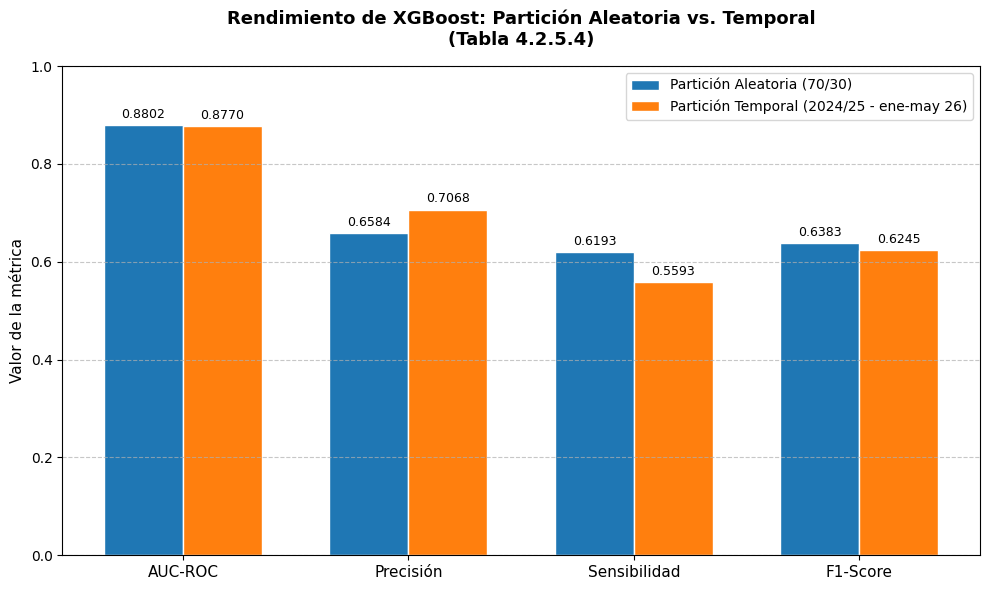

In [132]:
import matplotlib.pyplot as plt
import numpy as np

# ------------------------------------------------------------
# 1. DATOS EXACTOS DE LA TABLA 23
# ------------------------------------------------------------
metricas = ['AUC-ROC', 'Precisión', 'Sensibilidad', 'F1-Score']

# Partición Aleatoria Estratificada (70/30)
valores_aleatoria = [0.8802, 0.6584, 0.6193, 0.6383]

# Partición Temporal (Train: 2024-2025 / Test: ene-may 2026)
valores_temporal = [0.8770, 0.7068, 0.5593, 0.6245]

# ------------------------------------------------------------
# 2. CONFIGURACIÓN DEL GRÁFICO
# ------------------------------------------------------------
x = np.arange(len(metricas))  # Ubicación de las etiquetas en el eje X
width = 0.35                  # Ancho de las barras

fig, ax = plt.subplots(figsize=(10, 6))

# Colores similares a la imagen (Azul y Naranja)
color_aleatoria = '#1f77b4'
color_temporal = '#ff7f0e'

# Crear las barras
barras_aleatoria = ax.bar(x - width/2, valores_aleatoria, width,
                          label='Partición Aleatoria (70/30)',
                          color=color_aleatoria, edgecolor='white')

barras_temporal = ax.bar(x + width/2, valores_temporal, width,
                         label='Partición Temporal (2024/25 - ene-may 26)',
                         color=color_temporal, edgecolor='white')

# ------------------------------------------------------------
# 3. ETIQUETAS DE VALORES SOBRE LAS BARRAS
# ------------------------------------------------------------
def agregar_etiquetas(barras):
    for barra in barras:
        height = barra.get_height()
        # Se formatean a 4 decimales para ser exactos a la tabla
        ax.annotate(f'{height:.4f}',
                    xy=(barra.get_x() + barra.get_width() / 2, height),
                    xytext=(0, 3),
                    textcoords="offset points",
                    ha='center', va='bottom', fontsize=9)

agregar_etiquetas(barras_aleatoria)
agregar_etiquetas(barras_temporal)

# ------------------------------------------------------------
# 4. PERSONALIZACIÓN ESTÉTICA
# ------------------------------------------------------------
ax.set_ylabel('Valor de la métrica', fontsize=11)
ax.set_title('Rendimiento de XGBoost: Partición Aleatoria vs. Temporal\n(Tabla 4.2.5.4)',
             fontsize=13, fontweight='bold', pad=15)

ax.set_xticks(x)
ax.set_xticklabels(metricas, fontsize=11)

# Límites del eje Y (0 a 1 para métricas)
ax.set_ylim(0, 1.0)

# Cuadrícula horizontal
ax.grid(axis='y', linestyle='--', alpha=0.7)

# Leyenda
ax.legend(loc='upper right', fontsize=10)

# Ajustar márgenes
plt.tight_layout()

# Mostrar el gráfico
plt.show()

### Celda 56 — Hiperparámetros óptimos y AUC-ROC en validación cruzada (Tabla 20)

In [133]:
# ============================================================
# TABLA 20: HIPERPARÁMETROS ÓPTIMOS Y AUC-ROC EN VALIDACIÓN CRUZADA
# Pipeline (escalado -> SMOTE -> modelo): SMOTE se aplica SOLO dentro
# de cada fold de entrenamiento, nunca sobre el fold de validación.
# Requiere haber ejecutado antes la Celda de partición temporal (Celda 54),
# que crea X_train_encoded y y_train_temp, y la partición aleatoria
# (X_train, y_train).
# ============================================================
import numpy as np
import pandas as pd
from sklearn.model_selection import StratifiedKFold, cross_val_score
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from imblearn.pipeline import Pipeline as ImbPipeline
from imblearn.over_sampling import SMOTE
from xgboost import XGBClassifier

N_FOLDS = 5
SEMILLA = 42
cv = StratifiedKFold(n_splits=N_FOLDS, shuffle=True, random_state=SEMILLA)

# Modelos con los hiperparámetros óptimos (los mismos usados en el notebook)
modelos = {
    'Regresión Logística': LogisticRegression(max_iter=1000, random_state=SEMILLA),
    'Random Forest': RandomForestClassifier(
        n_estimators=200, max_depth=10, min_samples_split=5,
        min_samples_leaf=2, max_features='sqrt', random_state=SEMILLA),
    'XGBoost': XGBClassifier(
        n_estimators=300, max_depth=5, learning_rate=0.1,
        subsample=1.0, colsample_bytree=1.0,
        random_state=SEMILLA, eval_metric='logloss'),
}

# Espacio de búsqueda (solo descriptivo, para el texto de la tabla)
espacios = {
    'Regresión Logística': "C: [0.01, 0.1, 1, 10]",
    'Random Forest': "n_estimators: [100, 200, 300]; max_depth: [5, 10, 15]; min_samples_split: [2, 5, 10]",
    'XGBoost': "n_estimators: [100, 200, 300]; max_depth: [3, 5, 7]; learning_rate: [0.01, 0.1, 0.2]",
}

hiperparametros_texto = {
    'Regresión Logística': "max_iter=1000, random_state=42",
    'Random Forest': "n_estimators=200, max_depth=10, min_samples_split=5, min_samples_leaf=2, max_features='sqrt'",
    'XGBoost': "n_estimators=300, max_depth=5, learning_rate=0.1, subsample=1.0, colsample_bytree=1.0",
}

def auc_cv(modelo, X, y):
    pipe = ImbPipeline([
        ('escalador', StandardScaler()),
        ('smote', SMOTE(random_state=SEMILLA)),
        ('modelo', modelo),
    ])
    s = cross_val_score(pipe, X, y, cv=cv, scoring='roc_auc', n_jobs=-1)
    return f"{s.mean():.4f} ± {s.std():.4f}"

filas = []
for nombre, modelo in modelos.items():
    filas.append({
        'Modelo': nombre,
        'Hiperparámetros óptimos (Espacio de búsqueda)':
            f"{hiperparametros_texto[nombre]} ({espacios[nombre]})",
        'AUC-ROC CV (Partición Aleatoria)':  auc_cv(modelo, X_train, y_train),
        'AUC-ROC CV (Partición Temporal)':   auc_cv(modelo, X_train_encoded, y_train_temp),
    })

tabla_20 = pd.DataFrame(filas)

print("=" * 80)
print(f"TABLA 20: AUC-ROC EN VALIDACIÓN CRUZADA ({N_FOLDS} folds estratificados, semilla {SEMILLA})")
print("=" * 80)
pd.set_option('display.max_colwidth', None)
print(tabla_20.to_string(index=False))

TABLA 20: AUC-ROC EN VALIDACIÓN CRUZADA (5 folds estratificados, semilla 42)
             Modelo                                                                                                                                       Hiperparámetros óptimos (Espacio de búsqueda) AUC-ROC CV (Partición Aleatoria) AUC-ROC CV (Partición Temporal)
Regresión Logística                                                                                                                              max_iter=1000, random_state=42 (C: [0.01, 0.1, 1, 10])                  0.8565 ± 0.0077                 0.8582 ± 0.0096
      Random Forest n_estimators=200, max_depth=10, min_samples_split=5, min_samples_leaf=2, max_features='sqrt' (n_estimators: [100, 200, 300]; max_depth: [5, 10, 15]; min_samples_split: [2, 5, 10])                  0.8685 ± 0.0095                 0.8705 ± 0.0103
            XGBoost        n_estimators=300, max_depth=5, learning_rate=0.1, subsample=1.0, colsample_bytree=1.0 (n_estimators: 

## Registro del entorno (Celda 57)

### Celda 57 — Registro de versiones del entorno (Python y bibliotecas)
Imprime las versiones instaladas; sirve para completar la Tabla F1 del Anexo F.

In [134]:
# ============================================================
# CELDA 57 — REGISTRO DE VERSIONES DEL ENTORNO
# ============================================================
# Ejecutar al final, en la misma sesión que corrió las Celdas 1–56,
# para que las versiones coincidan con las usadas en los resultados.
import sys
import importlib.metadata as md

print("Python", sys.version.split()[0])
print("-" * 32)
for paquete in ["pandas", "numpy", "matplotlib", "seaborn", "scikit-learn",
                "imbalanced-learn", "xgboost", "shap", "scipy",
                "pymannkendall", "openpyxl"]:
    try:
        print(f"{paquete:<18} {md.version(paquete)}")
    except md.PackageNotFoundError:
        print(f"{paquete:<18} no instalado")

Python 3.13.18
--------------------------------
pandas             2.2.3
numpy              2.1.3
matplotlib         3.10.0
seaborn            0.13.2
scikit-learn       1.6.1
imbalanced-learn   0.14.2
xgboost            3.4.1
shap               0.54.1
scipy              1.16.3
pymannkendall      1.4.3
openpyxl           3.1.5
